# Zeolite classifier + SHAP analysis for *ZeoSyn: A Comprehensive Zeolite Synthesis Dataset Enabling Machine-learning Rationalization of Hydrothermal Parameters*

Elton Pan,† Soonhyoung Kwon,‡ Zach Jensen,† Mingrou Xie,‡ Rafael Gomez-Bombarelli,† Manuel Moliner,¶ Yuriy Roman,‡ and Elsa Olivetti∗,†

† Department of Materials Science and Engineering, Massachusetts Institute of Technology, Cambridge, Massachusetts 02139, United States

‡ Department of Chemical Engineering, Massachusetts Institute of Technology, Cambridge, Massachusetts 02139, United States

¶ Instituto de Tecnolog ́ıa Qu ́ımica, Universitat Politecnica de Valencia-Consejo Superior de
Investigaciones Cient ́ıficas, 46022 Valencia, Spain

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import math
import pickle
import os
import re
import shap
import cmasher as cmr
import imageio as iio
from rdkit import Chem
from rdkit.Chem import Draw, AllChem
from rdkit.Chem.Draw import rdMolDraw2D
from sklearn.manifold import TSNE
from sklearn.preprocessing import OrdinalEncoder
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, RocCurveDisplay, auc
from matplotlib.colors import LogNorm, ListedColormap, LinearSegmentedColormap
from matplotlib import cm
from utils import rename_disordered_interrupted, clean_cbus, cols_to_drop, osda_cols, X_cols, s_pore, m_pore, l_pore, xl_pore, small_cbus, large_cbus

In [2]:
# Load synthesis dataset
df      = pd.read_excel('dataset/ZEOSYN.xlsx')

# Load zeolite structural descriptors
df_zeos = pd.read_csv('dataset/zeolite_descriptors.csv').rename(columns = {'Unnamed: 0': 'Code'})

# Load osda descriptors
df_osda = pd.read_csv('dataset/osda_descriptors.csv').drop(columns = {'Unnamed: 0': 'Code'})

# Merge datasets: Zeolites synthesis + OSDA features

In [3]:
unique_osdas = set(df['osda1 smiles'].value_counts().keys()) |\
set(df['osda2 smiles'].value_counts().keys()) |\
set(df['osda3 smiles'].value_counts().keys())
len(unique_osdas)

921

In [4]:
osda_feat_avail = []
osda_feat_unavail = []
for osda in unique_osdas:
    if osda in list(df_osda['osda smiles']):
        osda_feat_avail.append(osda)
    else:
        osda_feat_unavail.append(osda)
print(len(osda_feat_avail), len(osda_feat_unavail), len(unique_osdas))

815 106 921


In [5]:
# Number of synthesis datapoints without osda featurizations
df[df['osda1 smiles'].isin(osda_feat_unavail) | df['osda2 smiles'].isin(osda_feat_unavail) | df['osda3 smiles'].isin(osda_feat_unavail)]

,Unnamed: 0,Si,Al,P,Na,K,Li,Sr,Rb,Cs,...,osda1 smiles,osda2 smiles,osda3 smiles,osda1 formula,osda2 formula,osda3 formula,Code1,Code2,Code3,year
16,16,0.113122,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,C[N+](C)(C)CCCCCC[N+](C)(C)C.[OH-].[OH-],NaN,NaN,C12H32N2O2,NaN,NaN,ITH,NaN,NaN,2003.0
17,17,0.111732,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,C[N+](C)(C)CCCCCC[N+](C)(C)C.[OH-].[OH-],NaN,NaN,C12H32N2O2,NaN,NaN,ITH,NaN,NaN,2003.0
240,240,0.000000,0.013774,0.082645,0.0,0.0,0.0,0.0,0.0,0.0,...,CC[n+]1ccn(C)c1,NaN,NaN,C6H11N2,NaN,NaN,AEL,NaN,NaN,2015.0
241,241,0.000000,0.000000,0.083773,0.0,0.0,0.0,0.0,0.0,0.0,...,CC[n+]1ccn(C)c1,NaN,NaN,C6H11N2,NaN,NaN,AEL,NaN,NaN,2015.0
243,243,0.139256,0.012672,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,Cc1ccc(Cn2cc[n+](C)c2C)cc1,C[N+](C)(C)C,NaN,C13H17N2,C4H12N,NaN,LTA,NaN,NaN,2017.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30159,30159,0.967742,0.032258,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,CC[N+]1(CC)CC2CC3CC(C2)CC1C3,NaN,NaN,C14H26N,NaN,NaN,CHA,NaN,NaN,2000.0
30160,30160,0.975610,0.024390,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,CC[N+]1(CC)CC2CC3CC(C2)CC1C3,NaN,NaN,C14H26N,NaN,NaN,CHA,NaN,NaN,2000.0
30161,30161,0.985915,0.014085,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,CC[N+]1(CC)CC2CC3CC(C2)CC1C3,NaN,NaN,C14H26N,NaN,NaN,AFI,NaN,NaN,2000.0
30162,30162,0.990099,0.009901,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,CC[N+]1(CC)CC2CC3CC(C2)CC1C3,NaN,NaN,C14H26N,NaN,NaN,AFI,NaN,NaN,2000.0


In [6]:
# Number of synthesis datapoints with osda featurizations
df_with_osda_feats = df[df['osda1 smiles'].isin(osda_feat_avail) | df['osda2 smiles'].isin(osda_feat_avail) | df['osda3 smiles'].isin(osda_feat_avail)]
print('Num. synthesis routes with OSDA features: ', len(df_with_osda_feats))
# Add osda free syntheses
df_osda_free = df[(df['osda1 smiles'].isna()) & (df['osda2 smiles'].isna()) & (df['osda2 smiles'].isna()) & (~df['Si'].isna())]
df_with_osda_feats = pd.concat([df_with_osda_feats, df_osda_free])
print('Num. syn routes OSDA-free: ', len(df_osda_free))
print('Num. total synthesis routes (with OSDA features + OSDA-free): ', len(df_with_osda_feats))
df_with_osda_feats

Num. synthesis routes with OSDA features:  19356
Num. syn routes OSDA-free:  2616
Num. total synthesis routes (with OSDA features + OSDA-free):  21972


,Unnamed: 0,Si,Al,P,Na,K,Li,Sr,Rb,Cs,...,osda1 smiles,osda2 smiles,osda3 smiles,osda1 formula,osda2 formula,osda3 formula,Code1,Code2,Code3,year
0,0,0.030769,0.000000,0.0,0.000000,0.001538,0.000000,0.0,0.000000,0.000000,...,C[N+]12CCCC[C@@H]1[C@H]1C[C@@H](C2)[C@@H]2CCCC...,NaN,NaN,C16H29N2,NaN,NaN,AFI,NaN,NaN,2002.0
1,1,0.105263,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,...,C[N+]12CCCC[C@@H]1[C@H]1C[C@@H](C2)[C@@H]2CCCC...,NaN,NaN,C16H29N2,NaN,NaN,AFI,NaN,NaN,2002.0
2,2,0.021959,0.000000,0.0,0.000000,0.002635,0.000000,0.0,0.000000,0.000000,...,C[N+](C)(C)C12CC3CC(CC(C3)C1)C2,NaN,NaN,C13H24N,NaN,NaN,AFI,NaN,NaN,2002.0
3,3,0.046512,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,...,C[N+](C)(C)C12CC3CC(CC(C3)C1)C2,NaN,NaN,C13H24N,NaN,NaN,AFI,NaN,NaN,2002.0
5,5,0.021368,0.008547,0.0,0.000000,0.000000,0.004274,0.0,0.000000,0.000000,...,CC[N+](CC)(CC)CC,C[N+](C)(C)C,NaN,C8H20N,C4H12N,NaN,BPH,NaN,NaN,2003.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29808,29808,0.000000,0.023585,0.0,0.054245,0.000000,0.000000,0.0,0.000000,0.016509,...,NaN,NaN,NaN,NaN,NaN,NaN,RHO,NaN,NaN,1999.0
29810,29810,0.000000,0.032680,0.0,0.065359,0.000000,0.000000,0.0,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,FAU,NaN,NaN,1999.0
29812,29812,0.000000,0.018519,0.0,0.000000,0.000000,0.018519,0.0,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,ABW,NaN,NaN,2000.0
29814,29814,0.000000,0.032278,0.0,0.047007,0.000000,0.000000,0.0,0.023504,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2000.0


In [7]:
# Select osda features
dfs_with_osda_cols = [] # list of dfs (to be concatenated)
for osda_col in osda_cols:
    df_with_osda_col = df_osda.loc[:, df_osda.columns.str.contains(osda_col)] # one df containing that column
    dfs_with_osda_cols.append(df_with_osda_col)
dfs_with_osda_cols.append(df_osda.loc[:, df_osda.columns.str.contains('osda smiles')])

df_selected_osda_cols = pd.concat(dfs_with_osda_cols, axis = 1) # concat these dfs
df_selected_osda_cols # df of osdas with features in osda_cols variable

,asphericity_mean_0,asphericity_std_0,axes_mean_0,axes_mean_1,axes_std_0,axes_std_1,bertz_ct_mean_0,eccentricity_mean_0,eccentricity_std_0,formal_charge,...,whim_mean_105,whim_mean_106,whim_mean_107,whim_mean_108,whim_mean_109,whim_mean_110,whim_mean_111,whim_mean_112,whim_mean_113,osda smiles
0,0.833046,0.090677,2.844355,5.873985,0.344235,0.687441,188.361619,0.997548,0.002453,0,...,0.506714,0.529286,10.965571,14.641857,10.375429,11.372000,11.822286,11.203857,12.580714,BrCCCCBr
1,0.862392,0.008930,4.911553,18.135735,0.236299,0.106522,1761.127185,0.998815,0.000150,2,...,0.540200,0.477300,201.261200,112.928400,145.588100,197.331400,161.063400,207.634000,182.704900,C(CCCC[N+]12CCC(CC1)CC2)CCC[N+]12CCC(CC1)CC2
2,0.871083,0.011571,4.909037,16.996942,0.214486,0.395254,1677.990439,0.998962,0.000191,2,...,0.550375,0.486500,195.761375,111.017625,142.011250,191.894875,156.960875,201.762000,177.661750,C(CCCC[N+]12CCN(CC1)CC2)CCC[N+]12CCN(CC1)CC2
3,0.827862,0.010274,4.521435,15.865518,0.162815,0.136168,1570.117276,0.998080,0.000244,2,...,0.556100,0.487150,150.820550,81.970050,107.526400,147.553550,119.707300,155.615100,136.211650,C(CCC[N+]12CCC(CC1)CC2)CC[N+]12CCC(CC1)CC2
4,0.846011,0.018141,4.870309,16.364766,0.434798,0.258982,1584.716532,0.998478,0.000403,2,...,0.553500,0.491250,176.277750,101.413250,128.584750,172.836500,141.807000,181.597750,160.566000,C(CCC[N+]12CCN(CC1)CC2)CCC[N+]12CCN(CC1)CC2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
838,0.334574,0.070111,6.744544,10.353599,0.451135,0.495314,1031.770424,0.944772,0.023241,0,...,0.509391,0.386565,76.609087,43.799130,55.770652,72.874826,62.931522,79.027087,60.637739,c1ccc2c(c1)OCCOCCOCCOCCO2
839,0.445281,0.120964,7.320686,13.834375,0.460630,1.445857,1435.155855,0.960395,0.047998,0,...,0.485884,0.380767,148.158814,88.934488,111.403186,140.810047,124.675349,152.258953,118.900930,c1ccc2c(c1)OCCOCCOc1ccccc1OCCOCCO2
840,0.473344,0.000000,7.100301,11.389339,0.000000,0.000000,1660.979191,0.973860,0.000000,0,...,0.573000,0.452000,51.201000,28.138000,33.756000,50.089000,37.100000,54.878000,42.793000,c1ccc2c(c1)cc1ccc3cccc4ccc2c1c34
841,0.570104,0.000000,4.978538,9.194406,0.000000,0.000000,934.634999,0.984861,0.000000,0,...,0.529000,0.417000,28.916000,15.015000,18.676000,28.069000,20.837000,30.728000,22.907000,c1ccc2nc3ccccc3cc2c1


In [8]:
# Merge: 1) df of synthesis with osda featurizations 2) df of osdas with features in osda_cols variable

# Add OSDA1 first
df_syn_osda = df_with_osda_feats.merge(df_selected_osda_cols.add_prefix('osda1_'), left_on='osda1 smiles', right_on='osda1_osda smiles', how = 'outer')
df_syn_osda = df_syn_osda[~df_syn_osda['Unnamed: 0'].isna()] # Since the line above is an 'outer' merge, need to retain only the rows of the left df

# then add OSDA2 to df_syn_osda
df_syn_osda = df_syn_osda.merge(df_selected_osda_cols.add_prefix('osda2_'), left_on='osda2 smiles', right_on='osda2_osda smiles', how = 'outer')
df_syn_osda = df_syn_osda[~df_syn_osda['Unnamed: 0'].isna()] # Since the line above is an 'outer' merge, need to retain only the rows of the left df

# then add OSDA3 to df_syn_osda
df_syn_osda = df_syn_osda.merge(df_selected_osda_cols.add_prefix('osda3_'), left_on='osda3 smiles', right_on='osda3_osda smiles', how = 'outer')
df_syn_osda = df_syn_osda[~df_syn_osda['Unnamed: 0'].isna()] # Since the line above is an 'outer' merge, need to retain only the rows of the left df

# Replace NaN in osda featurizations with 0
for osda_col in osda_cols:
    df_syn_osda.loc[:, df_syn_osda.columns.str.contains(osda_col)] = df_syn_osda.loc[:, df_syn_osda.columns.str.contains(osda_col)].fillna(0)

# Drop columns
df_syn_osda = df_syn_osda.drop(columns=[
                                        'Unnamed: 0',
                                        'osda1_osda smiles', 
                                        'osda2_osda smiles', 
                                        'osda3_osda smiles'
                                       ])

df_syn_osda

,Si,Al,P,Na,K,Li,Sr,Rb,Cs,Ba,...,osda3_whim_mean_104,osda3_whim_mean_105,osda3_whim_mean_106,osda3_whim_mean_107,osda3_whim_mean_108,osda3_whim_mean_109,osda3_whim_mean_110,osda3_whim_mean_111,osda3_whim_mean_112,osda3_whim_mean_113
0,0.030769,0.000000,0.0,0.000000,0.001538,0.000000,0.0,0.0,0.0,0.0,...,0.000,0.000,0.000,0.0,0.000,0.000,0.000,0.000,0.000,0.000
1,0.105263,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0.000,0.000,0.000,0.0,0.000,0.000,0.000,0.000,0.000,0.000
2,0.235149,0.009901,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0.000,0.000,0.000,0.0,0.000,0.000,0.000,0.000,0.000,0.000
3,0.031646,0.000000,0.0,0.000000,0.000000,0.003165,0.0,0.0,0.0,0.0,...,0.000,0.000,0.000,0.0,0.000,0.000,0.000,0.000,0.000,0.000
4,0.024450,0.000000,0.0,0.000000,0.000000,0.002445,0.0,0.0,0.0,0.0,...,0.000,0.000,0.000,0.0,0.000,0.000,0.000,0.000,0.000,0.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21967,0.033629,0.002220,0.0,0.017151,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0.324,0.453,0.381,27.2,12.084,17.712,26.445,20.426,28.203,23.887
21968,0.033575,0.002216,0.0,0.017123,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0.324,0.453,0.381,27.2,12.084,17.712,26.445,20.426,28.203,23.887
21969,0.033536,0.002247,0.0,0.019451,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0.324,0.453,0.381,27.2,12.084,17.712,26.445,20.426,28.203,23.887
21970,0.033381,0.002237,0.0,0.018026,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0.324,0.453,0.381,27.2,12.084,17.712,26.445,20.426,28.203,23.887


# Process data for multi-class classification

In [9]:
# Drop columns
X = df_syn_osda.drop(columns = cols_to_drop)

# Imputation for cryst_time (1412/21972 has NaN) and cryst_temp (554/21972 has NaN)
columns = list(X.columns) # Save columns
imp = IterativeImputer(min_value = 0., sample_posterior = True, skip_complete = True, random_state=0) # Sample posterior to get a distribution, skip_complete to speed up, min value is 0. since time and temp are +ve
imp.fit(X)
X = pd.DataFrame(imp.transform(X))
X.columns = columns # Assign columns back

X_y = X
X_y['Code1'] = df_syn_osda['Code1']

# Empty 'Code1' element means amorphous/dense phases - replace with 'Failed'
X_y['Code1'] = X_y['Code1'].fillna('Failed')
X_y['Code1'].isna().sum()

# Define X and y
X = X_y.drop(columns = ['Code1'])
y = X_y['Code1']

# Feature selection
X = X[X_cols.keys()]
X.columns = X_cols.values()

In [10]:
X

,Si,Al,P,Na,K,Li,Sr,Rb,Cs,Ba,...,OSDA SASA,OSDA molecular weight,OSDA NPR 1,OSDA NPR 2,OSDA rotatable bonds,OSDA PMI 1,OSDA PMI 2,OSDA PMI 3,OSDA sphericity,OSDA volume
0,0.030769,0.000000,0.0,0.000000,0.001538,0.000000,0.0,0.0,0.0,0.0,...,449.104959,249.422,0.353980,0.922428,0.0,608.687149,1603.824715,1734.842649,0.462945,263.228000
1,0.105263,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,...,449.104959,249.422,0.353980,0.922428,0.0,608.687149,1603.824715,1734.842649,0.462945,263.228000
2,0.235149,0.009901,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,...,449.104959,249.422,0.353980,0.922428,0.0,608.687149,1603.824715,1734.842649,0.462945,263.228000
3,0.031646,0.000000,0.0,0.000000,0.000000,0.003165,0.0,0.0,0.0,0.0,...,449.104959,249.422,0.353980,0.922428,0.0,608.687149,1603.824715,1734.842649,0.462945,263.228000
4,0.024450,0.000000,0.0,0.000000,0.000000,0.002445,0.0,0.0,0.0,0.0,...,449.104959,249.422,0.353980,0.922428,0.0,608.687149,1603.824715,1734.842649,0.462945,263.228000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21967,0.033629,0.002220,0.0,0.017151,0.000000,0.000000,0.0,0.0,0.0,0.0,...,357.916974,142.266,0.572966,0.638424,0.0,364.200627,405.808505,635.641019,0.426424,166.890667
21968,0.033575,0.002216,0.0,0.017123,0.000000,0.000000,0.0,0.0,0.0,0.0,...,357.916974,142.266,0.572966,0.638424,0.0,364.200627,405.808505,635.641019,0.426424,166.890667
21969,0.033536,0.002247,0.0,0.019451,0.000000,0.000000,0.0,0.0,0.0,0.0,...,357.916974,142.266,0.572966,0.638424,0.0,364.200627,405.808505,635.641019,0.426424,166.890667
21970,0.033381,0.002237,0.0,0.018026,0.000000,0.000000,0.0,0.0,0.0,0.0,...,357.916974,142.266,0.572966,0.638424,0.0,364.200627,405.808505,635.641019,0.426424,166.890667


In [11]:
y

0           AFI
1           AFI
2        ITQ-21
3           CFI
4           CFI
          ...  
21967       MOR
21968       MOR
21969       AEI
21970       AEI
21971       AEI
Name: Code1, Length: 21972, dtype: object

# Training classifier

In [12]:
# With val set
random_state = 0
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state = random_state)
X_train, X_val, y_train, y_val   = train_test_split(X_train, y_train, test_size=0.125, random_state = random_state)
print(len(X_train), len(X_test), len(X_val), len(y_train), len(y_test), len(y_val) )

15379 4395 2198 15379 4395 2198


In [13]:
model = RandomForestClassifier(max_depth = None, random_state = random_state)
model.fit(pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))

# Calculate metrics with results
y_pred = model.predict(X_test)
results = classification_report(y_test, y_pred, output_dict = True) 

print('======MODEL PERFORMANCE METRICS======')
print('acc: ', results['accuracy'])
print('macro avg:', results['macro avg'])

======MODEL PERFORMANCE METRICS======
acc:  0.7358361774744028
macro avg: {'precision': 0.6336443491783315, 'recall': 0.6474391362221403, 'f1-score': 0.6232778595020666, 'support': 4395}


Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.


In [14]:
# Save/load classification model
# with open('model/classifier.pkl', 'wb') as handle:
#     pickle.dump(model, handle, protocol=pickle.HIGHEST_PROTOCOL)
# with open('model/classifier.pkl', 'rb') as handle:
#     model = pickle.load(handle)

## Confusion matrix for most frequent frameworks

You are modifying the state of a globally registered colormap. This has been deprecated since 3.3 and in 3.6, you will not be able to modify a registered colormap in-place. To remove this warning, you can make a copy of the colormap first. cmap = mpl.cm.get_cmap("Blues").copy()


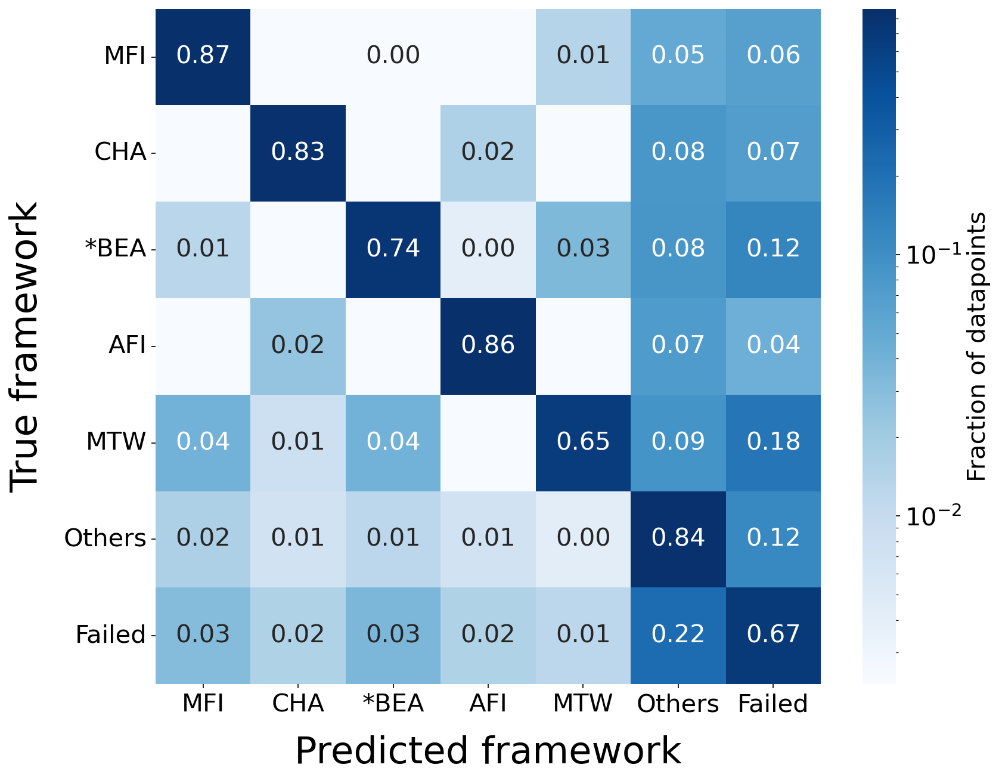

In [15]:
n = 5
top_n_zeos = df['Code1'].value_counts()[:n].index.to_list()

# Pool function - pool classes as most frequent frameworks, other crystalline, failed
def pool_func(zeo):
    if zeo in top_n_zeos:
        return zeo
    elif zeo == 'Failed':
        return 'Failed'
    else:
        return 'Others'

y_test_pooled = y_test.apply(pool_func)
y_pred_pooled = list(map(pool_func, y_pred))

# Distribution of pooled classes
y_pooled = y.apply(pool_func)
y_pooled.value_counts()

# Confusion matrix
cm_main = confusion_matrix(y_test_pooled, y_pred_pooled, labels = top_n_zeos + ['Others', 'Failed'])
cm_df = pd.DataFrame(cm_main, index = top_n_zeos + ['Others', 'Failed'], columns = top_n_zeos + ['Others', 'Failed'])
cm_df = cm_df.divide(cm_df.sum(1), axis = 'rows') # Normalize

#Plotting the confusion matrix
plt.figure(figsize=(12,10), dpi = 150)
cmap = mpl.cm.Blues
cmap.set_bad(color=cmap(0))

ax = sns.heatmap(cm_df, annot=True, 
                 norm=LogNorm(), 
                 cmap = cmap, fmt='.2f', annot_kws={"fontsize":20})

cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=20)
cbar.set_label('Fraction of datapoints', fontsize = 20)
plt.ylabel('True framework', fontsize = 30, labelpad = 15)
plt.xlabel('Predicted framework', fontsize = 30, labelpad = 15)
plt.xticks(fontsize = 20, rotation = 0)
plt.yticks(fontsize = 20, rotation = 0)
plt.show()

## Confusion matrix for specific small/medium/large/extra-large pore 

You are modifying the state of a globally registered colormap. This has been deprecated since 3.3 and in 3.6, you will not be able to modify a registered colormap in-place. To remove this warning, you can make a copy of the colormap first. cmap = mpl.cm.get_cmap("Blues").copy()


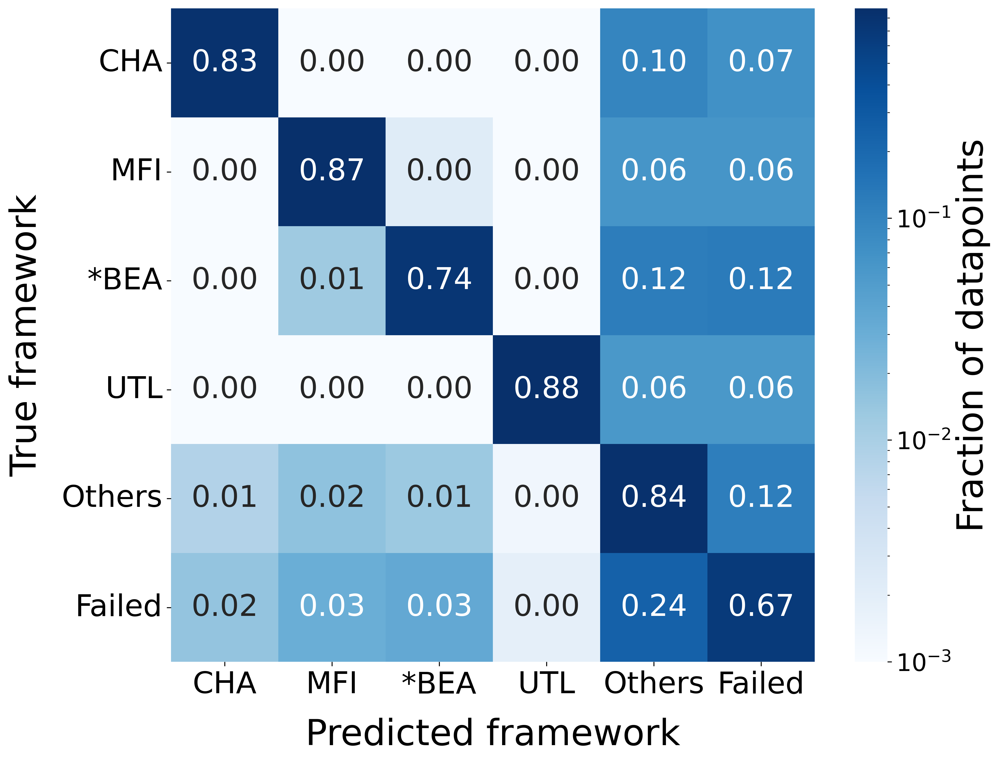

In [16]:
# Pool function - pool classes as zeos of interest, crystalline (others), failed
pool_func = lambda x: x if x in (['CHA', 'MFI', '*BEA', 'UTL', 'Failed']) else 'Others'
y_test_pooled = y_test.apply(pool_func)
y_pred_pooled = list(map(pool_func, y_pred))

# Distribution of pooled classes
y_pooled = y.apply(pool_func)
y_pooled.value_counts()

# Confusion matrix
cm_main = confusion_matrix(y_test_pooled, y_pred_pooled, labels = ['CHA', 'MFI', '*BEA', 'UTL', 'Others', 'Failed'])
cm_df = pd.DataFrame(cm_main, index = ['CHA', 'MFI', '*BEA', 'UTL', 'Others', 'Failed'], columns = ['CHA', 'MFI', '*BEA', 'UTL', 'Others', 'Failed'])
cm_df = cm_df.divide(cm_df.sum(1), axis = 'rows') # Normalize

cm_df = cm_df.replace(0., 0.001) # replace zeros with small number

#Plotting the confusion matrix
plt.figure(figsize=(12,10), dpi = 300)
cmap = mpl.cm.Blues
cmap.set_bad(color=cmap(0))

ax = sns.heatmap(cm_df, annot=True, 
                 norm=LogNorm(),
                 cmap = cmap, fmt='.2f', annot_kws={"fontsize":25})

cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=20)
cbar.set_label('Fraction of datapoints', fontsize = 30)
plt.ylabel('True framework', fontsize = 30, labelpad = 15)
plt.xlabel('Predicted framework', fontsize = 30, labelpad = 15)
plt.xticks(fontsize = 25)
plt.yticks(fontsize = 25, rotation = 0)
plt.show()

## Confusion matrix for small/medium/large/extra-large pore

You are modifying the state of a globally registered colormap. This has been deprecated since 3.3 and in 3.6, you will not be able to modify a registered colormap in-place. To remove this warning, you can make a copy of the colormap first. cmap = mpl.cm.get_cmap("Blues").copy()


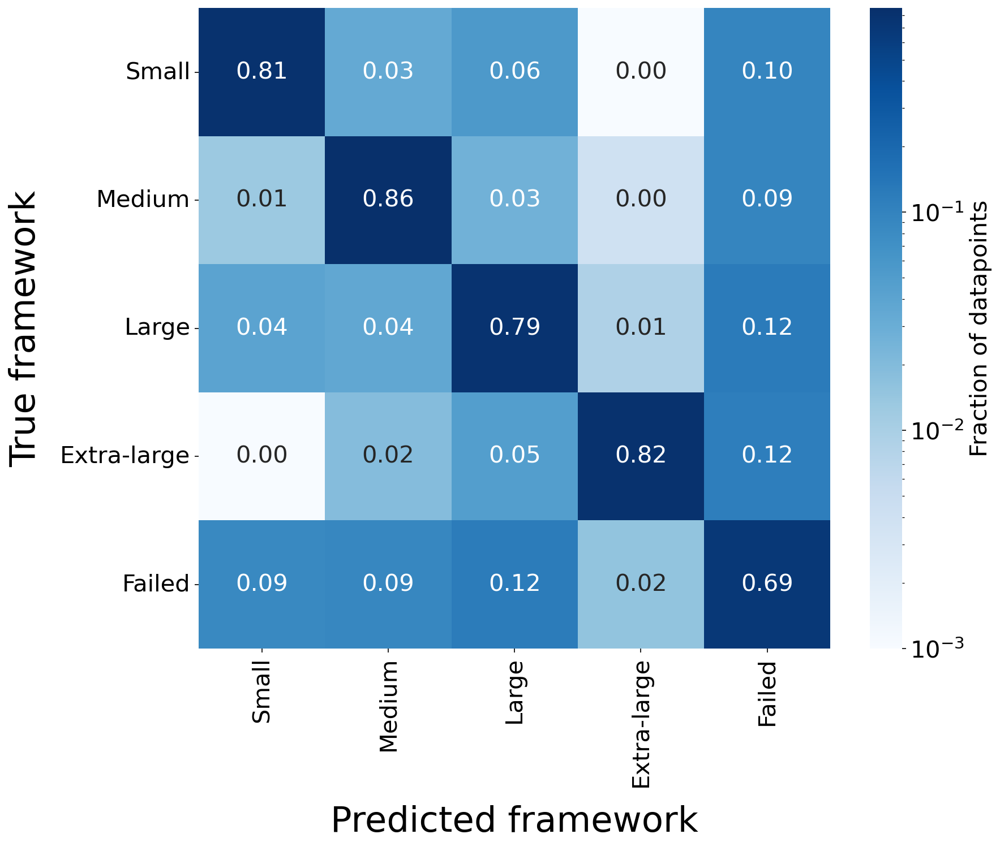

In [17]:
# Pool function - pool classes as zeos of interest, crystalline (others), failed
def pool_func(zeo):
    if zeo in s_pore:
        return 'Small'
    elif zeo in m_pore:
        return 'Medium'
    elif zeo in l_pore:
        return 'Large'
    elif zeo in xl_pore:
        return 'Extra-large'
    elif zeo == 'Failed':
        return 'Failed'
    else:
        return 'Others'

y_test_pooled = y_test.apply(pool_func)
y_pred_pooled = list(map(pool_func, y_pred))

# Distribution of pooled classes
y_pooled = y.apply(pool_func)
y_pooled.value_counts()

# Confusion matrix
cm_main = confusion_matrix(y_test_pooled, y_pred_pooled, labels = ['Small', 'Medium', 'Large', 'Extra-large', 
                                                                   'Failed'])
cm_df = pd.DataFrame(cm_main, index = ['Small', 'Medium', 'Large', 'Extra-large', 
                                       'Failed'], columns = ['Small', 'Medium', 'Large', 'Extra-large', 
                                                             'Failed'])
cm_df = cm_df.divide(cm_df.sum(1), axis = 'rows') # Normalize

cm_df = cm_df.replace(0., 0.001) # replace zeros with small number

#Plotting the confusion matrix
plt.figure(figsize=(12,10), dpi = 150)
cmap = mpl.cm.Blues
cmap.set_bad(color=cmap(0))

ax = sns.heatmap(cm_df, annot=True, 
                 norm=LogNorm(), 
                 cmap = cmap, fmt='.2f', annot_kws={"fontsize":20})

cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=20)
cbar.set_label('Fraction of datapoints', fontsize = 20)
plt.ylabel('True framework', fontsize = 30, labelpad = 15)
plt.xlabel('Predicted framework', fontsize = 30, labelpad = 15)
plt.xticks(fontsize = 20, rotation = 90)
plt.yticks(fontsize = 20, rotation = 0)
plt.show()

## Confusion matrix for d6r ABC zeolites

In [18]:
# https://asia.iza-structure.org/IZA-SC/intergrowth_families/ABC_6.pdf
ABC = ['CAN', 'SOD', 'LOS', 'LIO', 'AFG', 'FRA', 'OFF', 'ERI', 'EAB', 'LEV', 'SAT', 'GME', 'CHA', 'AFX', 'AFT']
ABC = [x for x in ABC if x in y_test.values]
ABC

['CAN', 'SOD', 'LOS', 'OFF', 'ERI', 'LEV', 'GME', 'CHA', 'AFX']

You are modifying the state of a globally registered colormap. This has been deprecated since 3.3 and in 3.6, you will not be able to modify a registered colormap in-place. To remove this warning, you can make a copy of the colormap first. cmap = mpl.cm.get_cmap("Blues").copy()


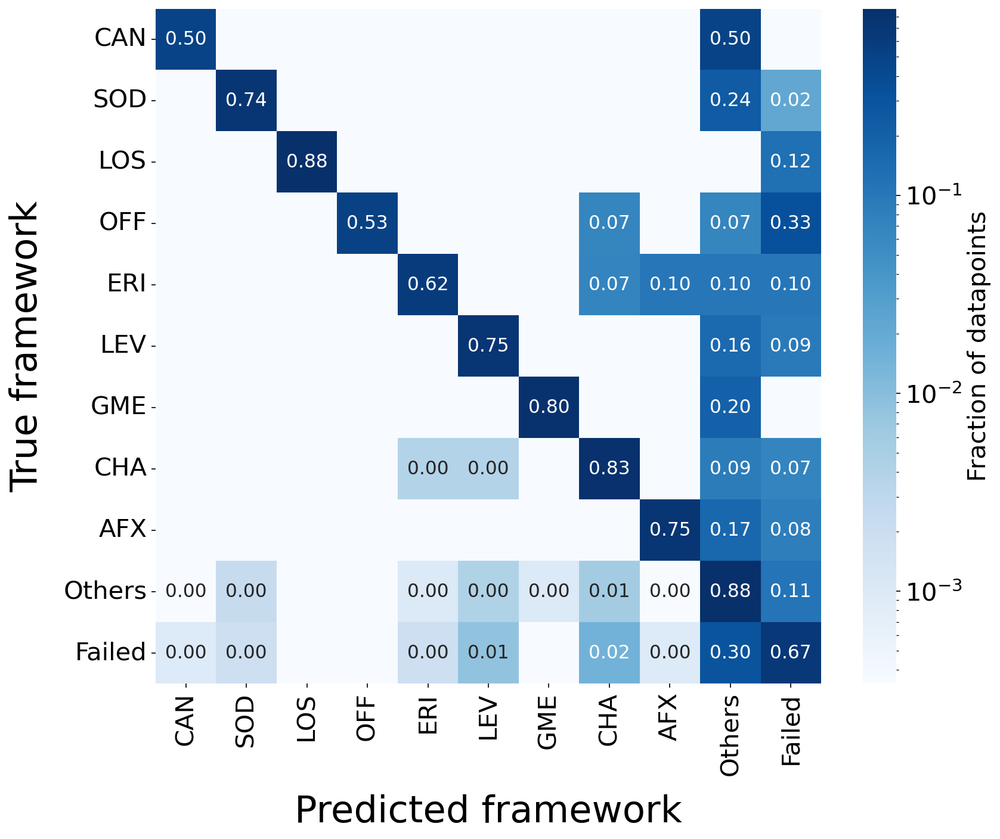

In [19]:
# Pool function - pool classes as zeos of interest, crystalline (others), failed
pool_func = lambda x: x if x in (ABC + ['Failed']) else 'Others'
y_test_pooled = y_test.apply(pool_func)
y_pred_pooled = list(map(pool_func, y_pred))

# Distribution of pooled classes
y_pooled = y.apply(pool_func)
y_pooled.value_counts()

# Confusion matrix
cm_main = confusion_matrix(y_test_pooled, y_pred_pooled, labels = ABC + ['Others', 'Failed'])
cm_df = pd.DataFrame(cm_main, index = ABC + ['Others', 'Failed'], columns = ABC + ['Others', 'Failed'])
cm_df = cm_df.divide(cm_df.sum(1), axis = 'rows') # Normalize


#Plotting the confusion matrix
plt.figure(figsize=(12,10), dpi = 150)
cmap = mpl.cm.Blues
cmap.set_bad(color=cmap(0))

ax = sns.heatmap(cm_df, annot=True, norm=LogNorm(), cmap = cmap, fmt='.2f', annot_kws={"fontsize":15})

cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=20)
cbar.set_label('Fraction of datapoints', fontsize = 20)
plt.ylabel('True framework', fontsize = 30, labelpad = 15)
plt.xlabel('Predicted framework', fontsize = 30, labelpad = 15)
plt.xticks(fontsize = 20, rotation = 90)
plt.yticks(fontsize = 20, rotation = 0)
plt.show()

# SHAP analysis

In [20]:
# Define custom color map
color_range = (0, 0.75) # user-defined range of colormaps, max range is (0,1)

top = cm.get_cmap('Blues_r', 128) # top colormap (reversed)
bottom = cm.get_cmap('Oranges', 128) # bottom colormap
colors = np.vstack((top(np.linspace(1-color_range[1], 1-color_range[0], 128)),
                       bottom(np.linspace(color_range[0], color_range[1], 128))))
cmap = ListedColormap(colors, name='OrangeBlue')

In [21]:
# Calculate SHAP values - Note: takes about 2h 

# explainer = shap.TreeExplainer(model)
# shap_values = explainer.shap_values(X_test)
# shap_values[0].shape

In [22]:
# Save/load SHAP values - Note: Please download and place shap_values.pkl (https://figshare.com/s/5519f7668ff2f631f47f) in the shap/ directory
# with open('shap/shap_values.pkl', 'wb') as handle:
#     pickle.dump(shap_values, handle, protocol=pickle.HIGHEST_PROTOCOL)
with open('shap/shap_values.pkl', 'rb') as handle:
    shap_values = pickle.load(handle)

In [23]:
# Mask out non-relevant features
shap_cols     = [] # columns to remain
shap_col_idxs = [] # their indices
for col_idx, col in enumerate(X_test.columns):
        shap_cols.append(col)
        shap_col_idxs.append(col_idx)

shap_values_masked = [x[:,shap_col_idxs] for x in shap_values]
X_test_masked      = X_test[shap_cols]
X_test_masked.columns = X_cols.values()
shap_values_masked[0].shape, X_test_masked.shape

((4395, 43), (4395, 43))

## Framework-level SHAP

In [24]:
def plot_zeo_shap(zeo, cols, max_display = 5, plot_size = (8,5), xlim = None, alpha = 0.1, cmap = 'coolwarm', xlabel_size = None, color_bar = True, sort = True, return_top_shap_feats = False, savepath = None):
    '''
    Plots SHAP plot for a specific zeolite
    
    Args:
    zeo: zeolite 3-letter code
    cols: synthesis feature columns to consider
    '''
    
    zeo_idx = np.where(model.classes_ == zeo)[0][0] # Find class index
    
    zeo_shap = pd.DataFrame(shap_values_masked[zeo_idx], columns = X_cols.values())[cols]  # Get SHAP values for zeo
    
    # Summary plot
    plt.figure(dpi = 300)
    shap.summary_plot(np.array(zeo_shap), X_test_masked[cols],
                    max_display = max_display,
                    cmap = cmap,
                    show = False, 
                    alpha = alpha, 
                    color_bar = color_bar,
                    color_bar_label='Synthesis parameter',
                    plot_size = plot_size,
                    sort = sort,
                     )

    fig, ax = plt.gcf(), plt.gca()

    ax.set_xlabel('SHAP contribution to \n' + r'$\bf{' + zeo + '}$ formation', fontsize = xlabel_size)
    plt.xticks(fontsize=15)
    
    if xlabel_size != None:
        ax.tick_params(axis='y', which='major', labelsize=xlabel_size)
    
    top_shap_feat = ax.get_yticklabels()[-1].get_text() # str of feature name
    top_shap_feat_ub = np.quantile(zeo_shap[top_shap_feat], 0.99)*1.2 # upper
    top_shap_feat_lb = np.quantile(zeo_shap[top_shap_feat], 0.01)*1.2 # lower

    if xlim != None:
        ax.set_xlim(*xlim)
    else:
        ax.set_xlim(-max([top_shap_feat_ub, top_shap_feat_lb]), max([top_shap_feat_ub, top_shap_feat_lb]))
    
    plt.xticks([0.])
    
    if savepath != None:
        plt.savefig(savepath, dpi = 200)
    
    if return_top_shap_feats: # return a list of top SHAP features
        top_shap_feats = [ax.get_yticklabels()[-i].get_text() for i in range(max_display)]
        plt.close(fig)
        return top_shap_feats
    else:
        plt.show()

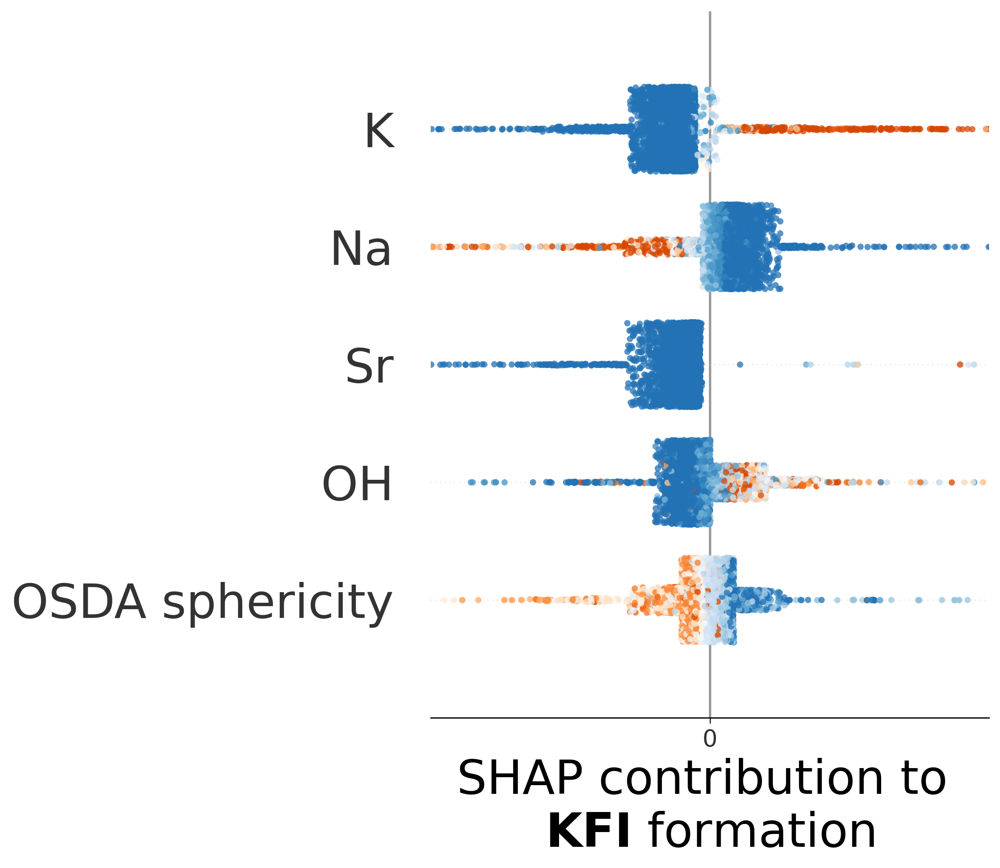

In [25]:
# Framework-level SHAP example
plot_zeo_shap('KFI', cols = X_cols.values(), cmap = cmap, alpha = 0.75, max_display = 5, plot_size = (7,7), xlabel_size = 30, color_bar = False)

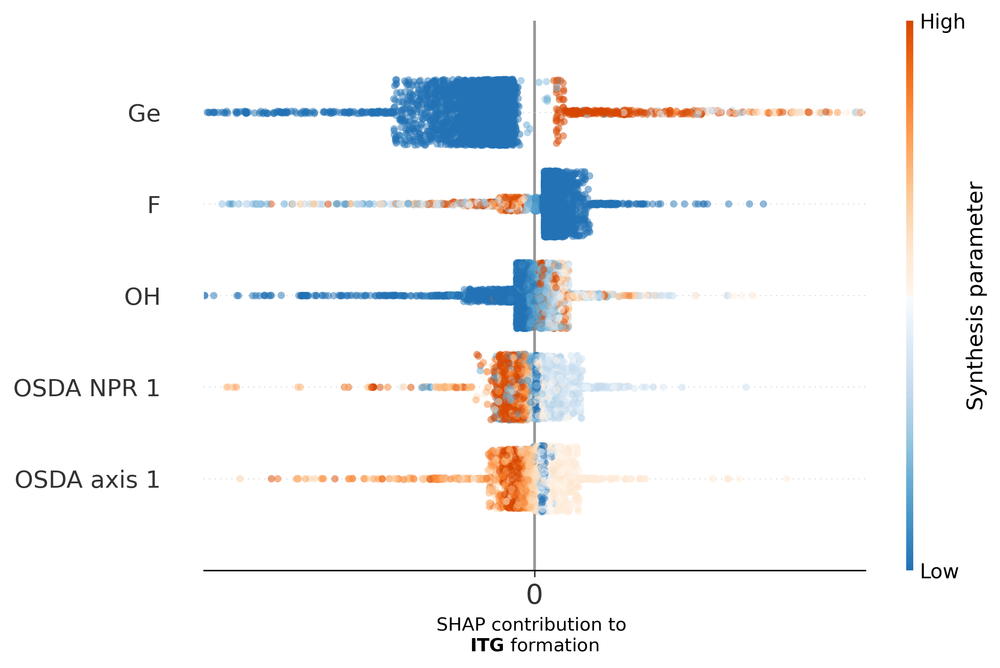

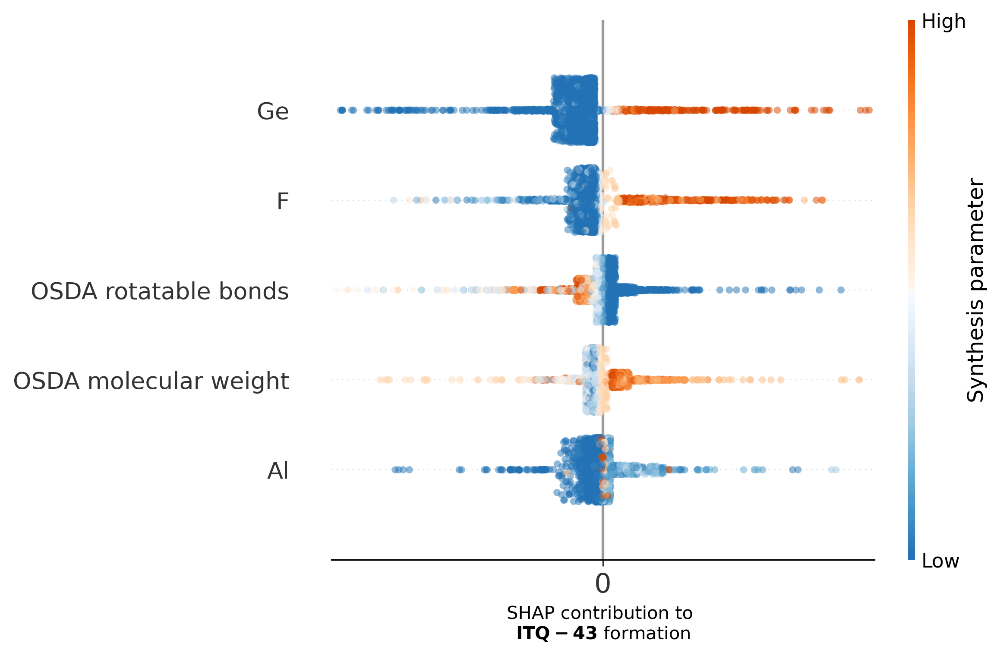

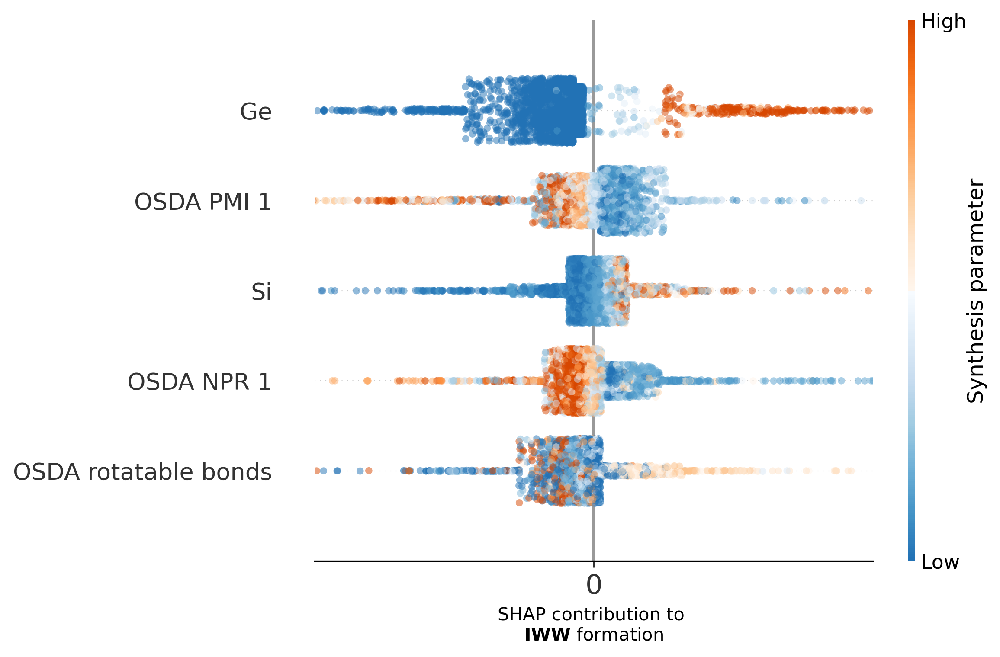

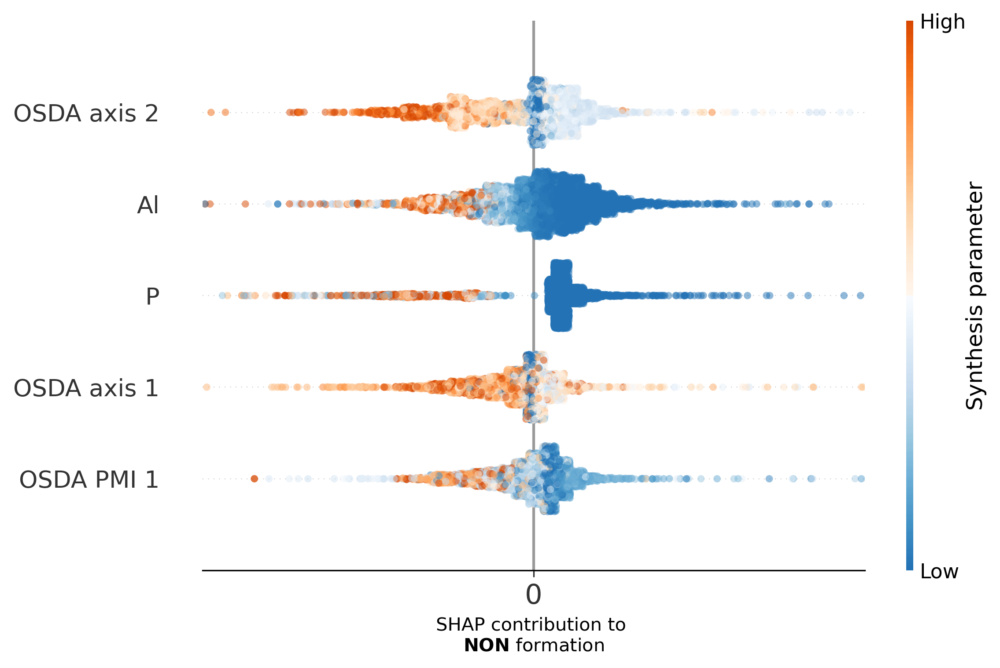

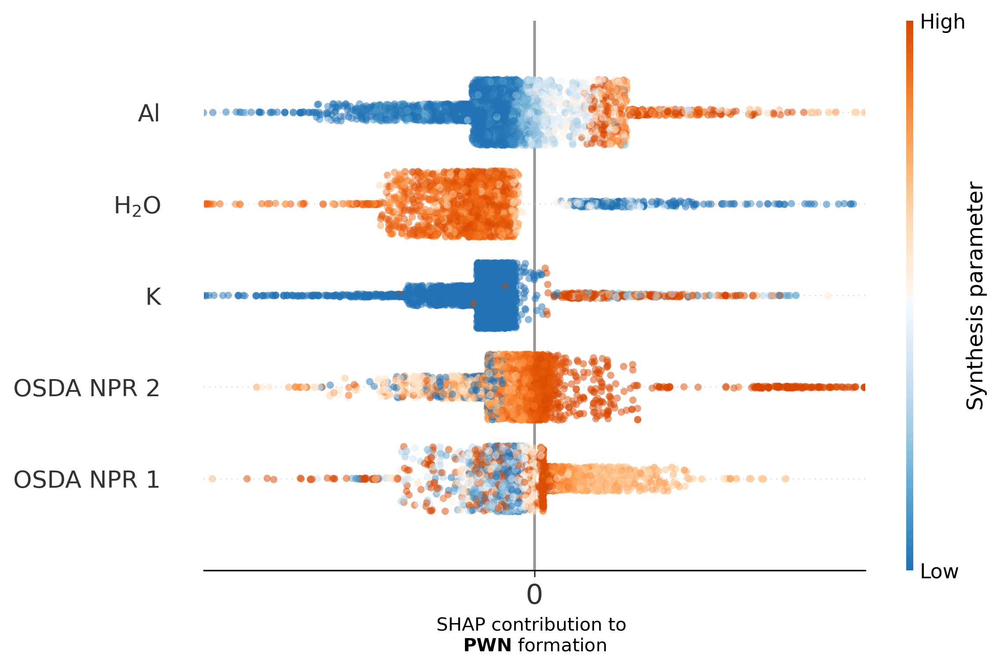

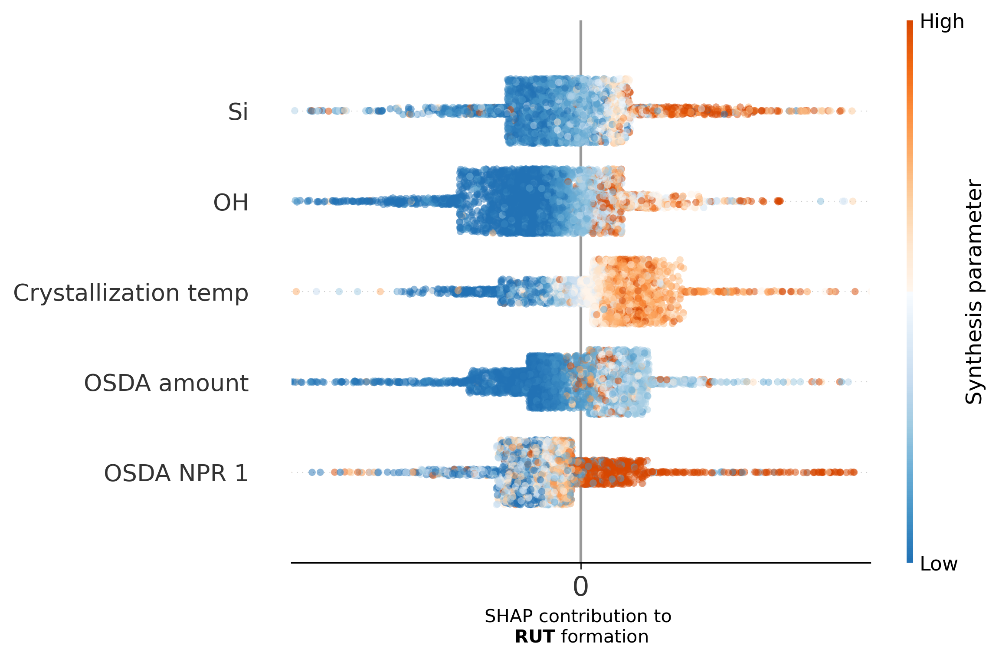

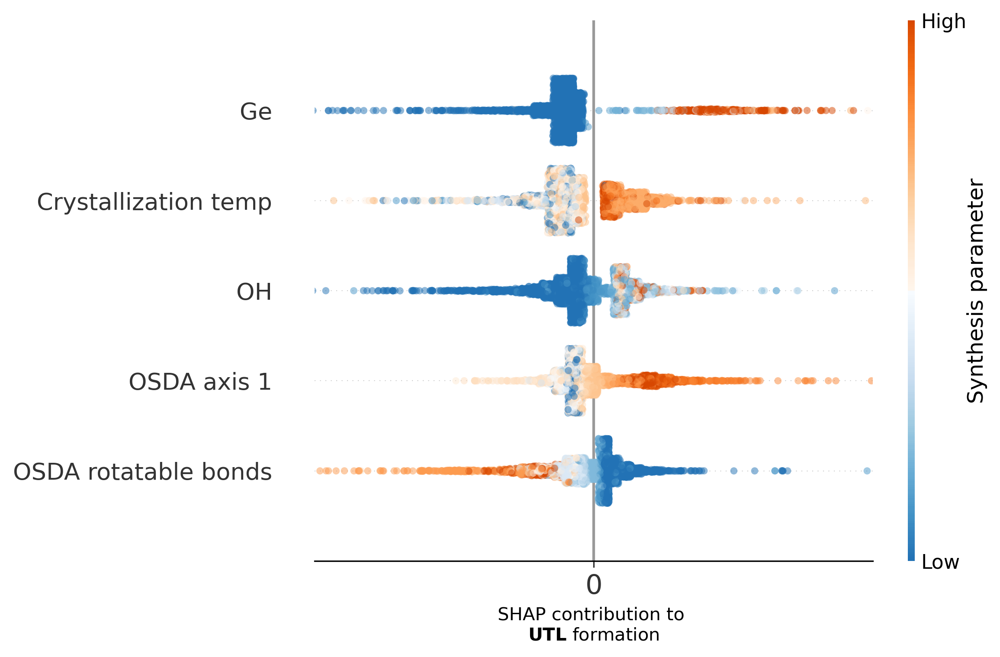

In [26]:
zeos_gel_dominated  = ["-LIT", "ASU-14", "BEC", "BPH", "CAN", "CAS", "CDO", "CGS", "ETR", "HEU",  "JBW", "KFI", "LTJ", "LTL", "ZON"]
zeos_osda_dominated = ["*-ITN", "*-SVY", "*BEA", "*CTH", "*MRE", "*SFV", "*STO", "-IFT", "CFI", "CON", "ESV", "IFR", "ISV", "ITE", "ITQ-21", "ITR", "ITT", "MEL", "NSI"]
zeos_both_dominated = ["ITG", "ITQ-43", "IWW", "NON", "PWN", "RUT", "UTL"]

for zeo in zeos_both_dominated:
    plot_zeo_shap(zeo, cols = X_cols.values(), cmap = cmap, alpha = 0.5)

In [27]:
# # Generate individual framework-level SHAP plots for all frameworks

# for zeo in sorted(s_pore+m_pore+l_pore+xl_pore):
#     print(zeo)
#     try:
#         plot_zeo_shap(zeo, cols = X_cols.values(), cmap = cmap, alpha = 0.75, max_display = 10, plot_size = (4,3), xlabel_size = 10, color_bar = False, savepath = f"framework/framework_shap/{zeo}.png")
#     except:
#         print('framework not present')

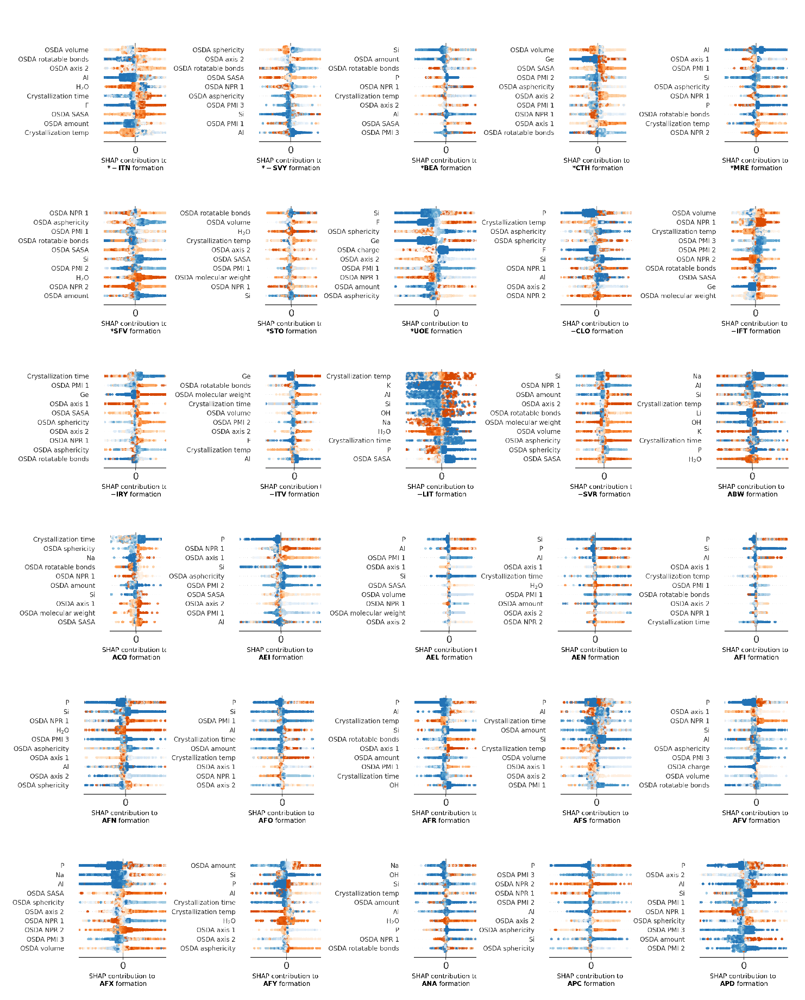

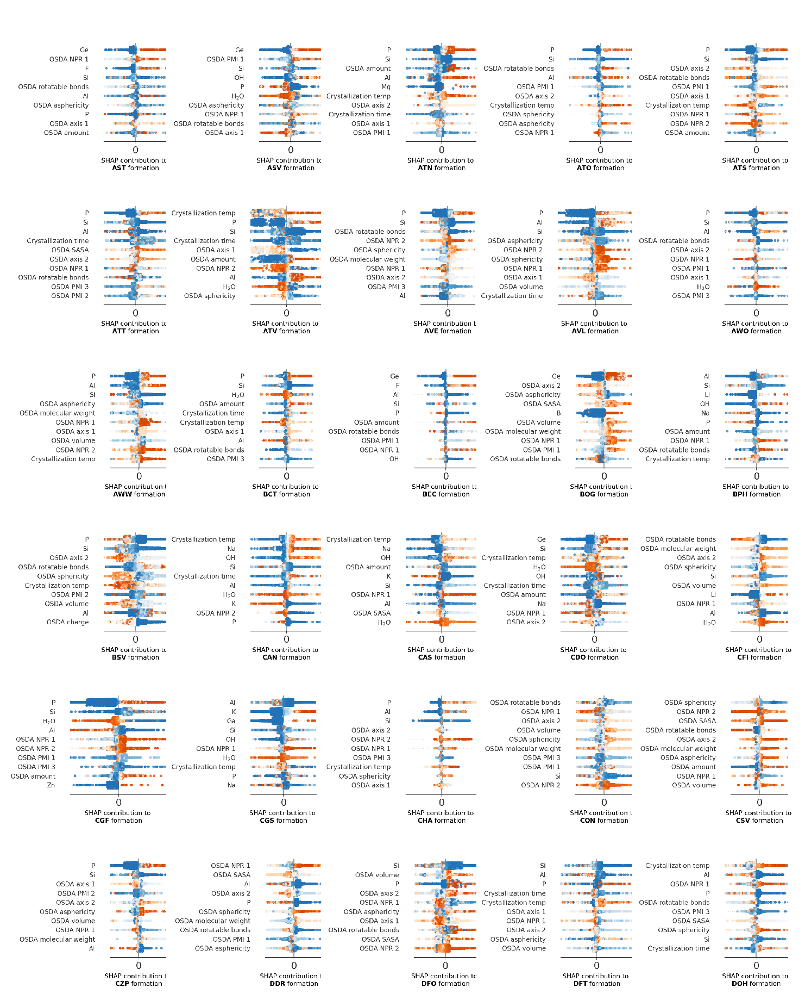

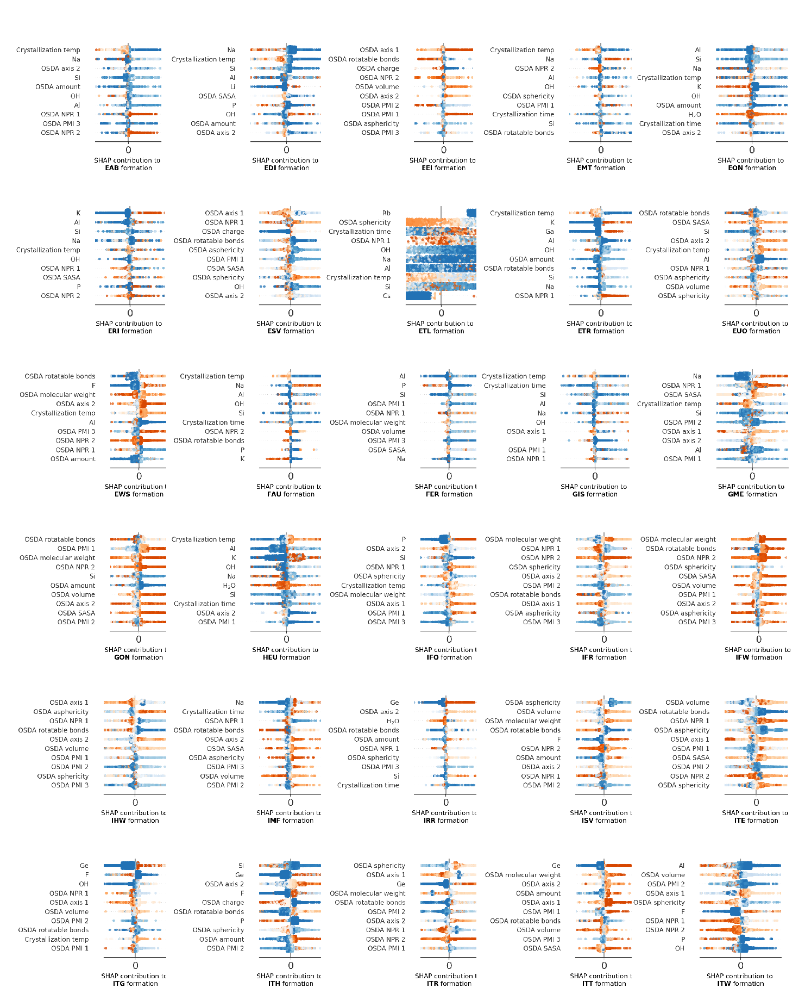

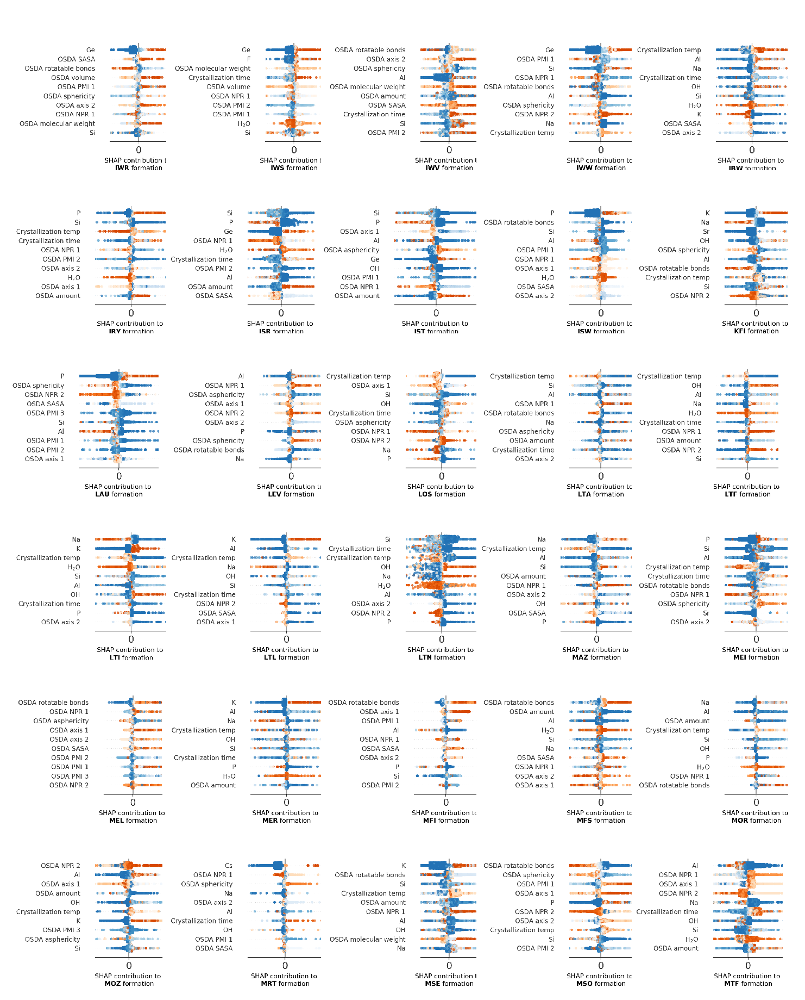

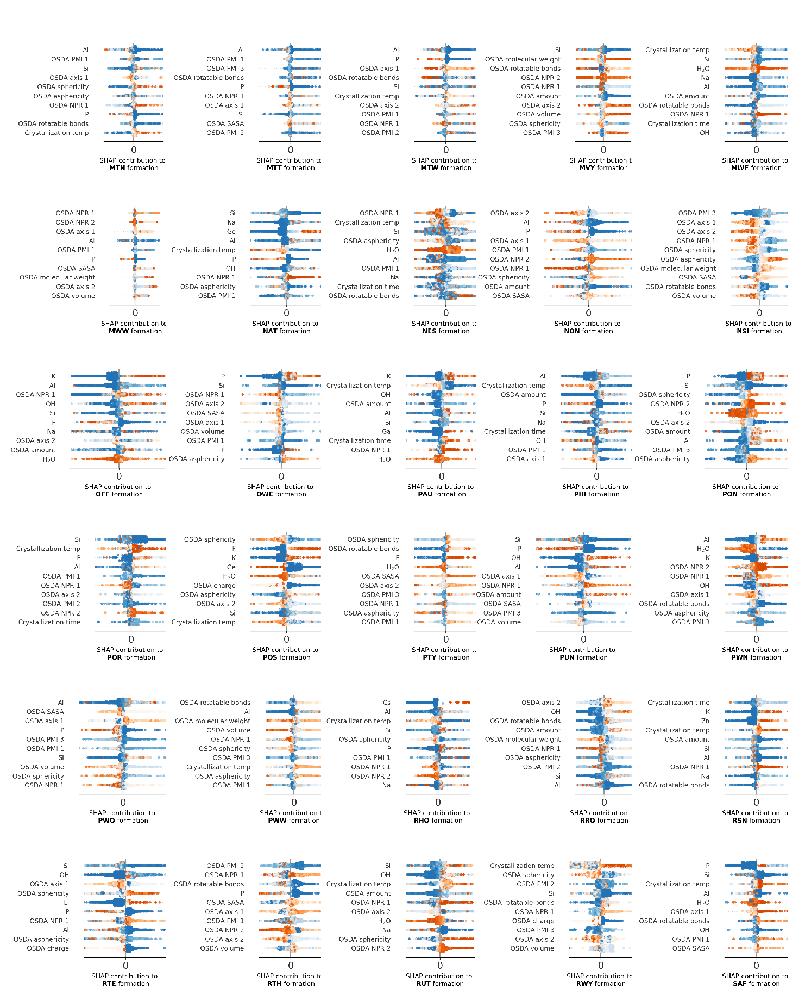

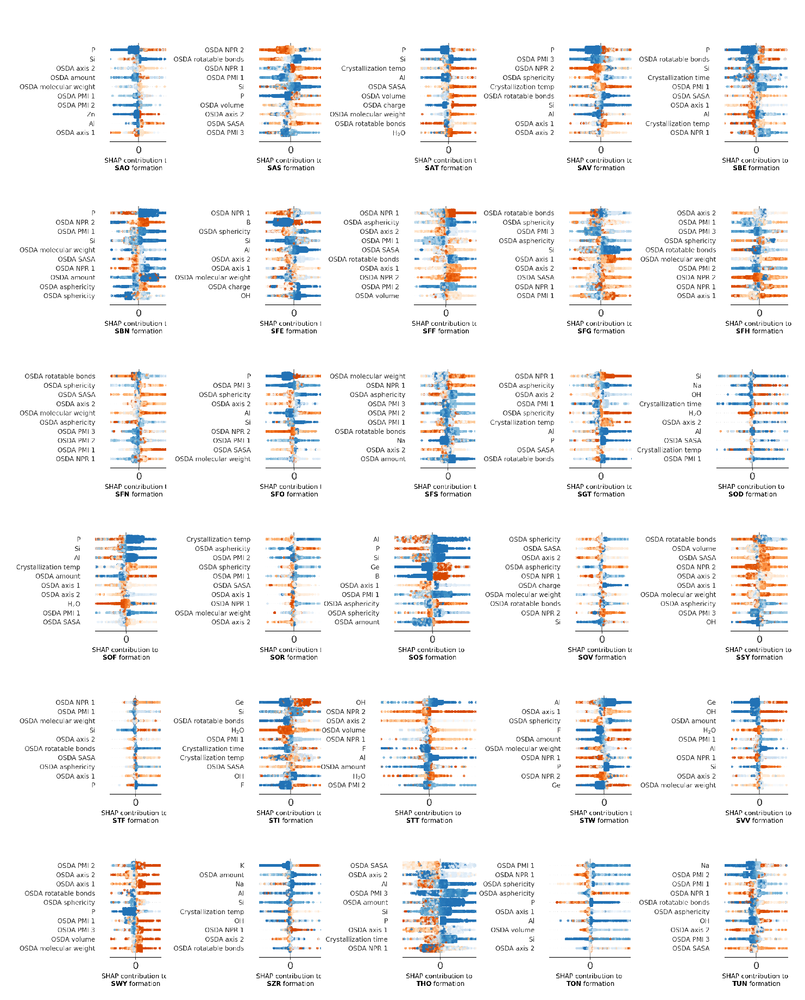

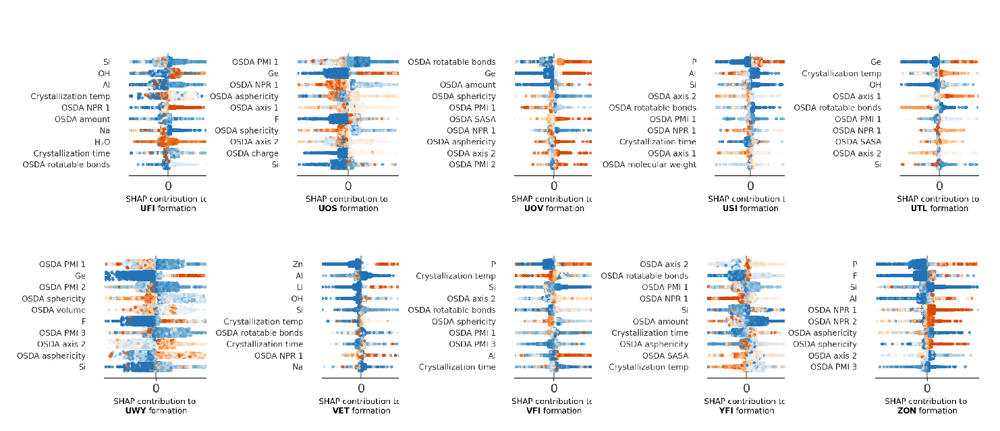

<Figure size 4000x3000 with 0 Axes>

In [28]:
# Composite framework-level SHAP for all frameworks
fws = sorted(s_pore+m_pore+l_pore+xl_pore)
n_fw_per_page = 30 # number of frameworks to be plotted each page

fig = plt.figure(figsize = (20,15), dpi = 200)
idx = 1 # framework index
page_idx = 1 # page index

for fw in fws:
    shap_path = f"framework/framework_shap/{fw}.png"
    
    if os.path.isfile(shap_path):
        shap_img = iio.imread(shap_path)
        shap_img = shap_img[int(0.05*shap_img.shape[1]):, int(0.15*shap_img.shape[0]):, :]

        fig.add_subplot(10,5,idx)
        
        
        plt.imshow(shap_img, extent = [0.00, 1, 0.02, 0.8], interpolation='none')
        
        ax = fig.gca()
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['bottom'].set_visible(False)
        ax.spines['left'].set_visible(False)
        ax.get_xaxis().set_ticks([])
        ax.get_yaxis().set_ticks([])
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        
        idx+=1

    if (idx == n_fw_per_page+1) or (fw == 'ZON'): # save fig and reset figure
        plt.subplots_adjust(left=0.0,
                    bottom=0.0, 
                    right=1.0, 
                    top=1.0, 
                    wspace=-0.9, 
                    hspace=0.)
        plt.savefig(f'figures/all_frameworks_shap{page_idx}.pdf', dpi = 500) # uncomment to save fig
        plt.show()
        
        idx = 1 # reset index
        page_idx += 1 # iterate page index
        
        fig = plt.figure(figsize = (20,15), dpi = 200) # initialize a new figure

# Competing phases

In [29]:
cps = [
        ['TON', 'MFI'],
        ['FAU', 'GIS'],
        ['AFI', 'CHA'], 
        ['*BEA','BEC'],
      ]

TON MFI
Common top SHAP features: {'OSDA axis 2', 'OSDA PMI 2', 'Crystallization time', 'H$_2$O', 'OSDA PMI 3', 'B', 'OSDA amount', 'OSDA molecular weight', 'Ge', 'Na', 'OH', 'OSDA NPR 1', 'F', 'OSDA rotatable bonds', 'OSDA sphericity', 'OSDA NPR 2', 'OSDA charge', 'OSDA PMI 1', 'OSDA axis 1', 'Si', 'OSDA asphericity', 'Al', 'OSDA SASA', 'Ti', 'OSDA volume', 'K', 'Crystallization temp', 'P'}


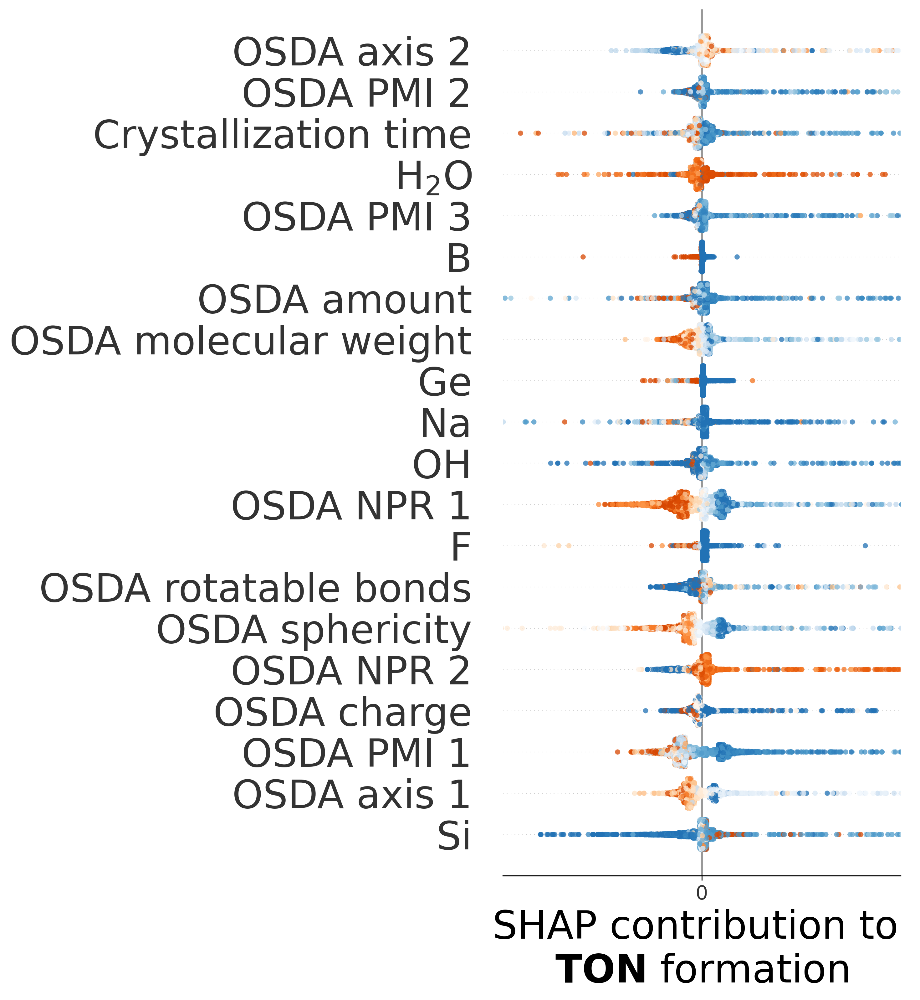

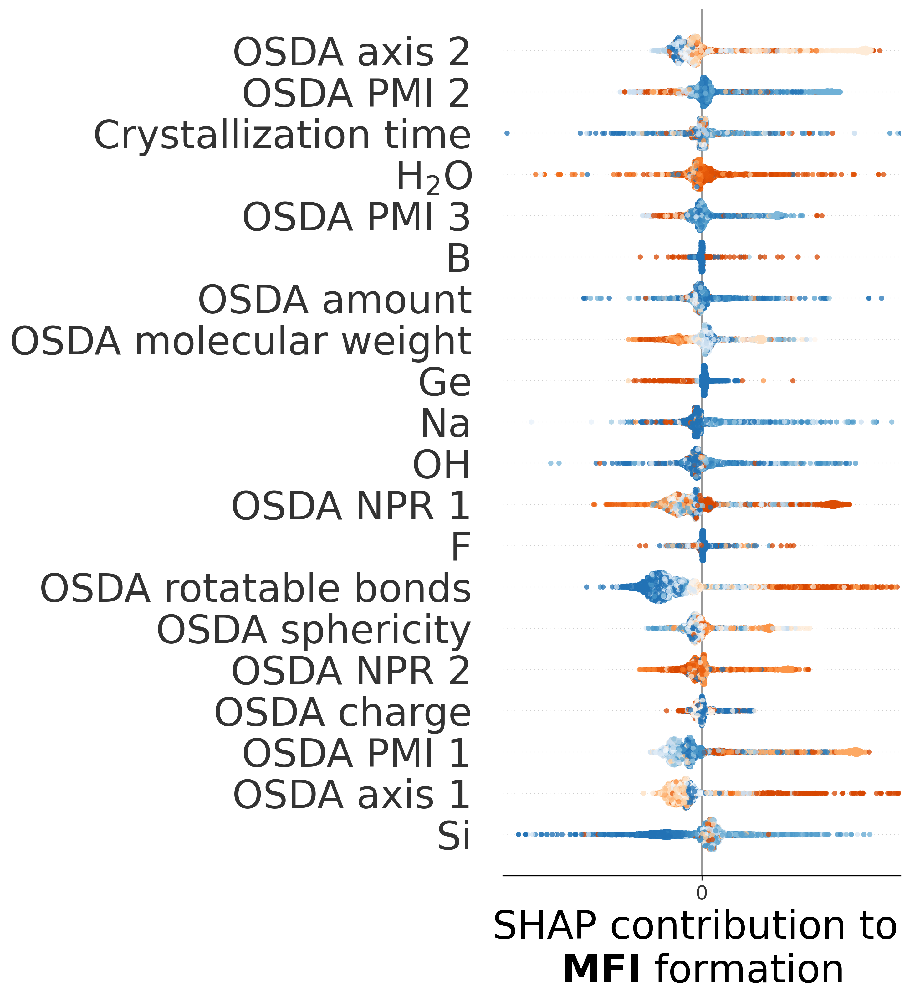

FAU GIS
Common top SHAP features: {'Li', 'OSDA axis 2', 'OSDA PMI 2', 'Crystallization time', 'H$_2$O', 'Cs', 'OSDA PMI 3', 'OSDA amount', 'OSDA molecular weight', 'Ge', 'Na', 'OH', 'OSDA NPR 1', 'F', 'OSDA sphericity', 'OSDA rotatable bonds', 'OSDA NPR 2', 'OSDA charge', 'OSDA PMI 1', 'Zn', 'OSDA axis 1', 'Si', 'OSDA asphericity', 'Al', 'OSDA SASA', 'OSDA volume', 'K', 'Crystallization temp', 'P'}


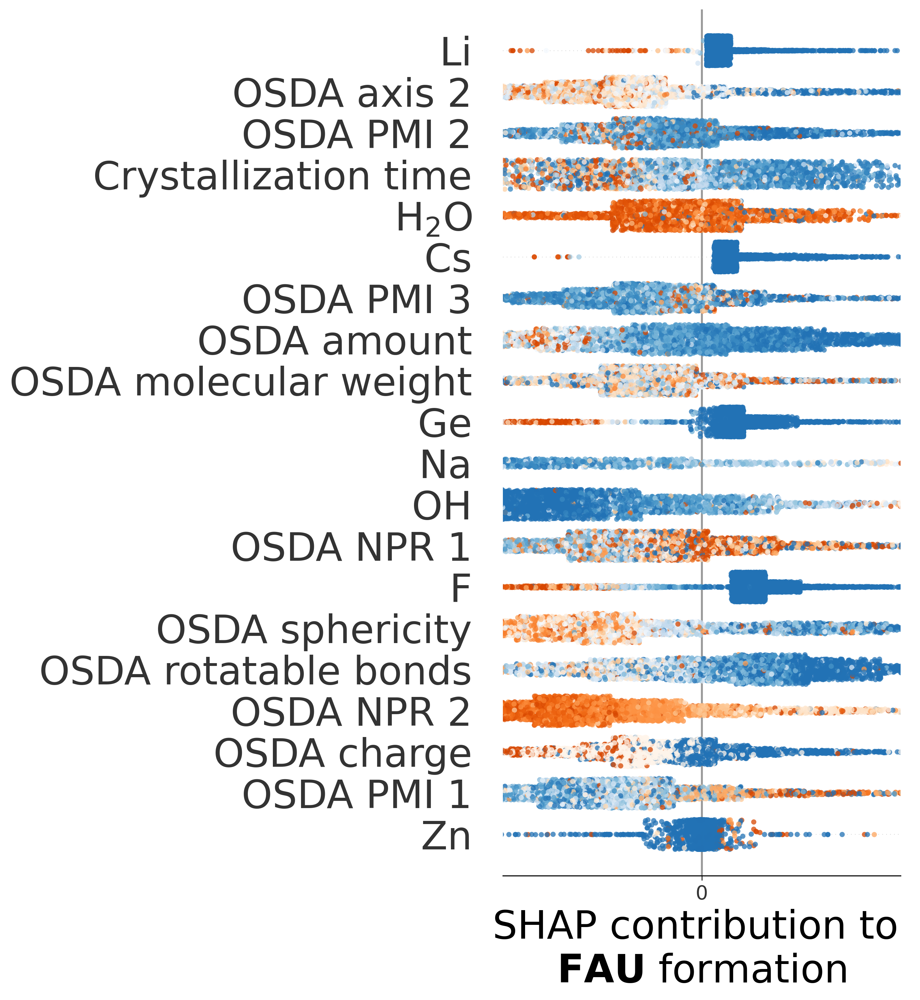

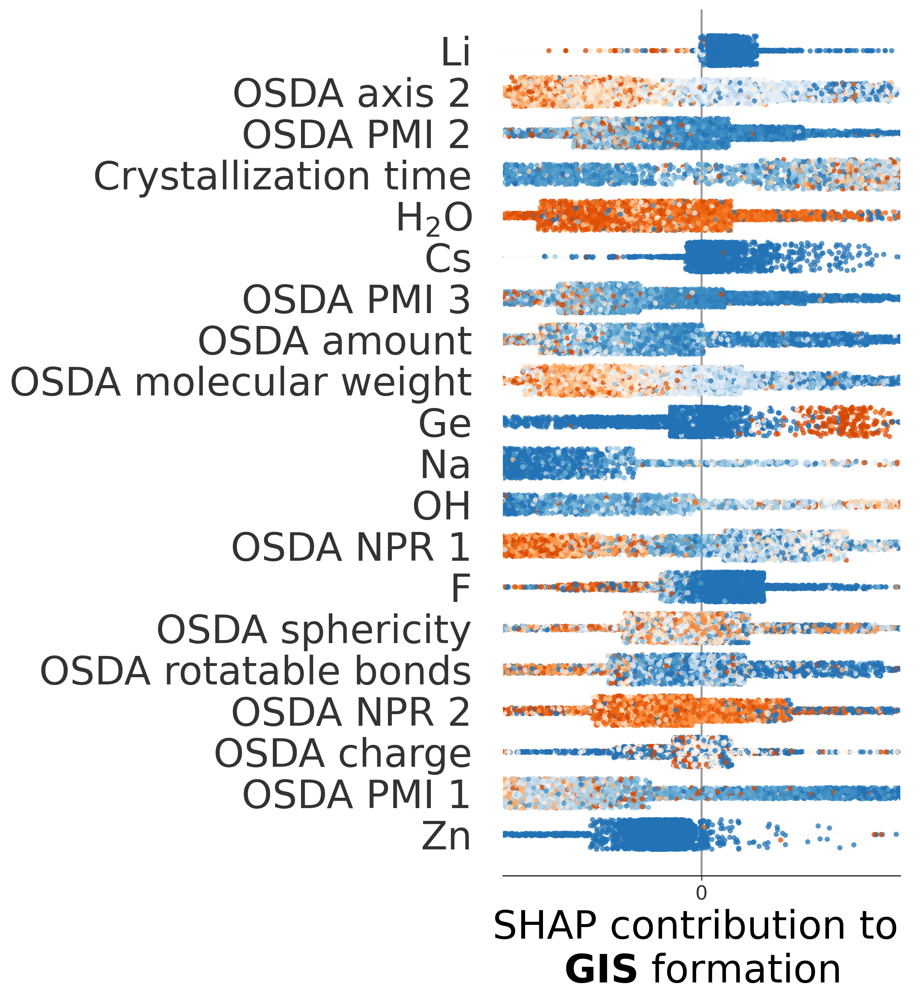

AFI CHA
Common top SHAP features: {'OSDA axis 2', 'OSDA PMI 2', 'Crystallization time', 'H$_2$O', 'OSDA PMI 3', 'OSDA amount', 'OSDA molecular weight', 'Ge', 'Na', 'OH', 'OSDA NPR 1', 'F', 'OSDA sphericity', 'OSDA rotatable bonds', 'OSDA NPR 2', 'OSDA charge', 'OSDA PMI 1', 'Zn', 'OSDA axis 1', 'Si', 'OSDA asphericity', 'Al', 'OSDA SASA', 'OSDA volume', 'K', 'Crystallization temp', 'P'}


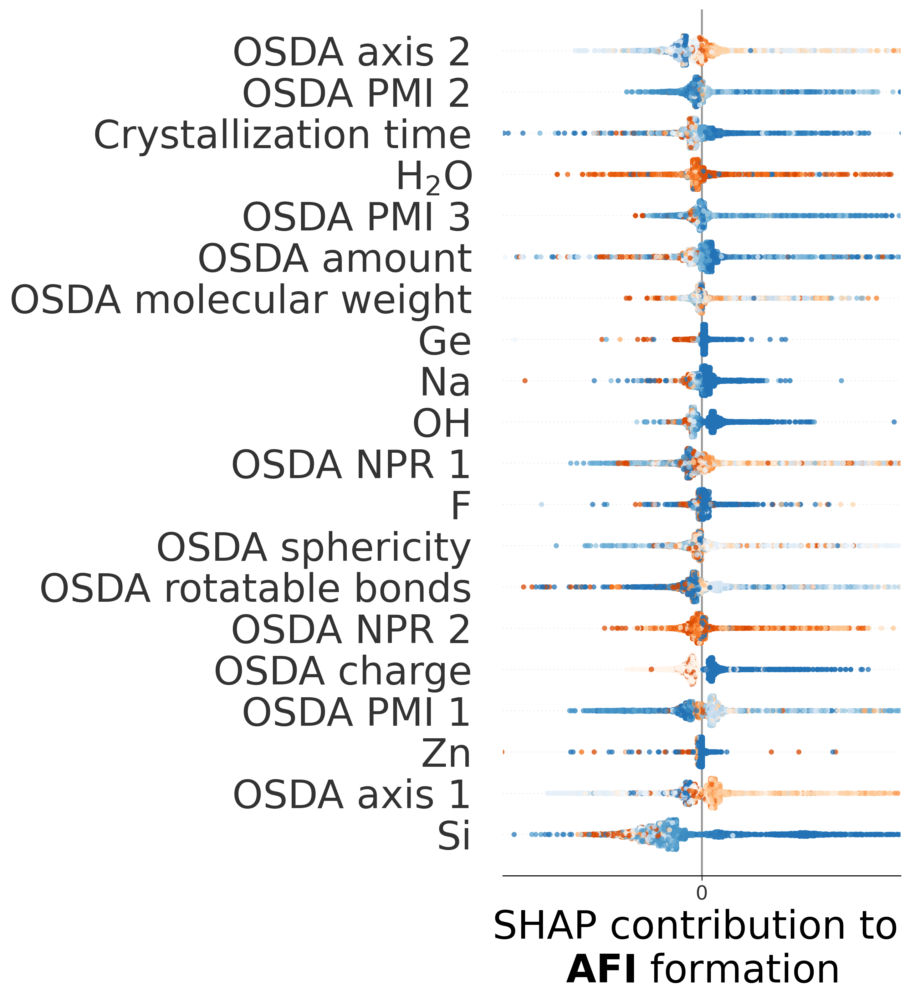

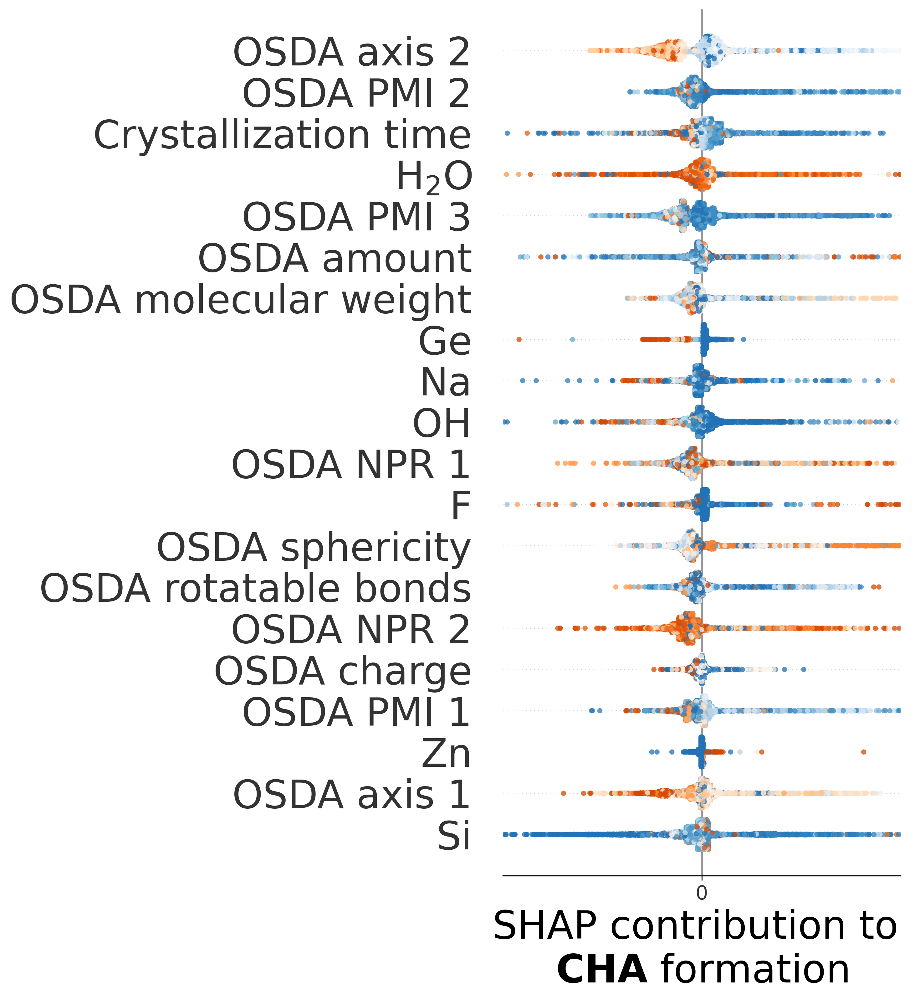

*BEA BEC
Common top SHAP features: {'Li', 'OSDA axis 2', 'OSDA PMI 2', 'Crystallization time', 'H$_2$O', 'OSDA PMI 3', 'B', 'OSDA amount', 'Ge', 'OSDA molecular weight', 'Na', 'OH', 'OSDA NPR 1', 'F', 'OSDA rotatable bonds', 'OSDA sphericity', 'OSDA NPR 2', 'OSDA charge', 'OSDA PMI 1', 'Zn', 'OSDA axis 1', 'Si', 'OSDA asphericity', 'Al', 'OSDA SASA', 'OSDA volume', 'K', 'Crystallization temp', 'P'}


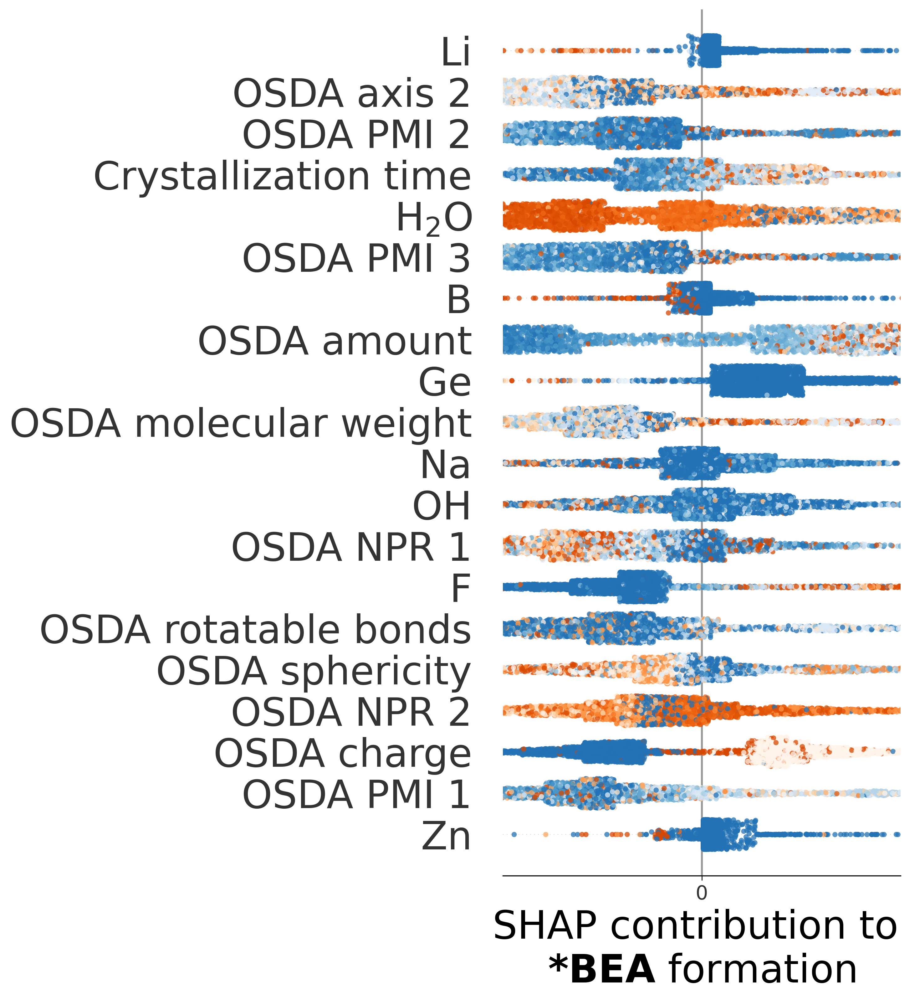

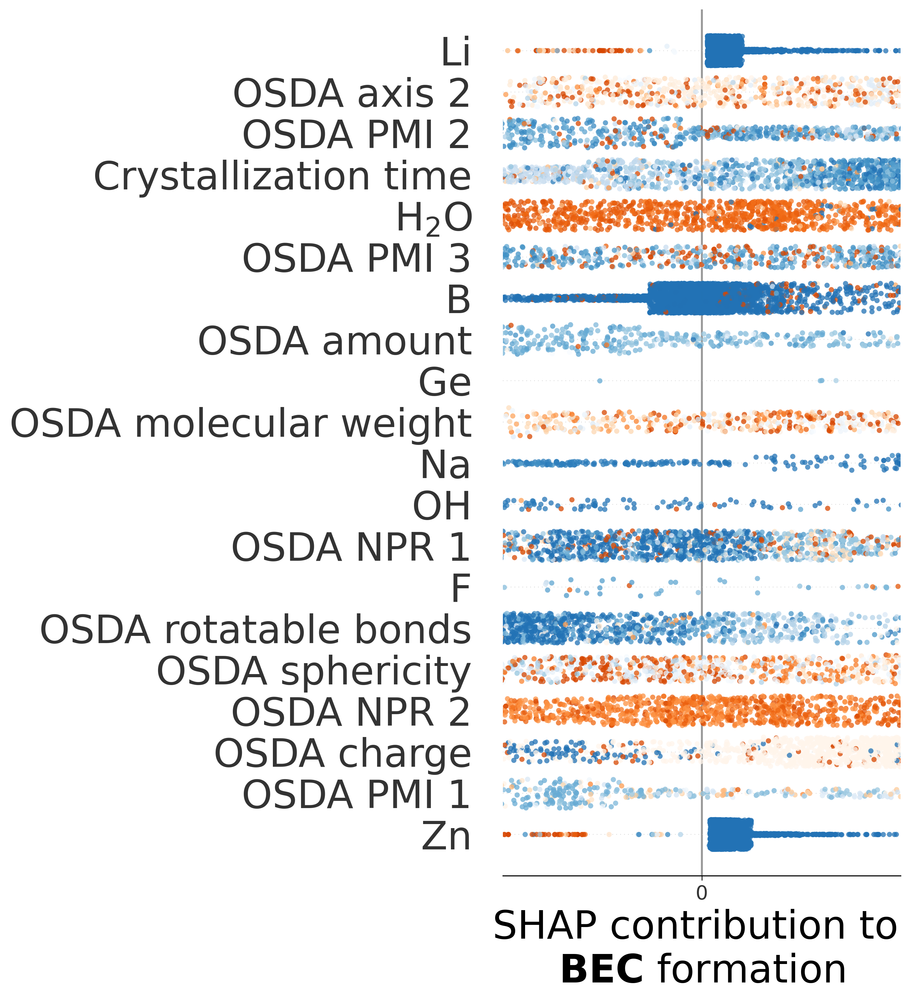

In [30]:
for z1, z2 in cps:
    print(z1, z2)
    
    # Get common top SHAP features for each framework
    z1z2_top_shap_feats = []
    for z in [z1, z2]:
        top_shap_feats = plot_zeo_shap(z, cols = X_cols.values(), cmap = cmap, alpha = 0.75, max_display = 30, plot_size = (7,7), xlabel_size = 30, color_bar = False,
                     return_top_shap_feats = True) # return only top SHAP features
        z1z2_top_shap_feats.append(set(top_shap_feats))
    z1_tsf, z2_tsf = z1z2_top_shap_feats 
    common_top_shap_feats = z1_tsf.intersection(z2_tsf) # Common top SHAP features between two frameworks

    print('Common top SHAP features:', common_top_shap_feats)
    
    # Plot framework SHAP with only with common SHAP features
    for z in [z1, z2]:
        plot_zeo_shap(z, cols = common_top_shap_feats, cmap = cmap, alpha = 0.75, max_display = 20, plot_size = (7,10), xlabel_size = 30, color_bar = False,
                         sort = False # turn off sort to get feature order as per "cols" argument
                         )    
    
    print('='*50)

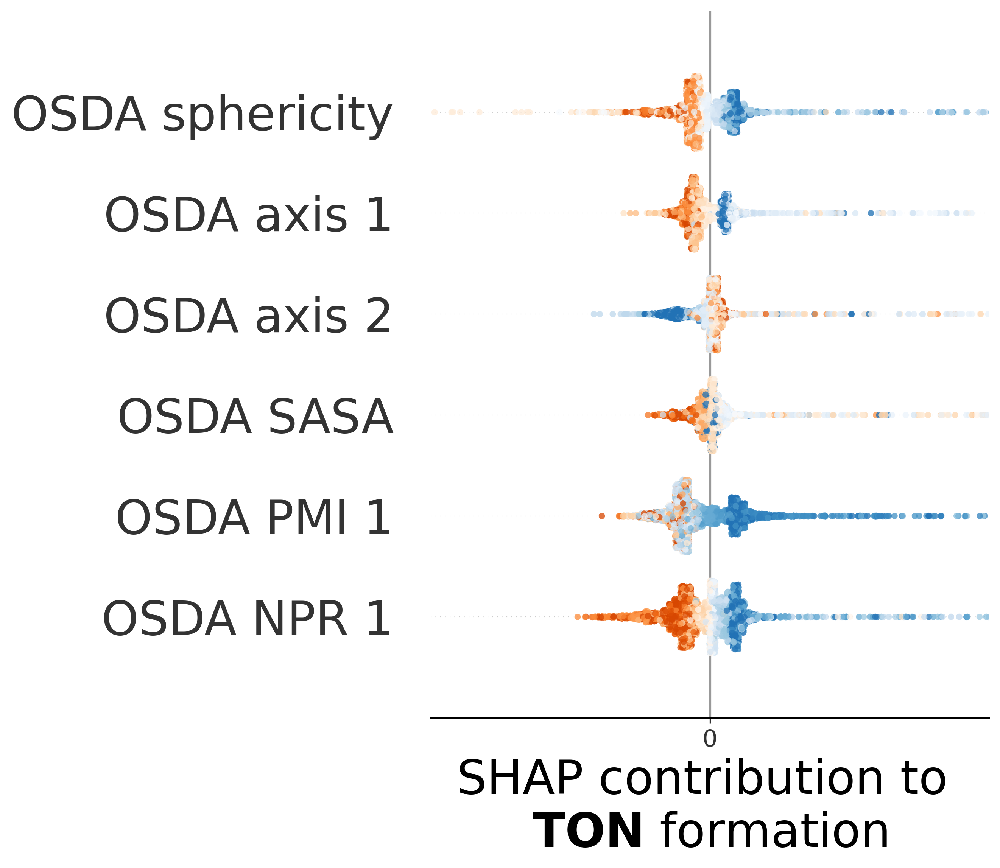

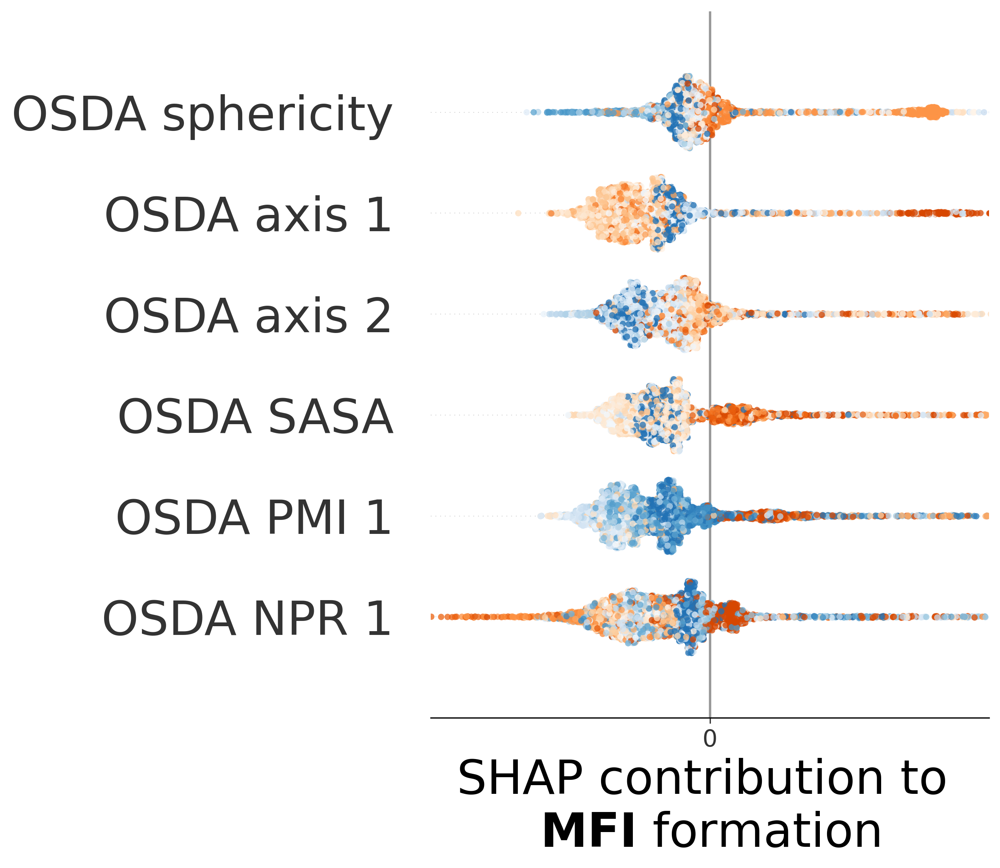

In [31]:
# Competing phases: TON & MFI
cols = ['OSDA sphericity', 'OSDA axis 1', 'OSDA axis 2', 'OSDA SASA', 'OSDA PMI 1', 'OSDA NPR 1', ]

for z in ['TON', 'MFI']:
    plot_zeo_shap(z, cols = cols, cmap = cmap, alpha = 0.75, max_display = 10, plot_size = (7,7), xlabel_size = 30, color_bar = False,
                  sort = False # turn off sort to get feature order as per "cols" argument
                         )

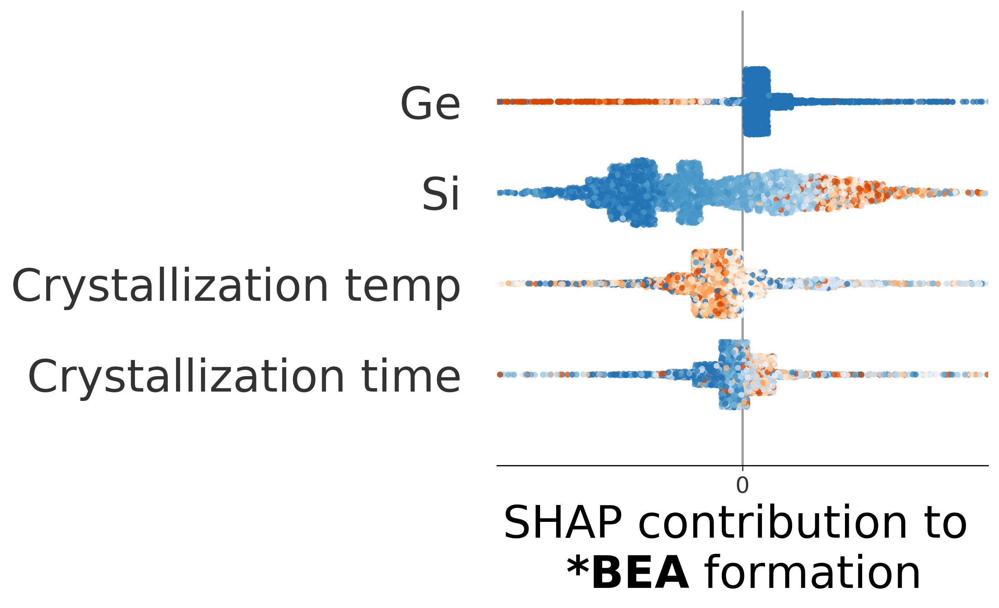

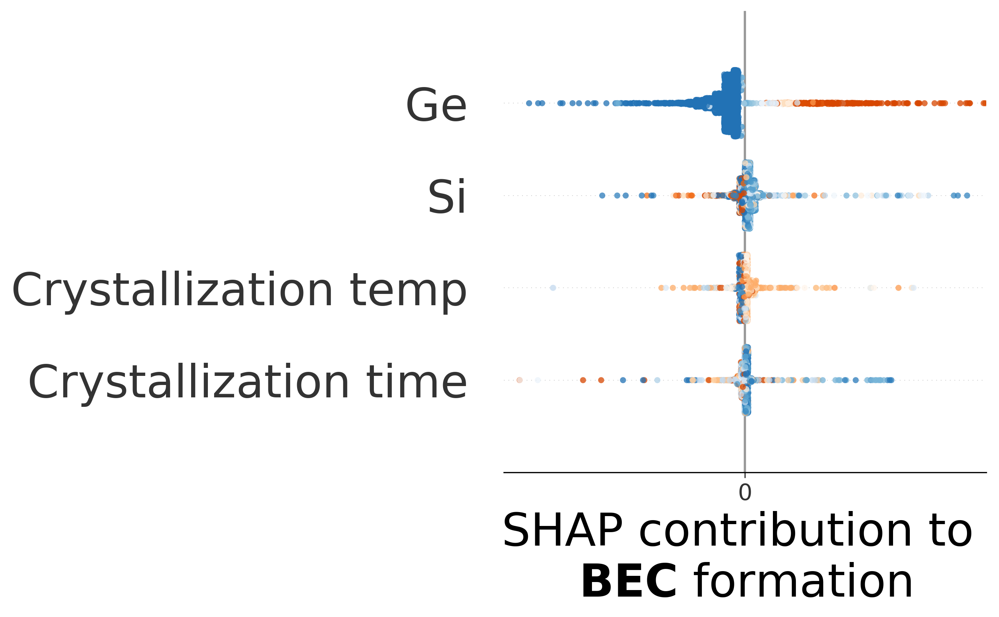

In [32]:
# Competing phases: *BEA & BEC

cols = ['Ge', 'Si', 'Crystallization temp', 'Crystallization time']

for z in ['*BEA', 'BEC']:
    plot_zeo_shap(z, cols = cols, cmap = cmap, alpha = 0.75, max_display = 10, plot_size = (7,5), xlabel_size = 30, color_bar = False,
                  sort = False # turn off sort to get feature order as per "cols" argument
                         )

# Intergrowths

In [33]:
igs = list(y[y.str.contains('/')].unique())
for ig in igs:
    print(ig, (y == ig).sum())

MFI/MEL 28
*BEA/BEC 5
ISV/BEC 167
ERI/OFF 74
FAU/EMT 7
MEL/MFI 19
MEL/ZSM-55 1
TON/MTT 43
AFX/CHA 6
STF/SFF 2
CHA/AEI 3
MOR/MFI 1
AEI/CHA 4
RUT/RTH 2


['MFI', 'MEL', 'MFI/MEL']


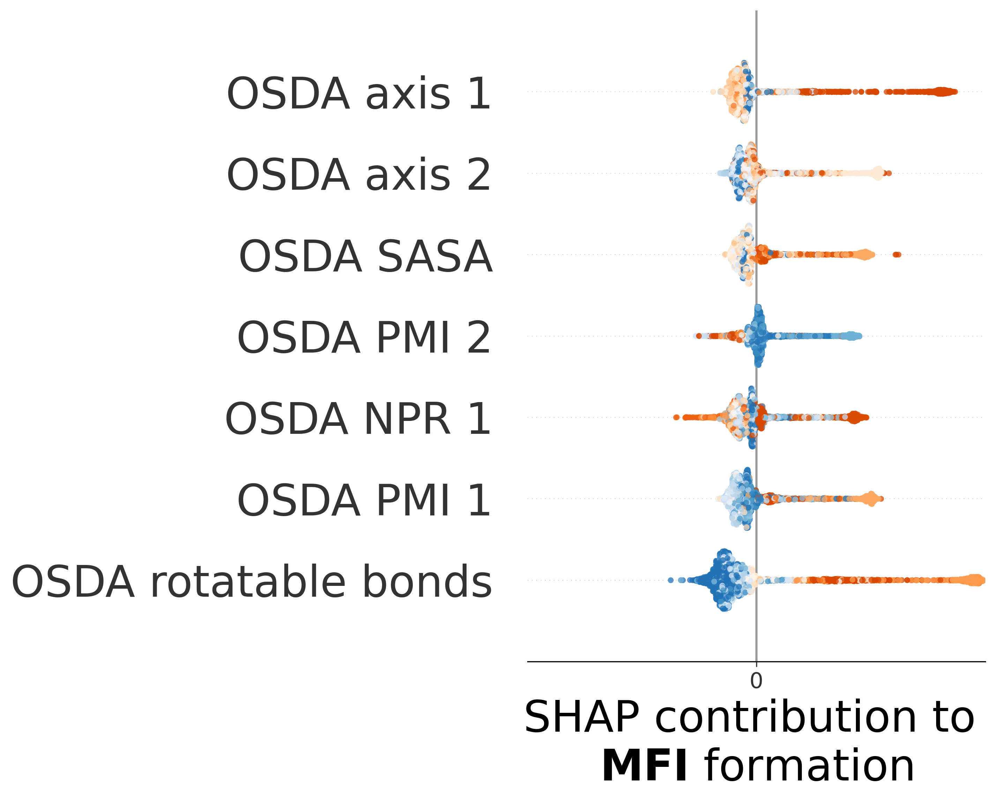

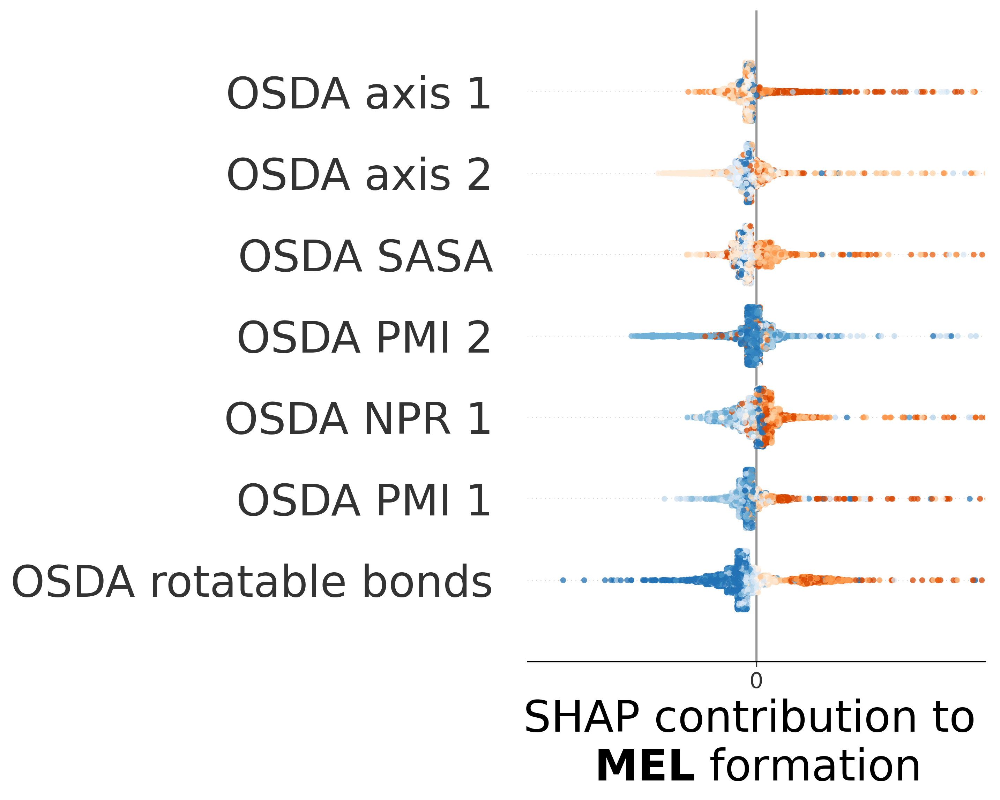

['*BEA', 'BEC', '*BEA/BEC']


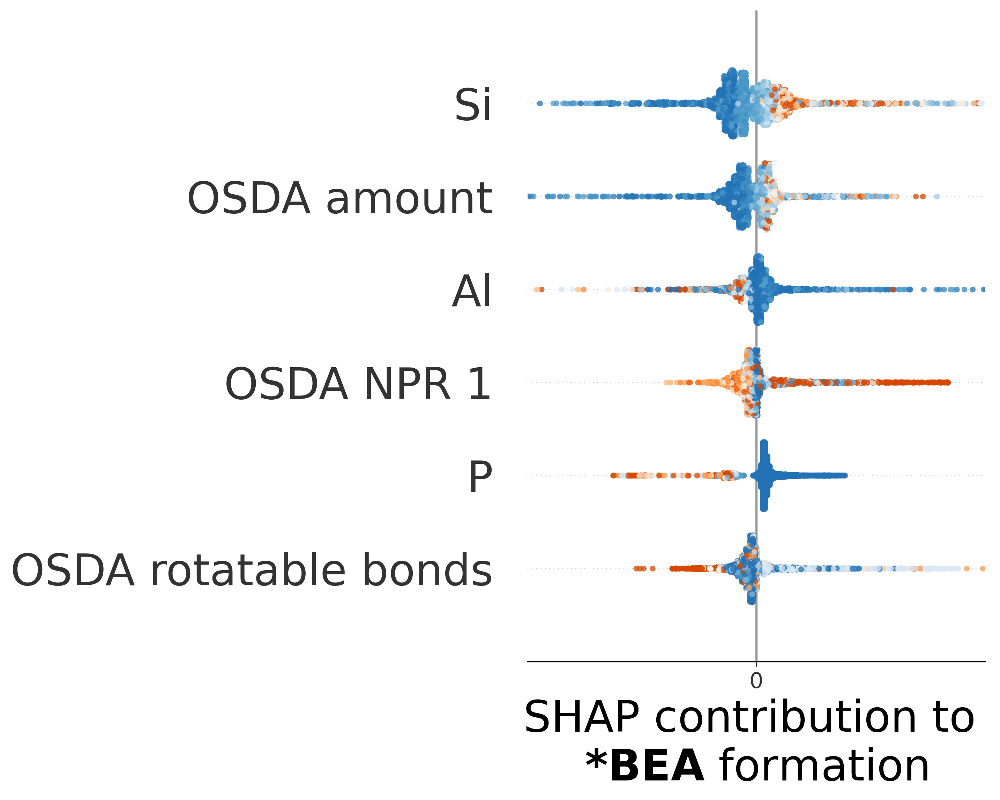

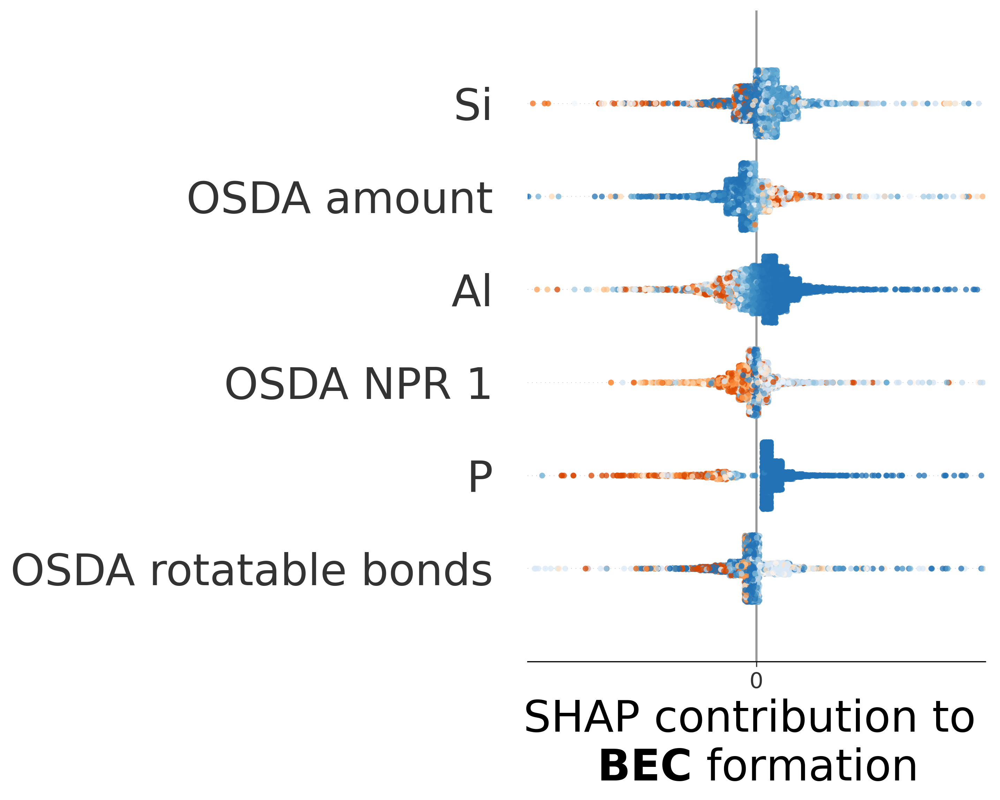

['ISV', 'BEC', 'ISV/BEC']


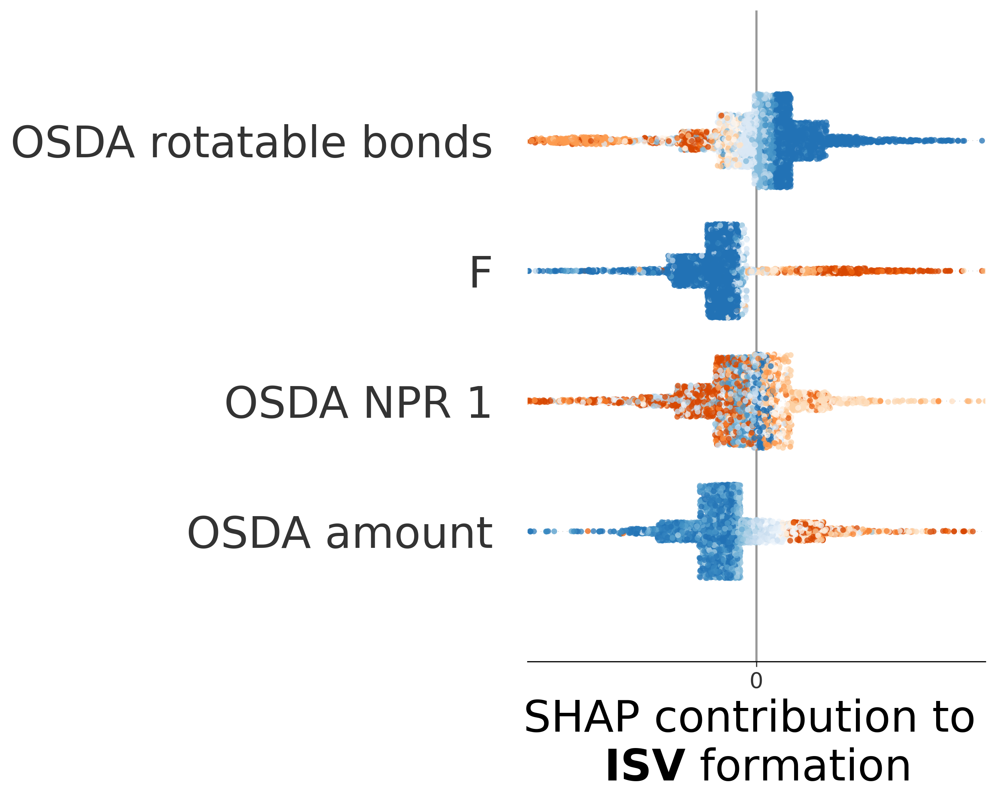

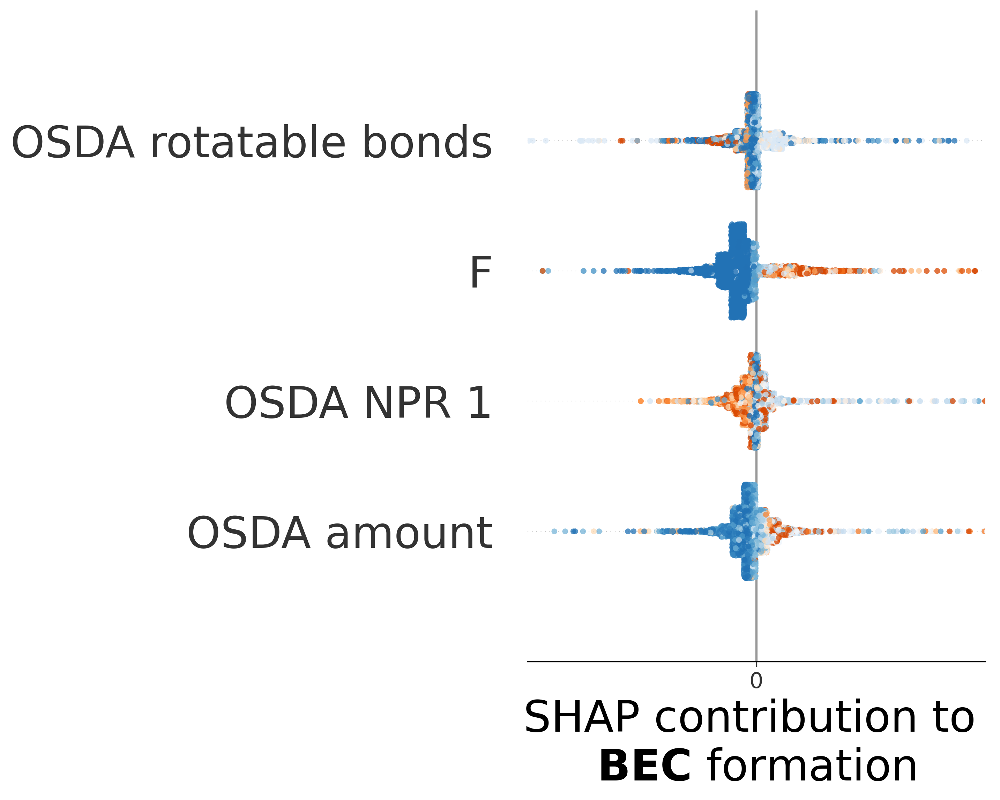

['ERI', 'OFF', 'ERI/OFF']


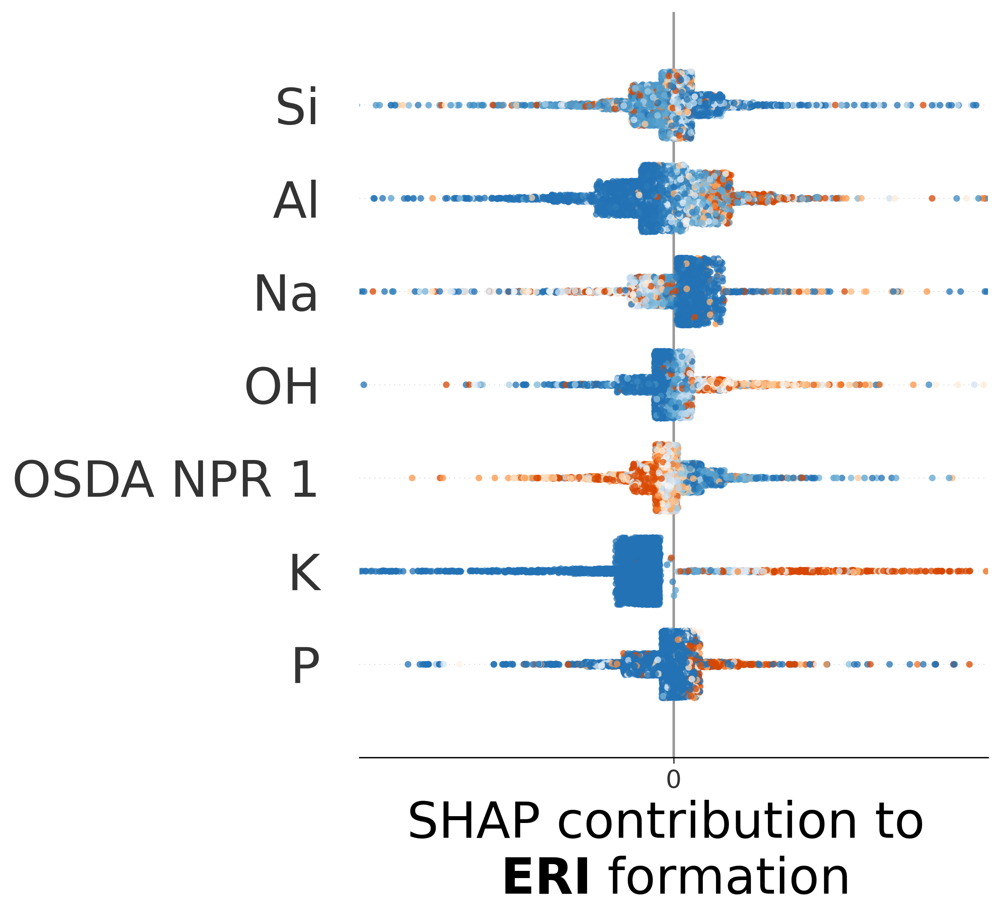

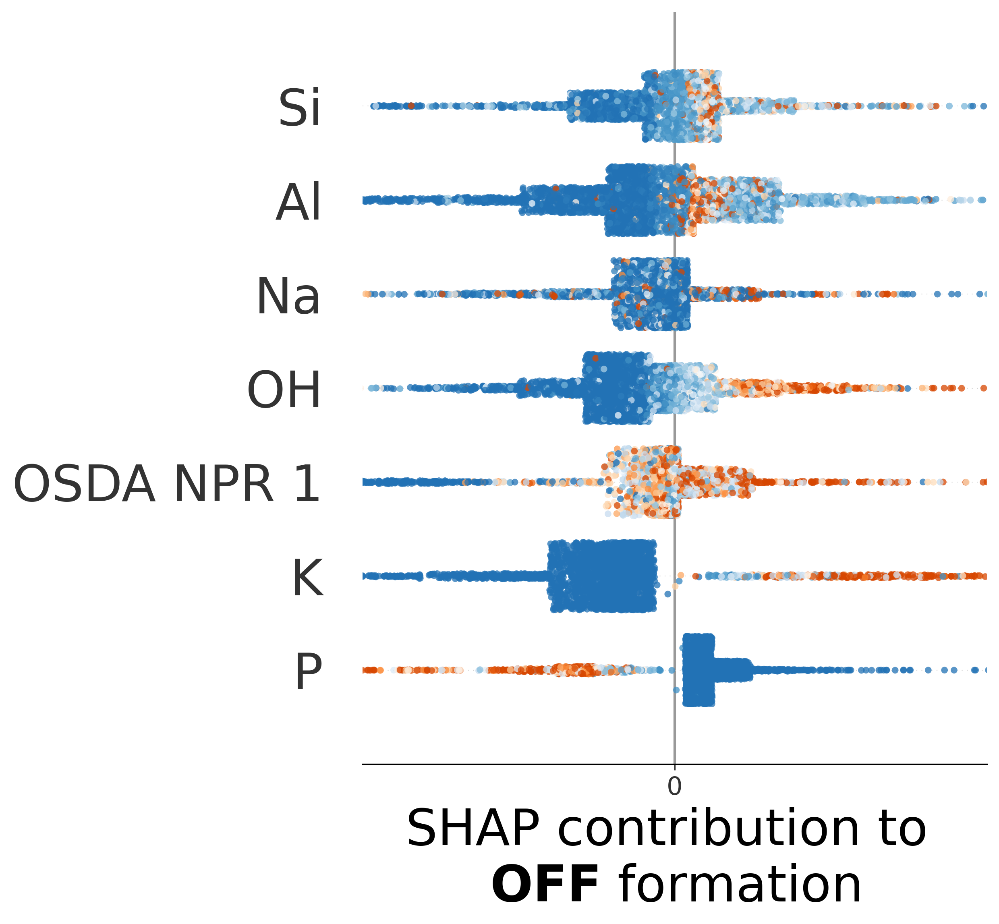

['FAU', 'EMT', 'FAU/EMT']


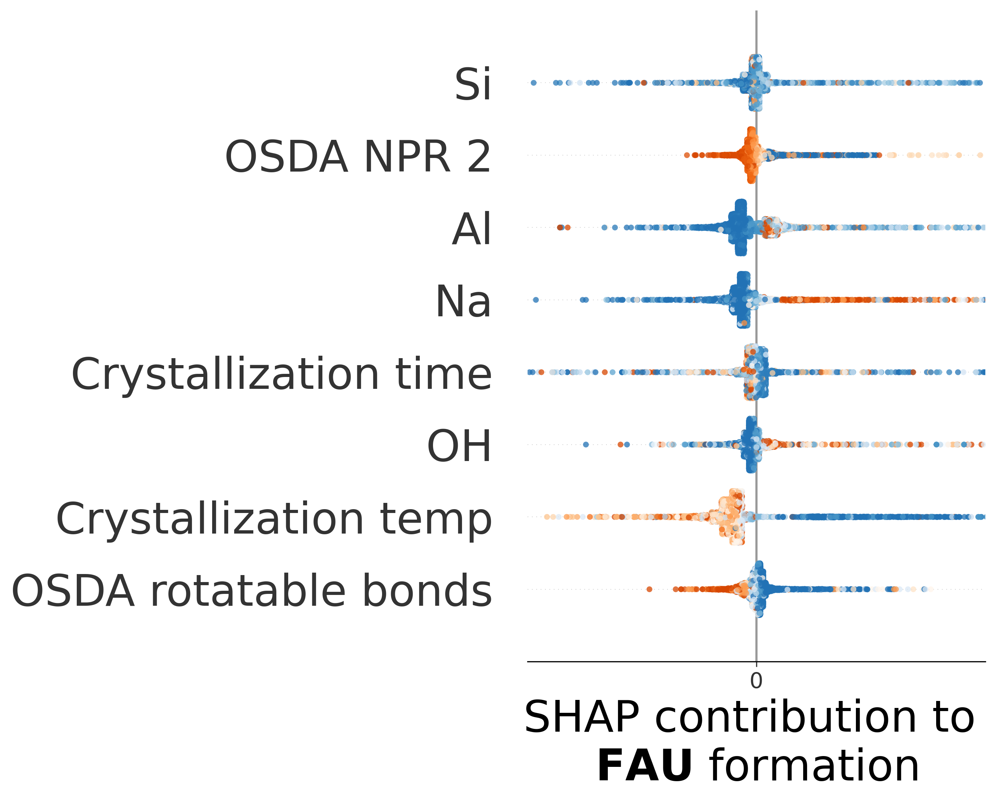

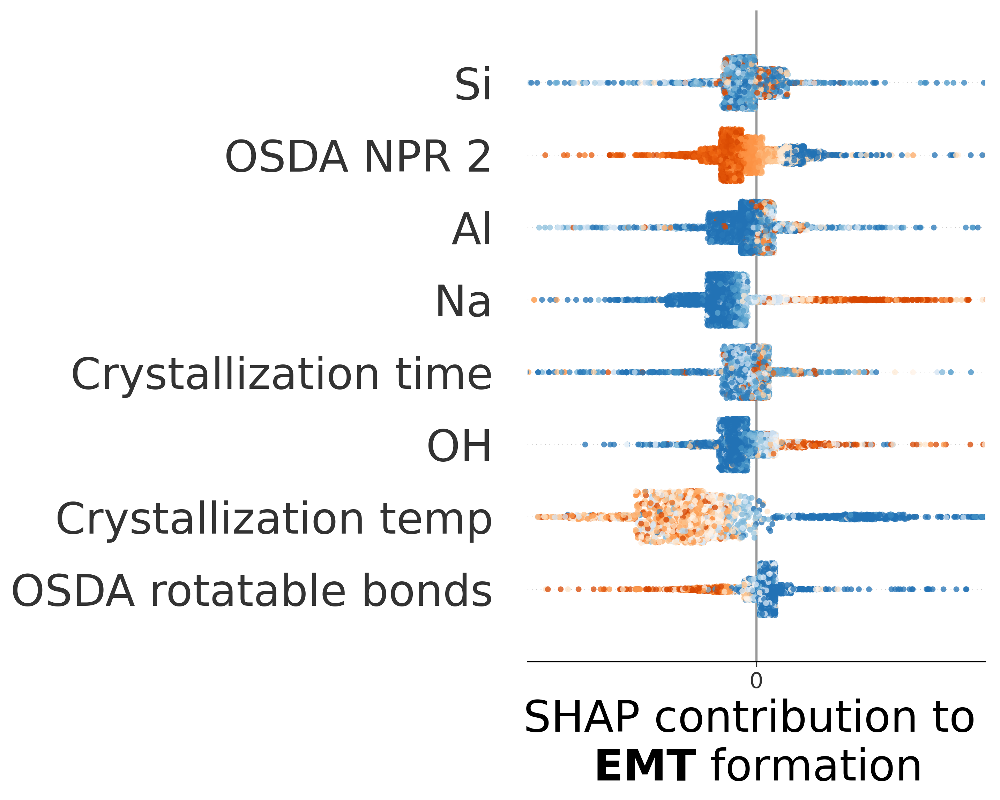

['MEL', 'MFI', 'MEL/MFI']


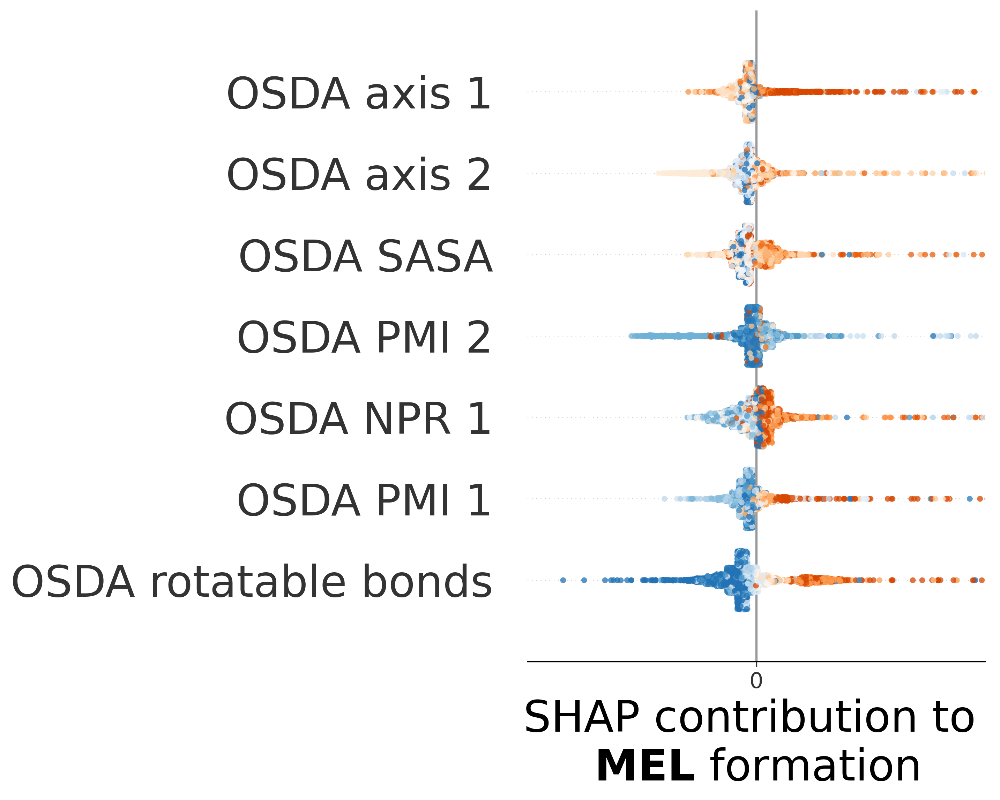

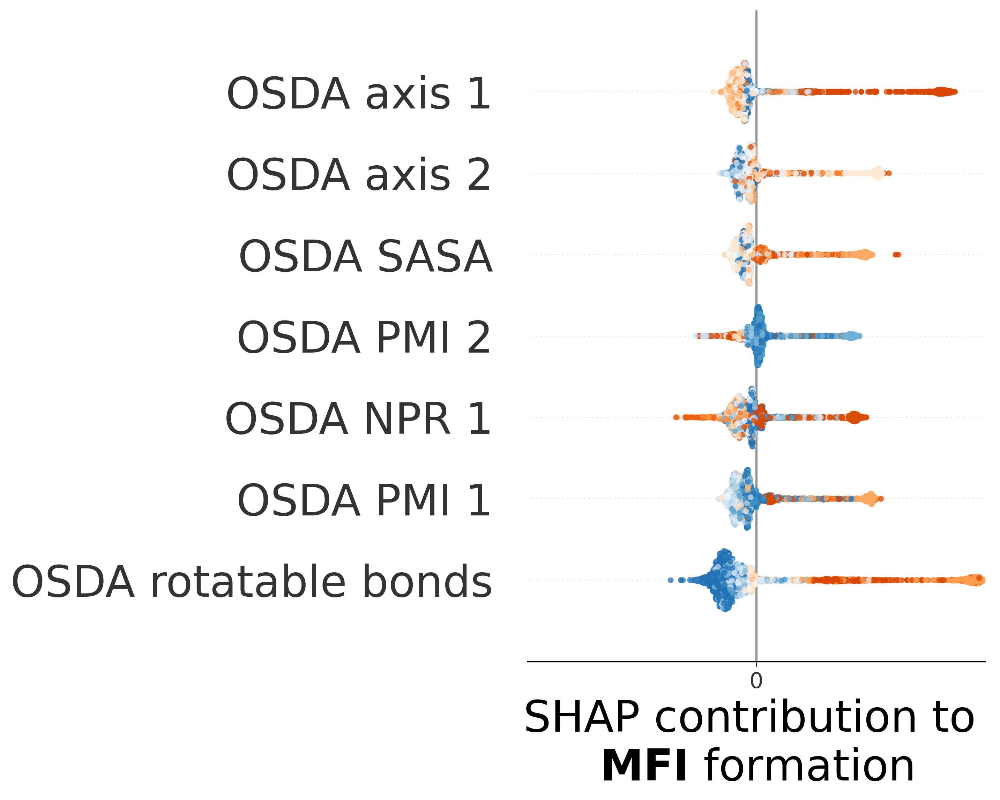

['MEL', 'ZSM-55', 'MEL/ZSM-55']
index 0 is out of bounds for axis 0 with size 0
['TON', 'MTT', 'TON/MTT']


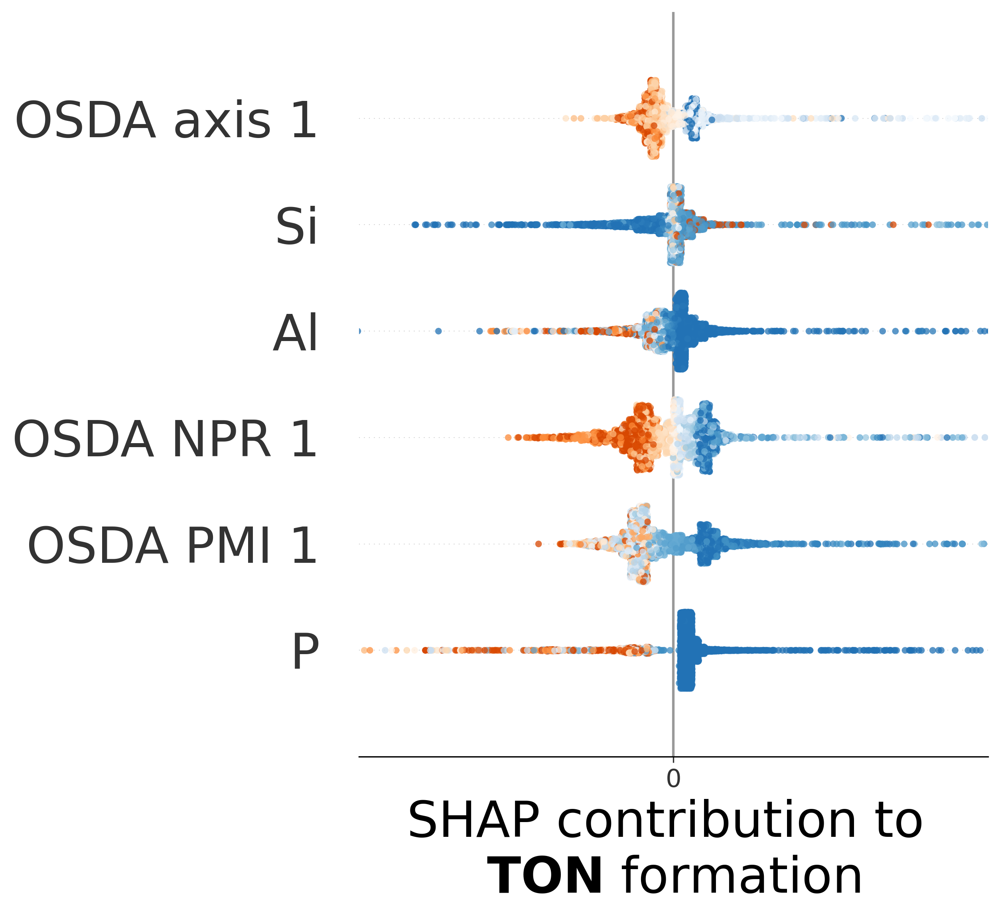

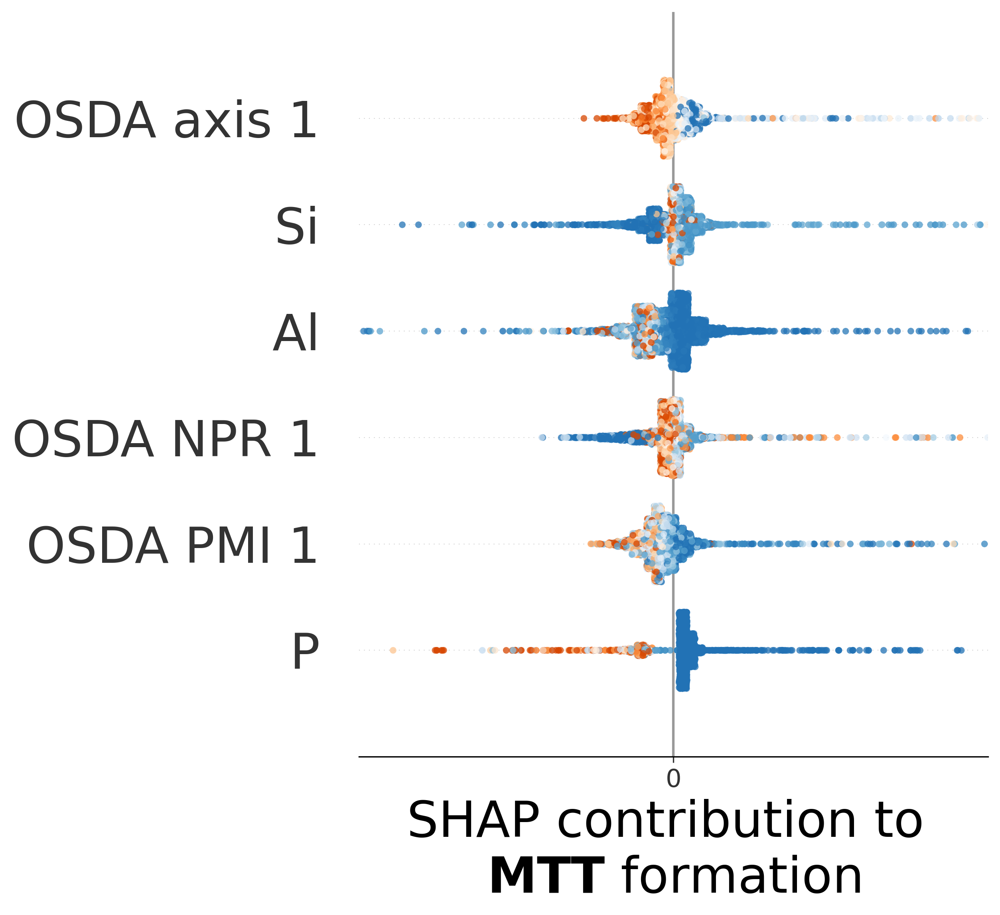

['AFX', 'CHA', 'AFX/CHA']


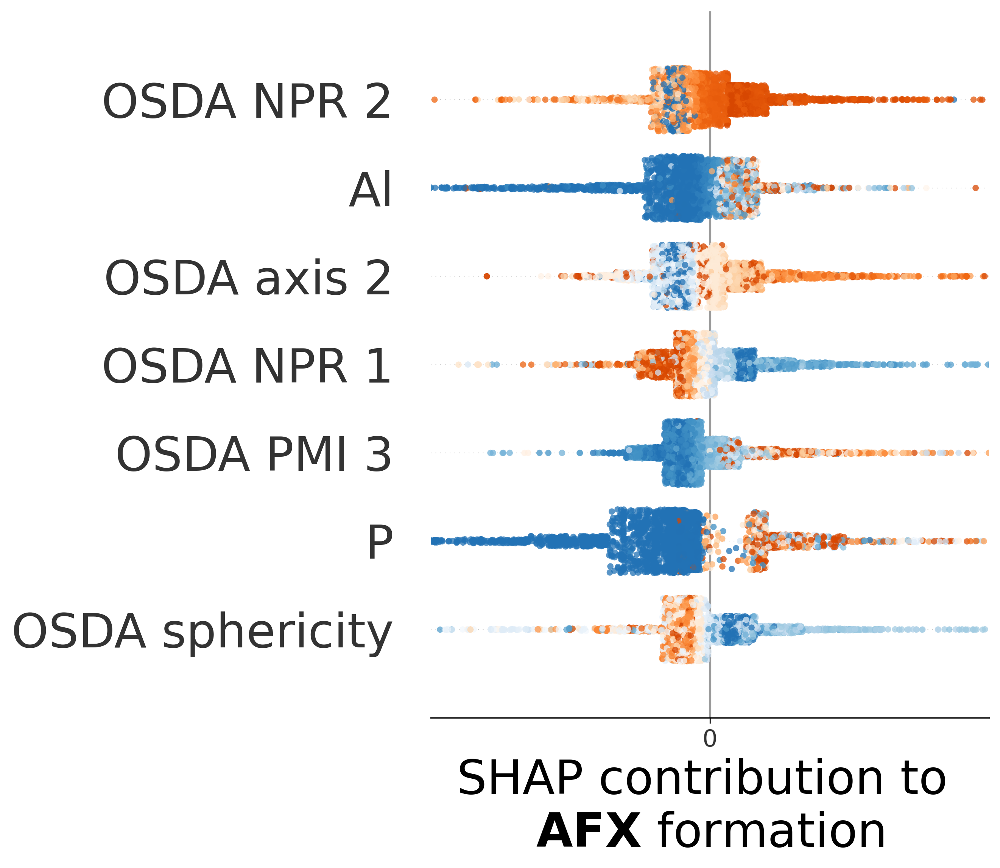

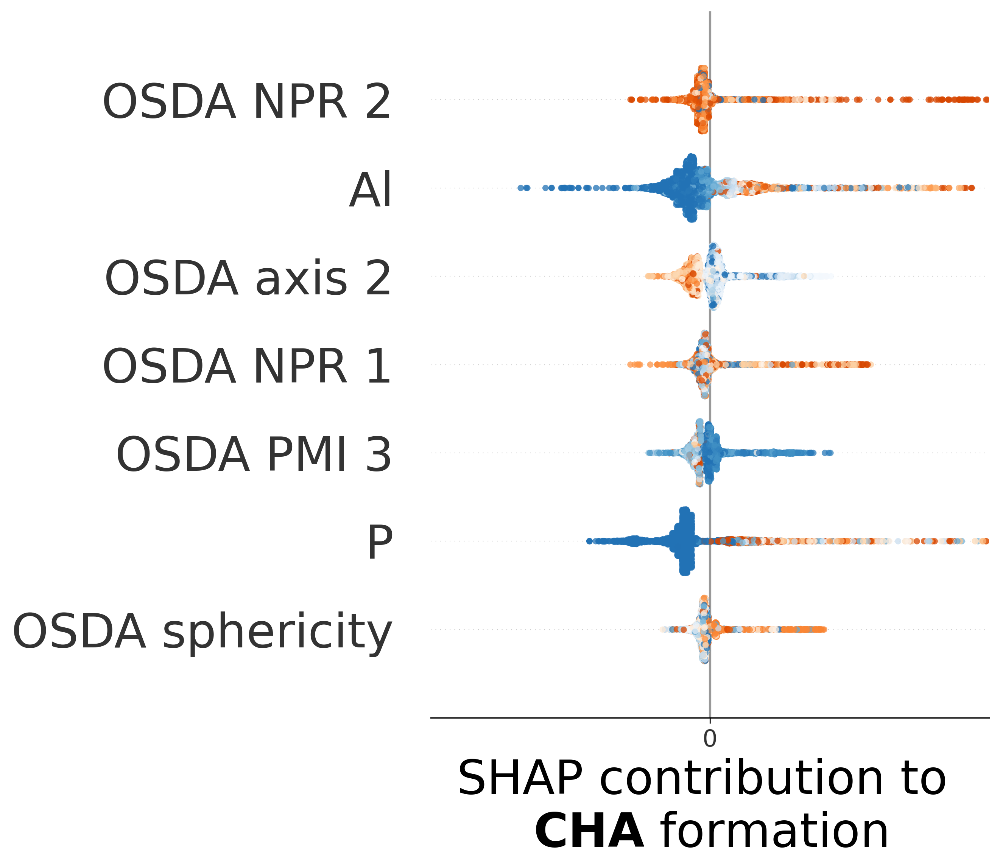

['STF', 'SFF', 'STF/SFF']


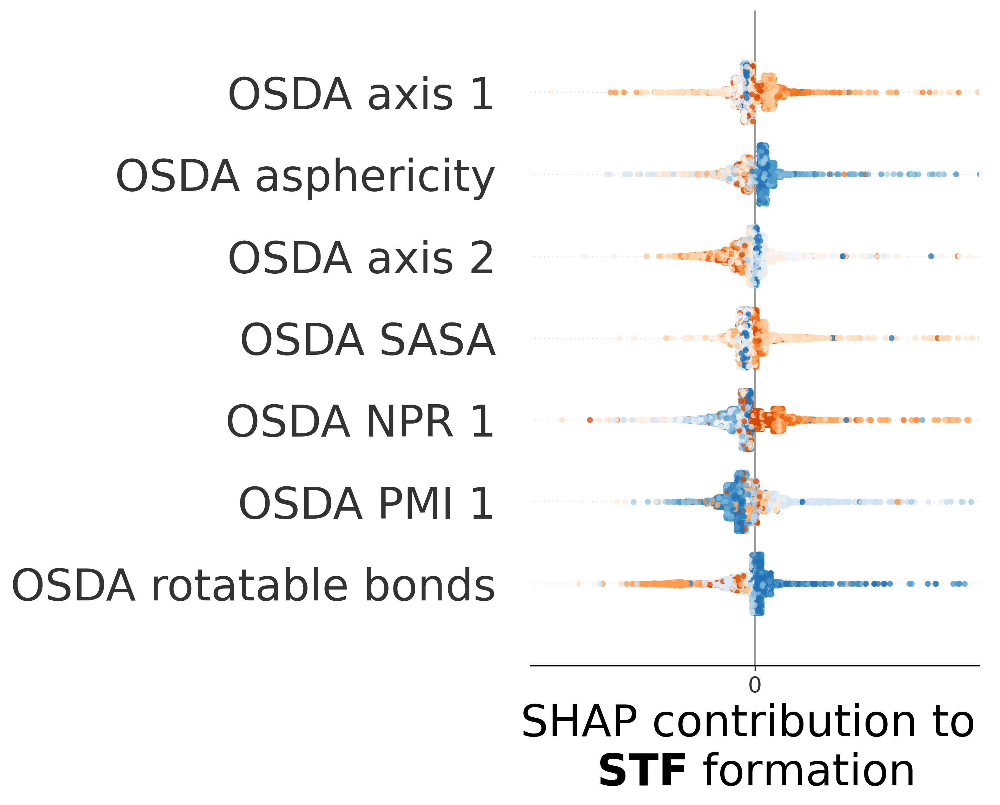

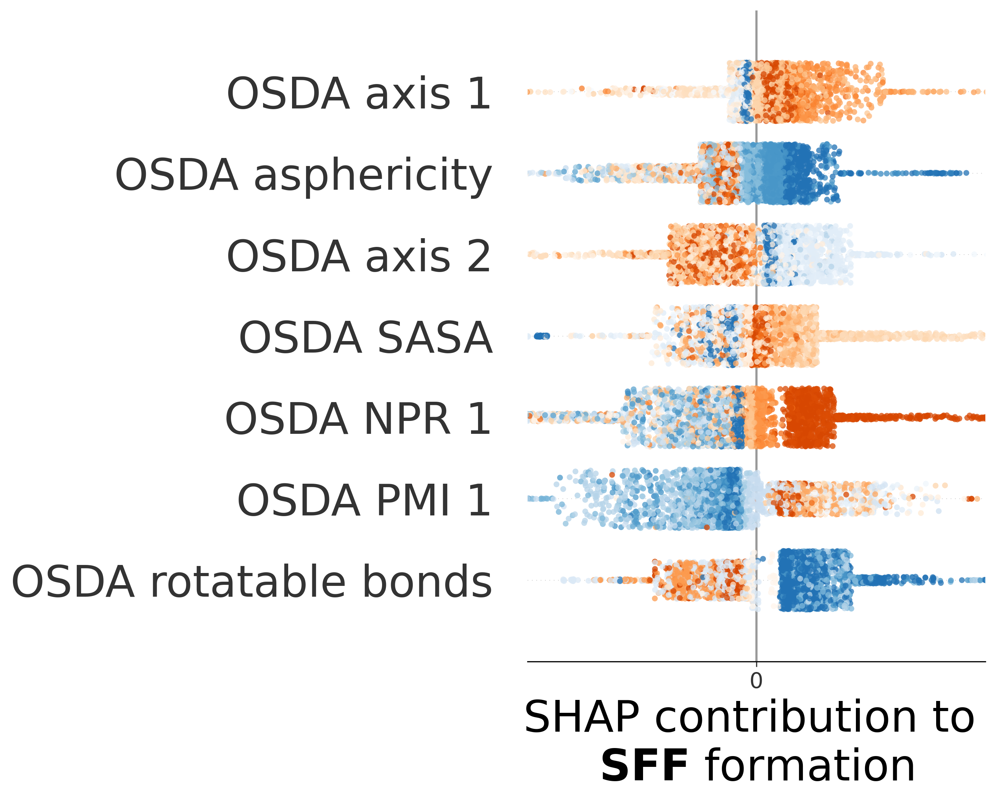

['CHA', 'AEI', 'CHA/AEI']


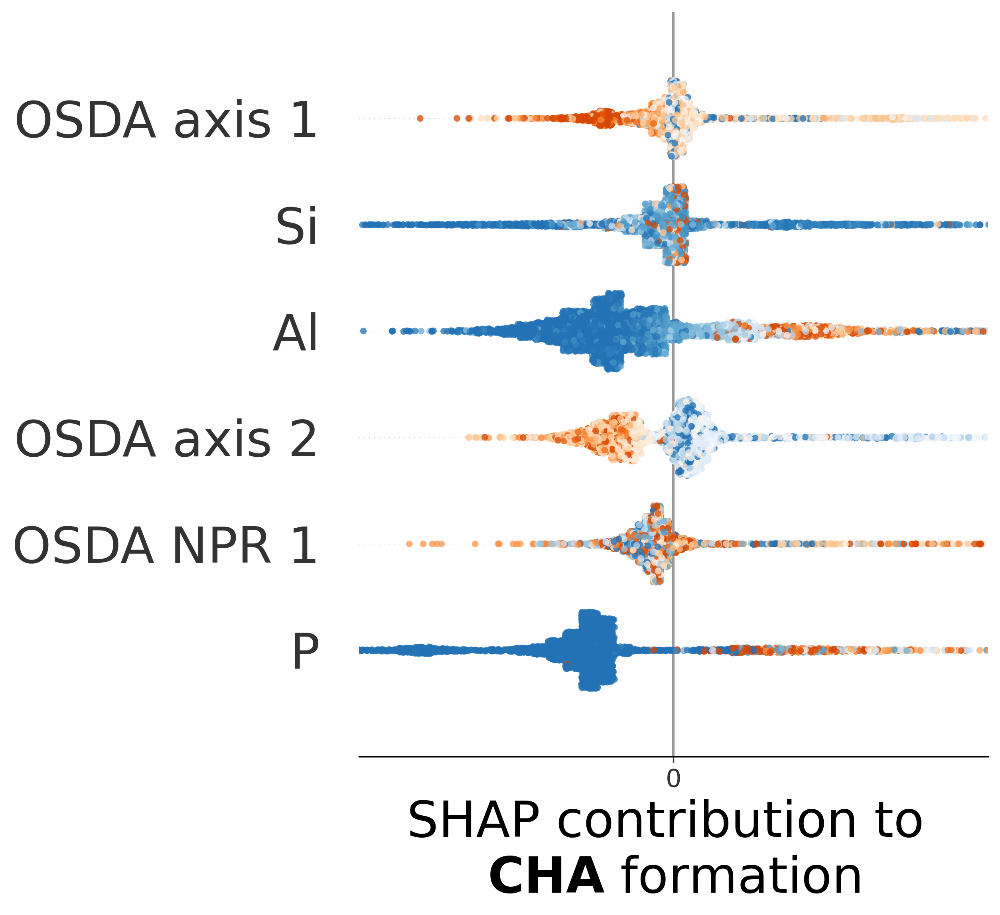

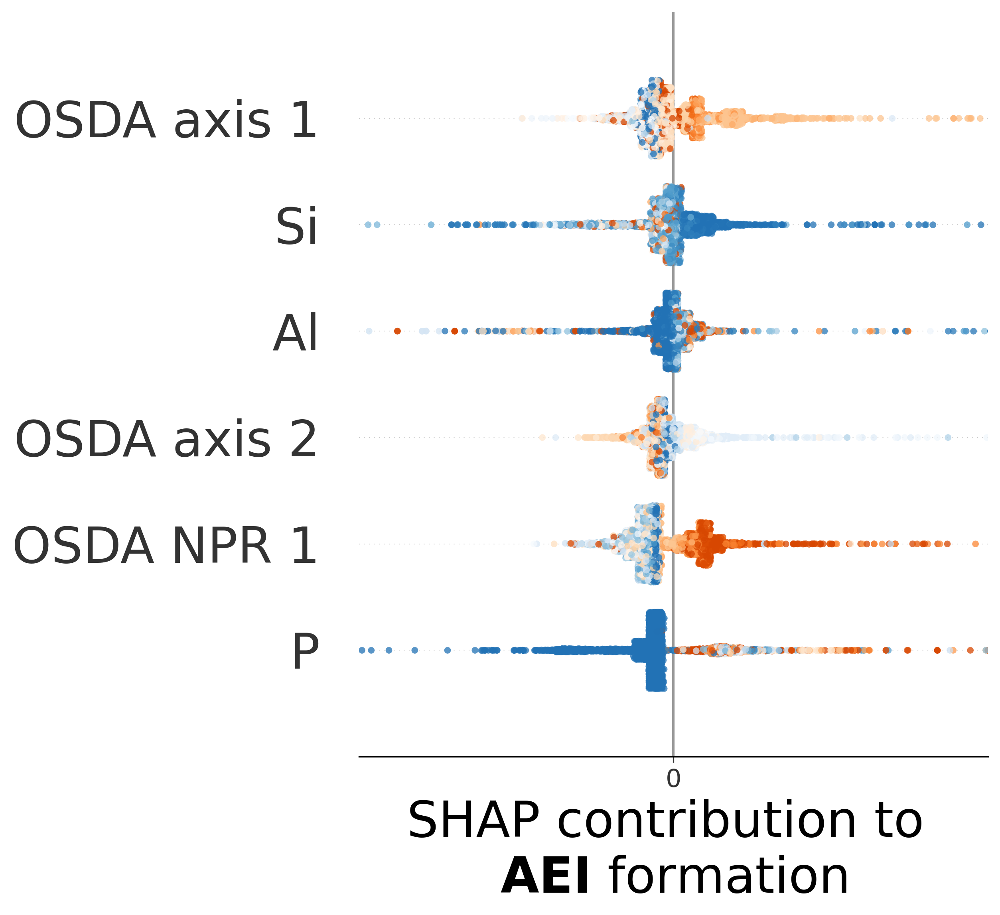

['MOR', 'MFI', 'MOR/MFI']


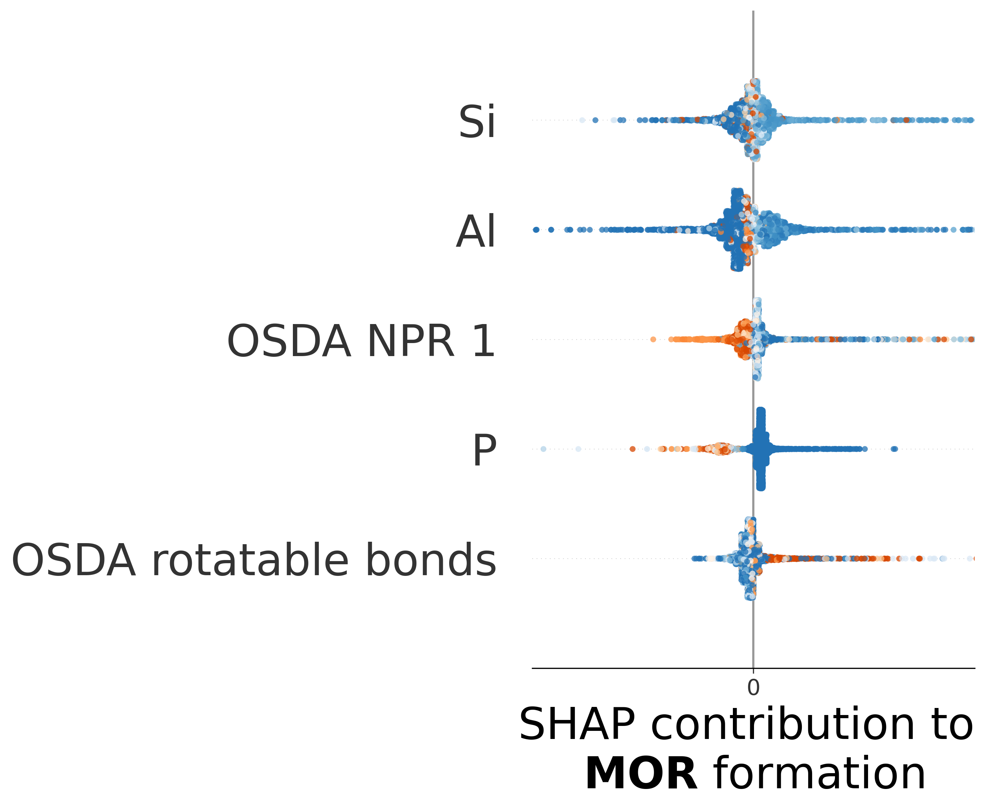

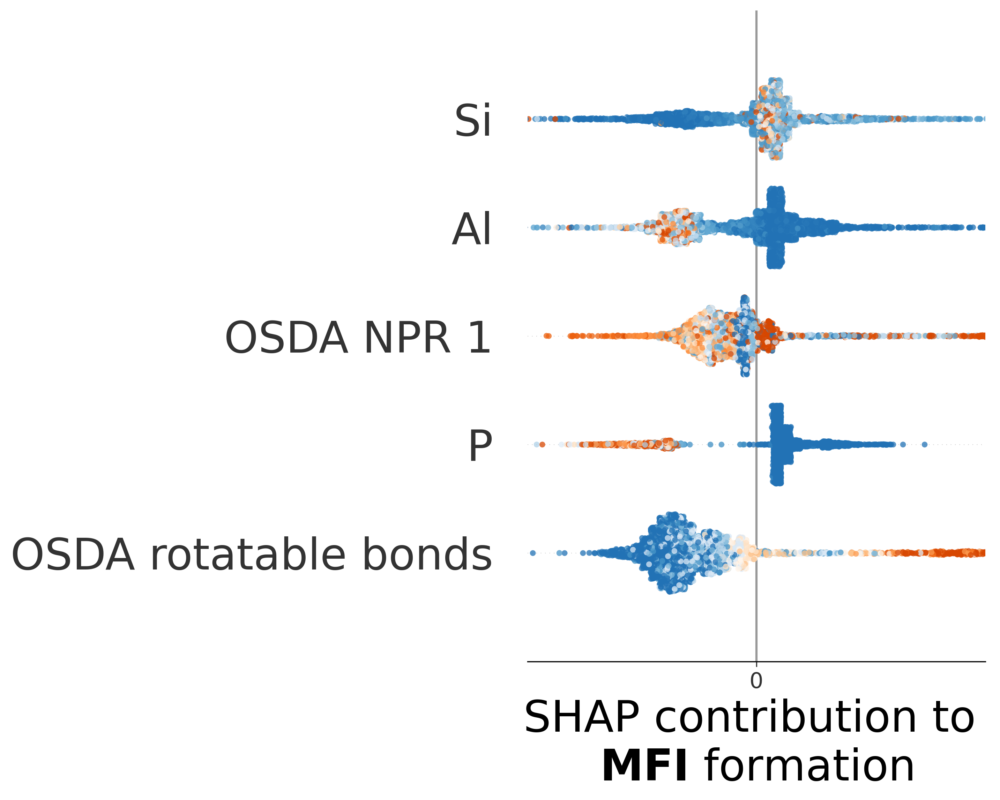

['AEI', 'CHA', 'AEI/CHA']


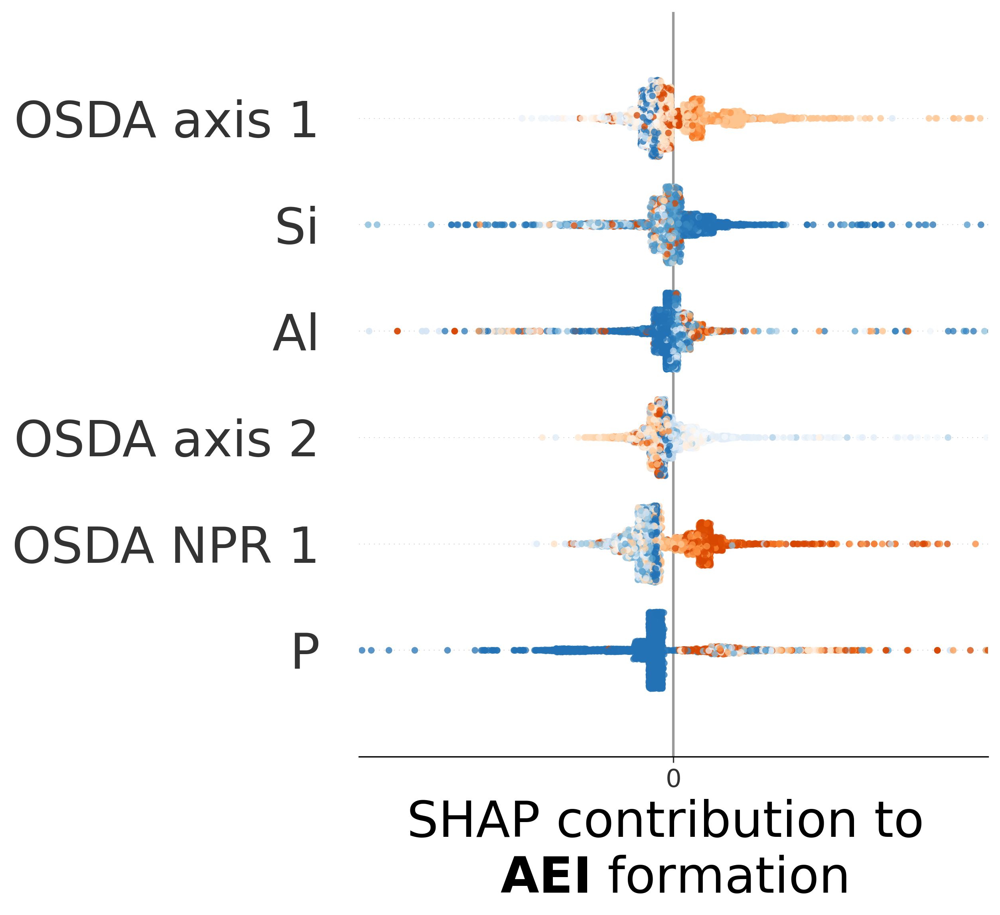

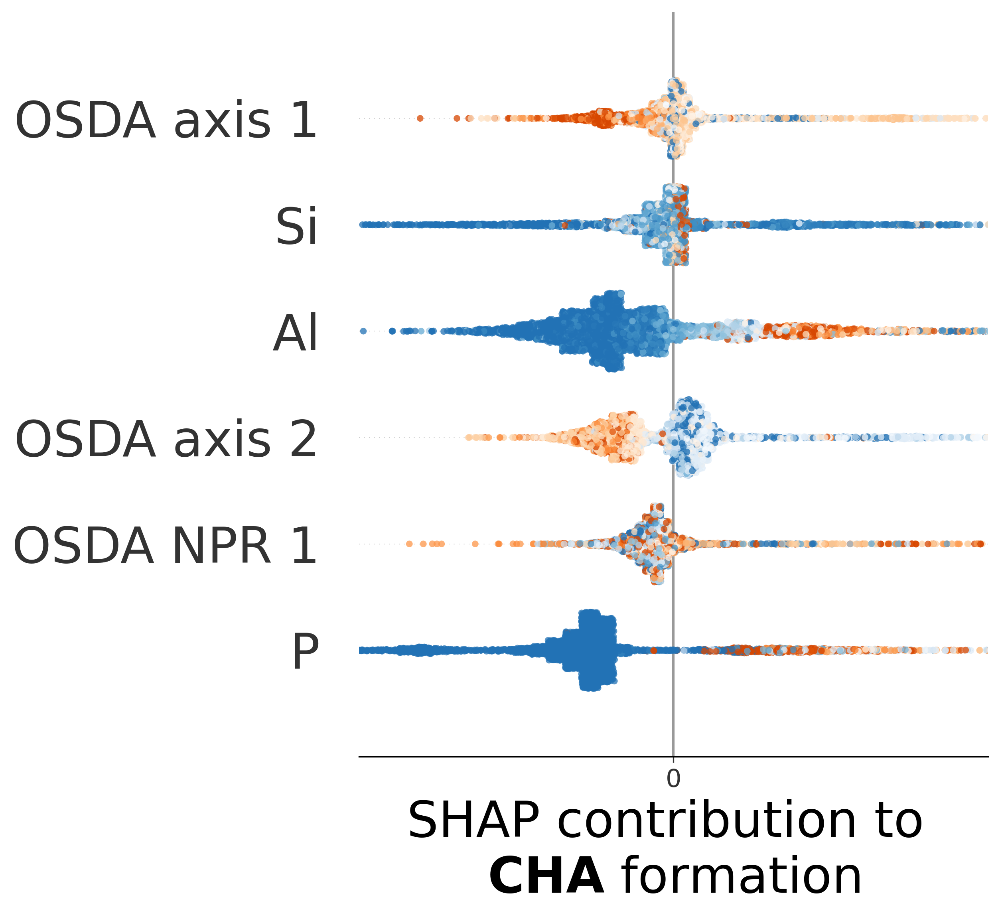

['RUT', 'RTH', 'RUT/RTH']


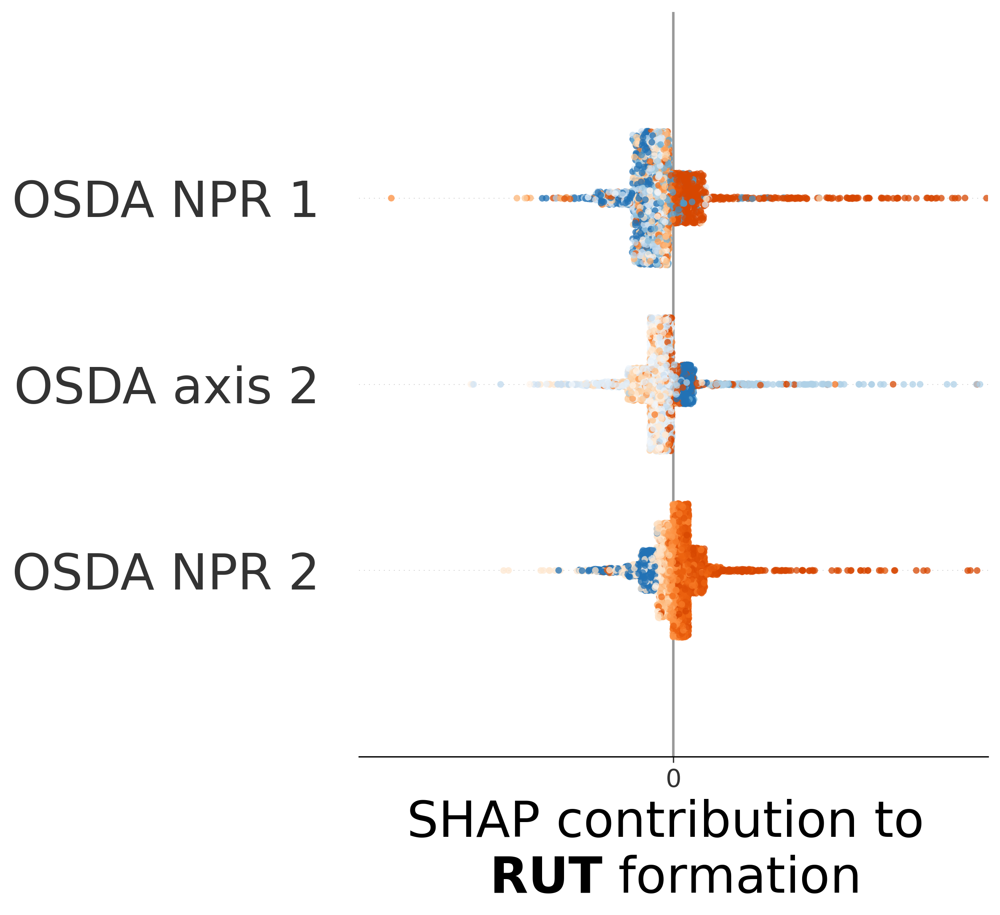

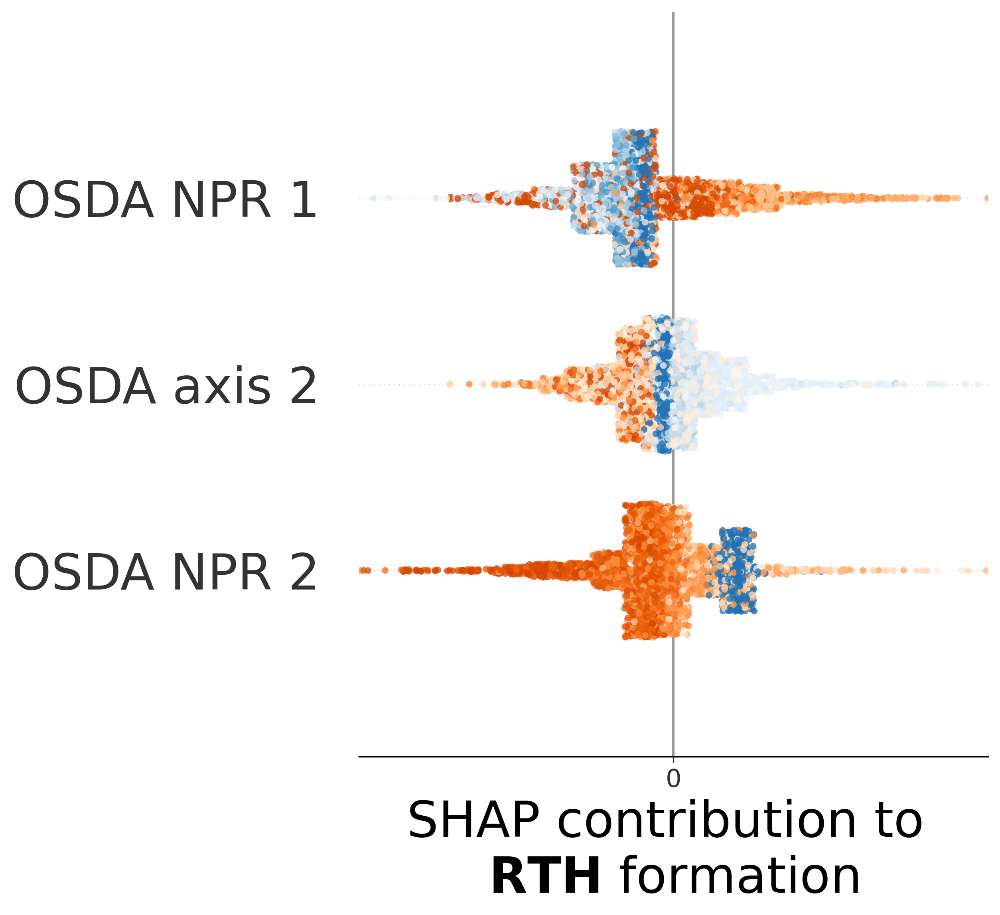

In [34]:
for ig in igs:
    z1, z2 = ig.split('/')
    
    print([z1, z2, ig])
    
    try:
        # Get common top SHAP features for each framework
        z1z2_top_shap_feats = []
        for z in [z1, z2]:
            top_shap_feats = plot_zeo_shap(z, cols = X_cols.values(), cmap = cmap, alpha = 0.75, max_display = 10, plot_size = (7,7), xlabel_size = 30, color_bar = False,
                         return_top_shap_feats = True) # return only top SHAP features
            z1z2_top_shap_feats.append(set(top_shap_feats))
        z1_tsf, z2_tsf = z1z2_top_shap_feats 
        common_top_shap_feats = z1_tsf.intersection(z2_tsf) # Common top SHAP features between two frameworks


        # Plot framework SHAP with only with common SHAP features
        for z in [z1, z2]:
            plot_zeo_shap(z, cols = common_top_shap_feats, cmap = cmap, alpha = 0.75, max_display = 10, plot_size = (7,7), xlabel_size = 30, color_bar = False,
                             sort = False # turn off sort to get feature order as per "cols" argument
                             )      
    except Exception as e:
        print(e)
    
    print('='*50)
    

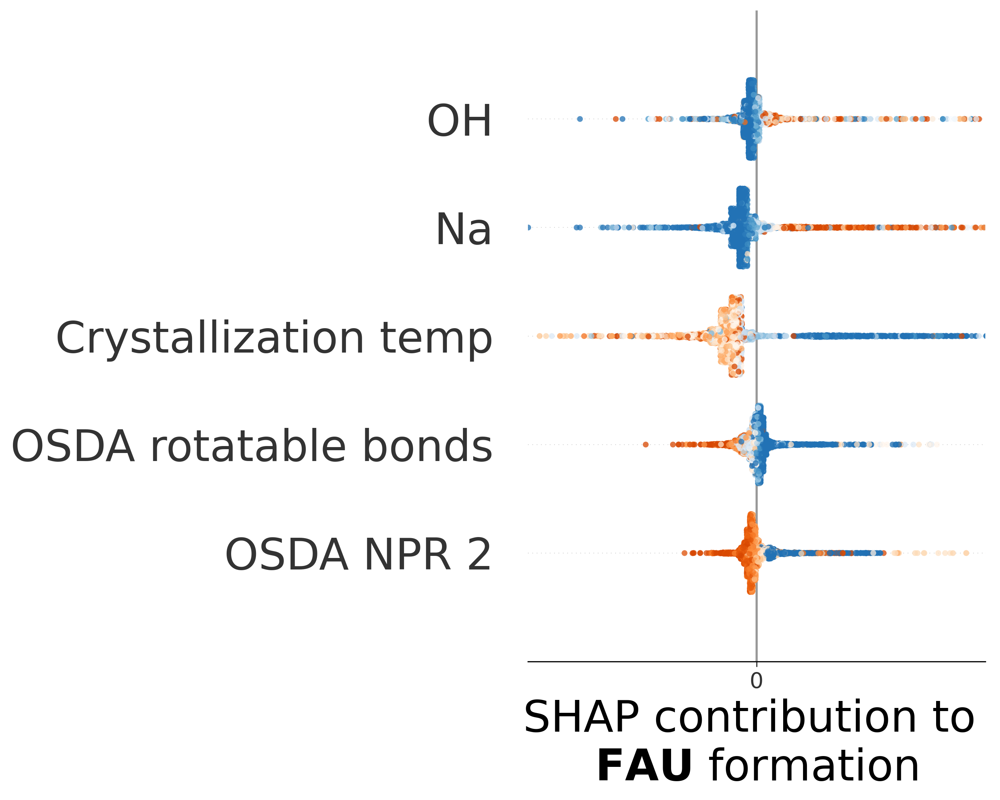

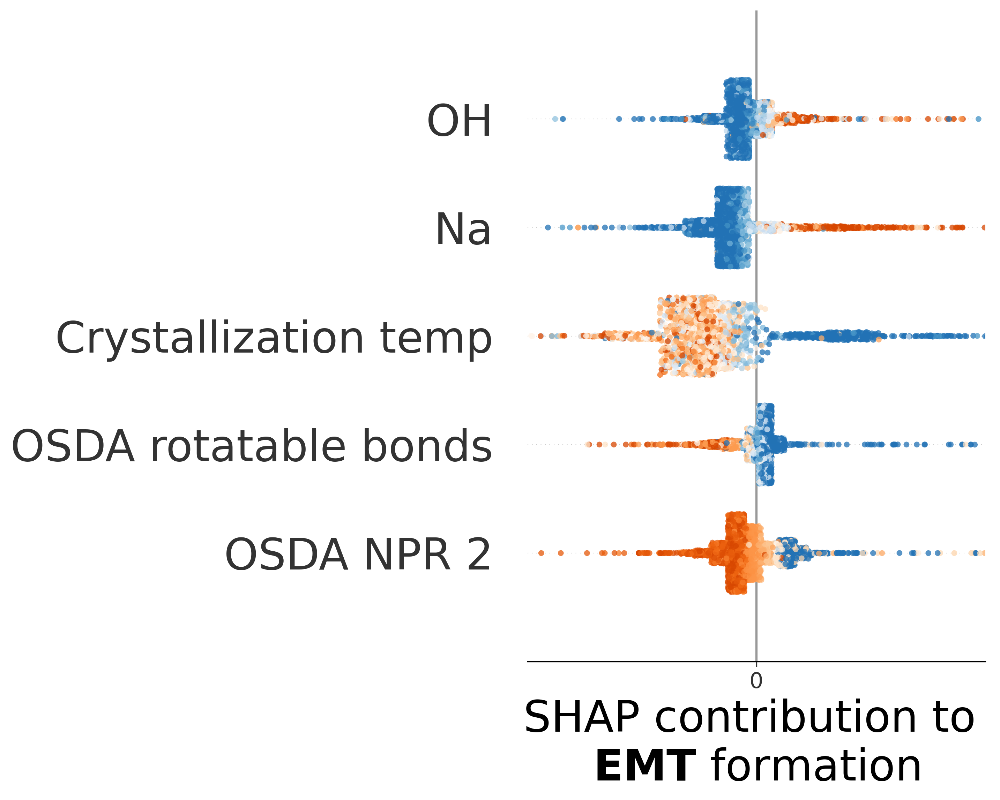

In [35]:
# Intergrowth: FAU & EMT

cols = [
        'OH', 
        'Na', 
        'Crystallization temp', 
        'OSDA rotatable bonds', 
        'OSDA NPR 2', 
       ]

for z in ['FAU', 'EMT']:
    plot_zeo_shap(z, cols = cols, cmap = cmap, alpha = 0.75, max_display = 10, plot_size = (7,7), xlabel_size = 30, color_bar = False,
                  sort = False # turn off sort to get feature order as per "cols" argument
                         )

In [36]:
# OSDA used in intergrowth case study
df_osda[df_osda['osda smiles'] == 'C1COCCOCCOCCOCCOCCO1']['num_rot_bonds_mean_0']

64    0
Name: num_rot_bonds_mean_0, dtype: int64

## CBU-level SHAP

In [37]:
df_zeos['cbu'] = list(map(clean_cbus, df_zeos['cbu'].values))
df_zeos['Code'] = df_zeos['Code'].apply(rename_disordered_interrupted)

In [38]:
# Find unique set of cbus present in dataset
cbus_unique = []
for cbu_combination in df_zeos['cbu'].value_counts().index:
    for cbu in cbu_combination:
        if cbu not in cbus_unique:
            cbus_unique.append(cbu)

# Get one-hot encoding of cbus
cbu_oh = np.zeros([len(df_zeos), len(cbus_unique)]) # initialize one-hot encoding with zeros
cbu_oh = pd.DataFrame(cbu_oh, columns = cbus_unique, index = df_zeos.index)

for idx in df_zeos.index:
    cbus = df_zeos.loc[idx]['cbu']

    if (cbus == None) or (len(cbus) == 0): # either None or empty list
        pass
    elif (len(cbus) > 0) and (type(cbus) == list): # if non-empty list of cbus exists 

        for cbu in cbus: # modify one-hot encoding of cbus
            cbu_oh.loc[idx, cbu] = 1.0

# append one-hot encoding of CBUs to df_zeos
df_zeos = pd.concat([df_zeos, cbu_oh], axis = 1)

In [39]:
def plot_cbu_shap(cbu, cols, max_display = 5, plot_size = (8,5), xlim = None, alpha = 0.1, cmap = 'coolwarm', xlabel_size = None, color_bar = True, sort = True, return_top_shap_feats = False, savepath = None):
    '''
    Plots SHAP plot for a specific composite building unit (CBU)
    
    Args:
    cbu: CBU 3-letter code
    cols: synthesis feature columns to consider
    '''
    
    # Construct SHAP matrix for a specific CBU

    zeos_with_cbu = []
    zeos_wo_cbu = []
    zeo_idxs = []
    zeo_wo_idxs = []
    for zeo in df_zeos['Code']:
        if (zeo in model.classes_):
            if (df_zeos[df_zeos['Code'] == zeo][cbu] == 1.).item(): # if CBU present
                zeo_idx = np.where(model.classes_ == zeo)[0][0]
                zeo_idxs.append(zeo_idx)
                zeos_with_cbu.append(zeo)

            else: # else CBU not present
                zeo_idx = np.where(model.classes_ == zeo)[0][0]
                zeo_wo_idxs.append(zeo_idx)
                zeos_wo_cbu.append(zeo)


    cbu_shap = [pd.DataFrame(shap_values_masked[zeo_idx], columns = X_cols.values())[cols] for zeo_idx in zeo_idxs] # Get SHAP values for zeos with this CBU
    cbu_not_present_shap = [pd.DataFrame(shap_values_masked[zeo_wo_idx], columns = X_cols.values())[cols] for zeo_wo_idx in zeo_wo_idxs] # Get SHAP values for zeos without this CBU

    sum_shap = np.zeros_like(cbu_shap[0]) # Initialize final SHAP matrix

    for m in cbu_shap: # Add up SHAP matrices contributing to a specific CBU
        sum_shap += m

    # Summary plot
    plt.figure(dpi = 300)
    shap.summary_plot(np.array(sum_shap), 
                      X_test_masked[cols],
                    max_display = max_display,
                    cmap = cmap, show = False, alpha = alpha, color_bar_label='Synthesis parameter',
                    plot_size = plot_size,
                    color_bar = color_bar,
                    sort = sort,
                      
                     )
    fig, ax = plt.gcf(), plt.gca()
    
    top_shap_feat = ax.get_yticklabels()[-1].get_text() # str of feature name
    top_shap_feat_ub = np.quantile(sum_shap[top_shap_feat], 0.99)*1.2 # upper
    top_shap_feat_lb = np.quantile(sum_shap[top_shap_feat], 0.01)*1.2 # lower
    
    ax.set_xlabel('SHAP contribution to \n $\it{' + cbu + '}$ formation', fontsize = xlabel_size)
    plt.xticks(fontsize=15)
    
    if xlabel_size != None:
        ax.tick_params(axis='y', which='major', labelsize=xlabel_size)
        
    if xlim != None:
        ax.set_xlim(*xlim)
    else:
        ax.set_xlim(-max([top_shap_feat_ub, top_shap_feat_lb]), max([top_shap_feat_ub, top_shap_feat_lb]))
    
    plt.xticks([0.])
    
    if savepath != None:
        plt.savefig(savepath, dpi = 200)
    
    if return_top_shap_feats: # return a list of top SHAP features
        top_shap_feats = [ax.get_yticklabels()[-i].get_text() for i in range(max_display)]
        plt.close(fig)
        return top_shap_feats
    else:
        plt.show()

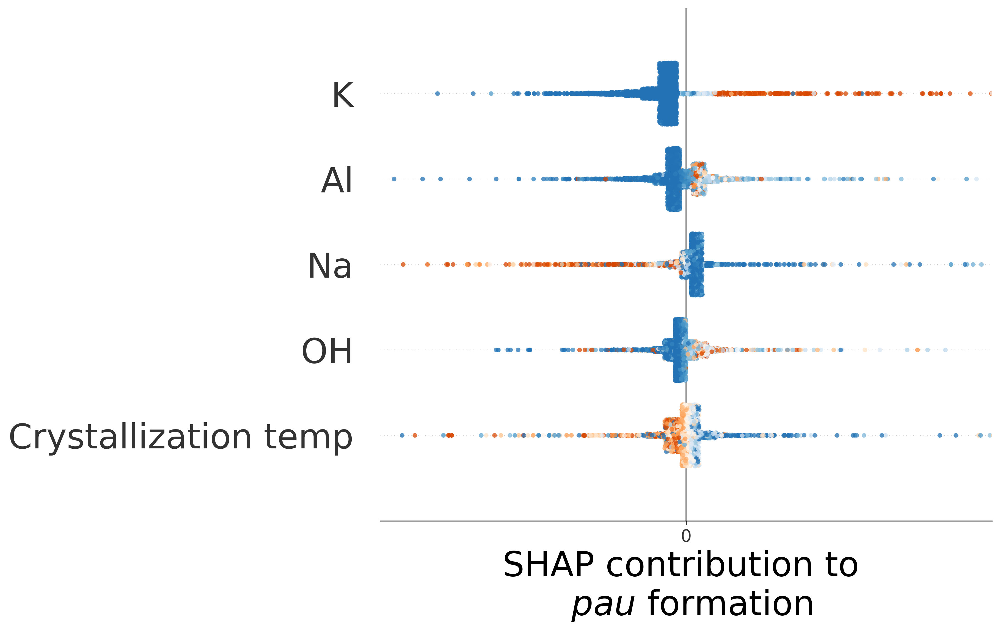

In [40]:
# CBU-level SHAP example
plot_cbu_shap('pau', cols = X_cols.values(), cmap = cmap, alpha = 0.75, max_display = 5, plot_size = (10,7), xlabel_size = 30, color_bar = False
             )

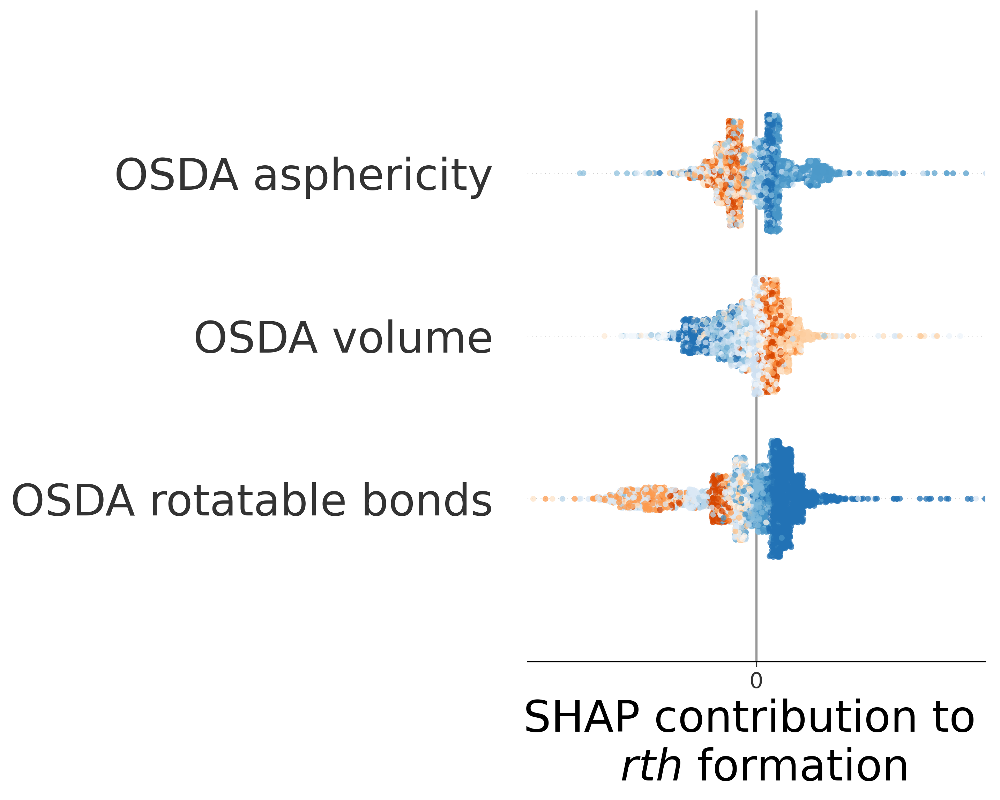

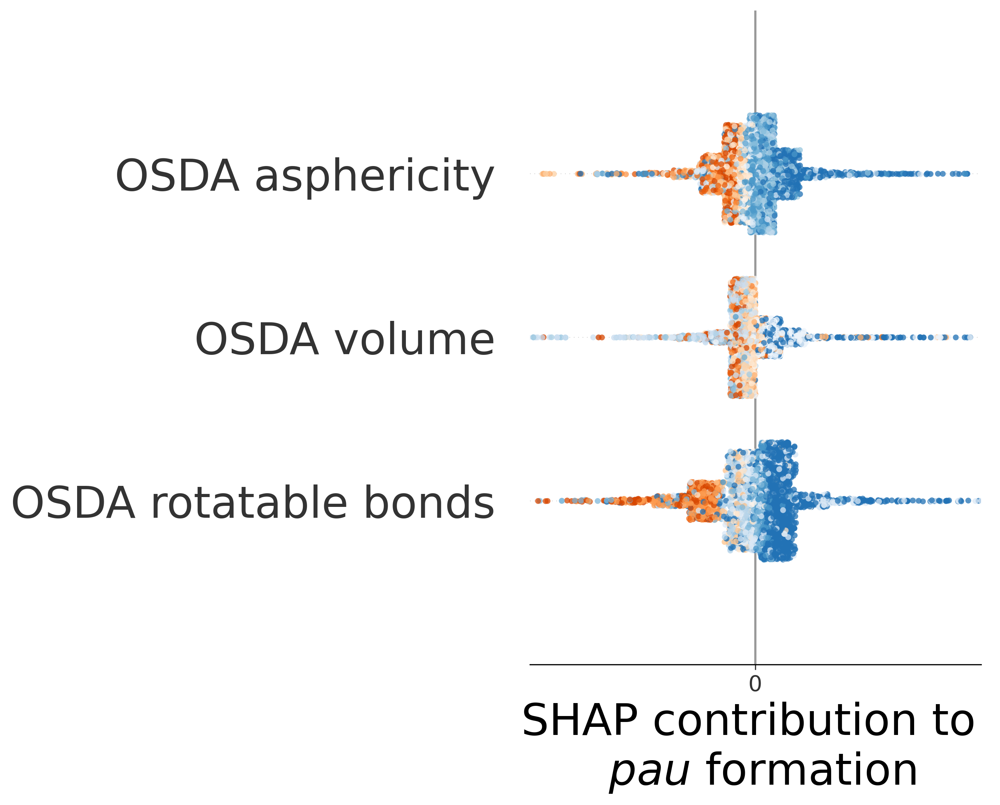

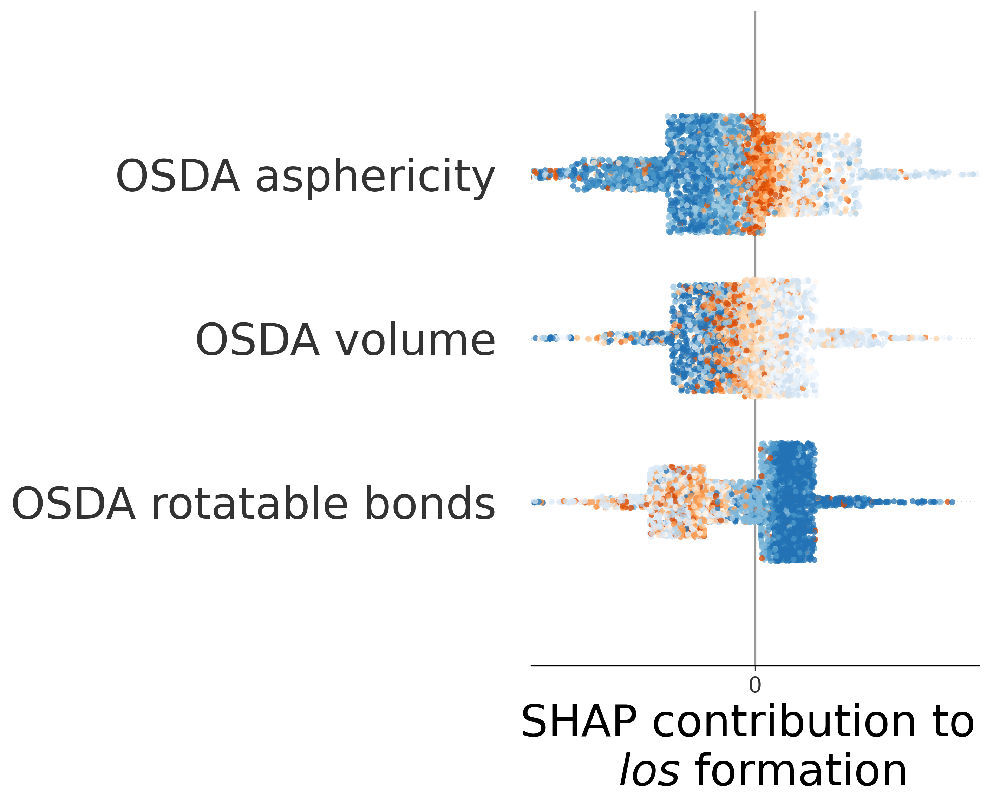

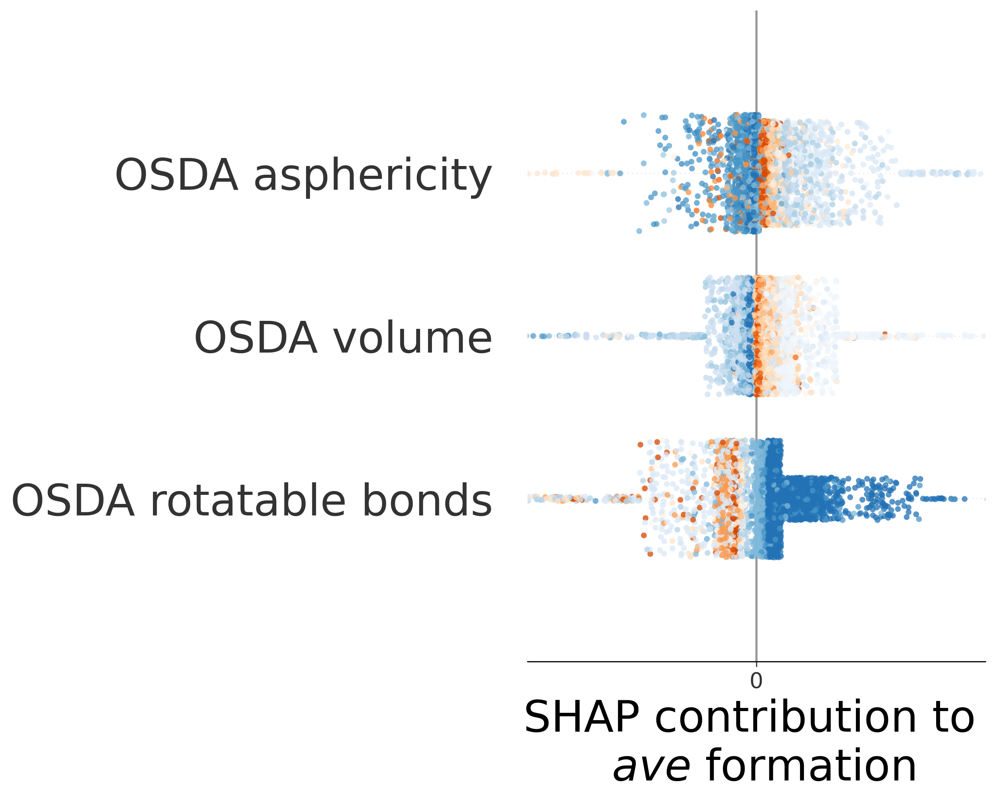

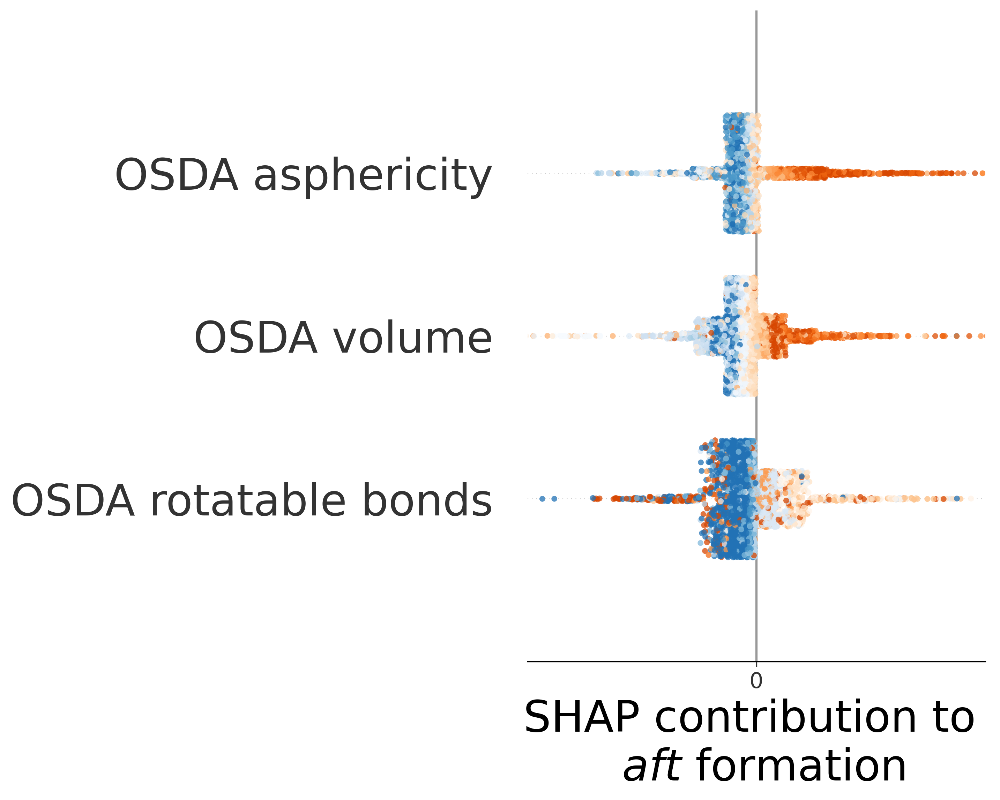

In [41]:
# Plot select large CBUs

# cols = [x for x in X_cols.values() if 'OSDA' in x]
cols = ['OSDA asphericity', 
        'OSDA volume',
        'OSDA rotatable bonds',
       ]

# plot_cbu_shap('lta', cols = cols, cmap = cmap, alpha = 0.75, max_display = 10, plot_size = (7,7), xlabel_size = 30, color_bar = False,
#              sort = False)

plot_cbu_shap('rth', cols = cols, cmap = cmap, alpha = 0.75, max_display = 10, plot_size = (7,7), xlabel_size = 30, color_bar = False,
             sort = False)

plot_cbu_shap('pau', cols = cols, cmap = cmap, alpha = 0.75, max_display = 10, plot_size = (7,7), xlabel_size = 30, color_bar = False,
             sort = False)

plot_cbu_shap('los', cols = cols, cmap = cmap, alpha = 0.75, max_display = 10, plot_size = (7,7), xlabel_size = 30, color_bar = False,
             sort = False)

plot_cbu_shap('ave', cols = cols, cmap = cmap, alpha = 0.75, max_display = 10, plot_size = (7,7), xlabel_size = 30, color_bar = False,
             sort = False)

plot_cbu_shap('aft', cols = cols, cmap = cmap, alpha = 0.75, max_display = 10, plot_size = (7,7), xlabel_size = 30, color_bar = False,
             sort = False)

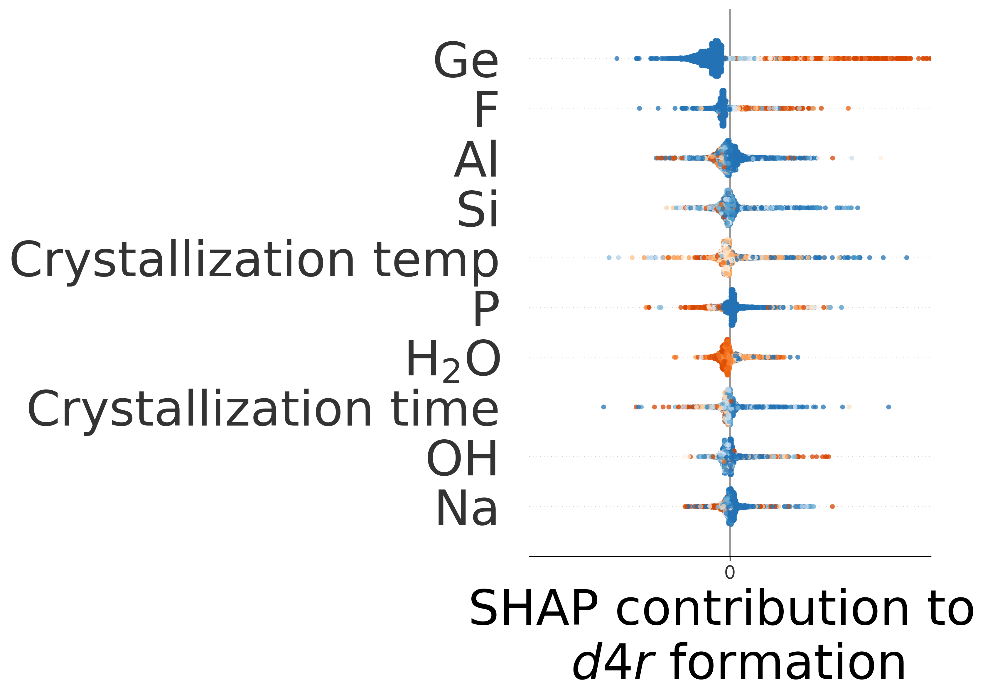

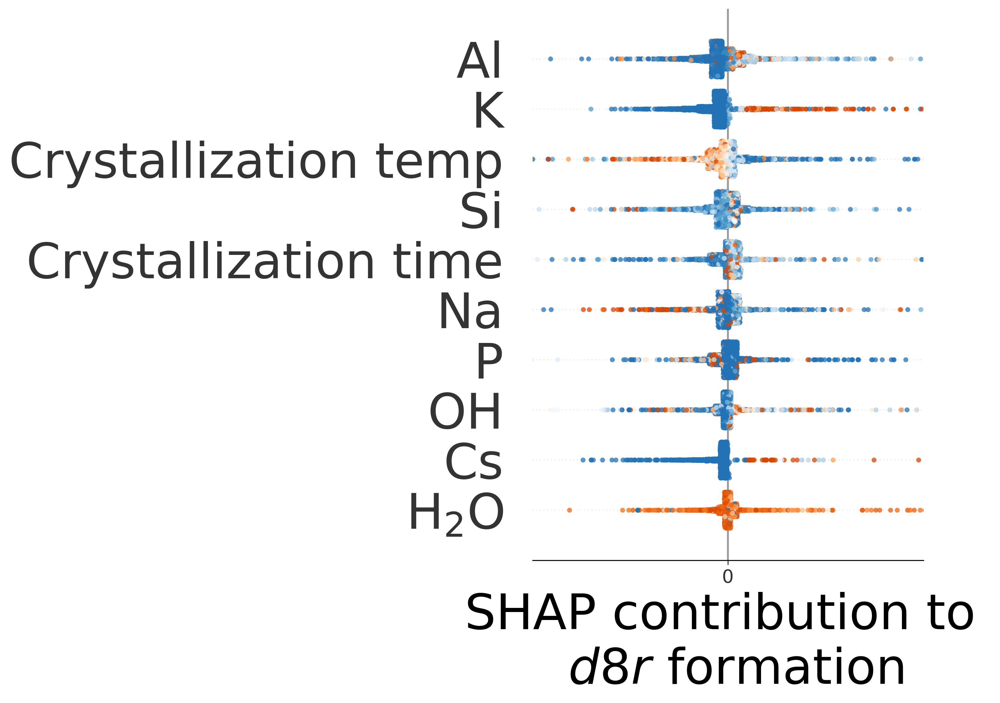

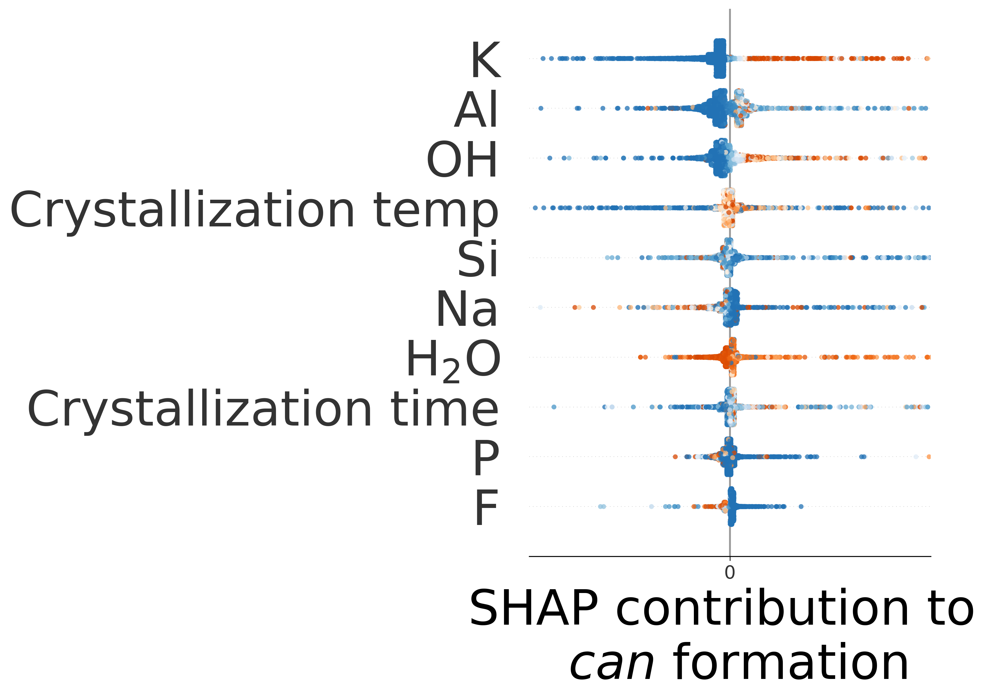

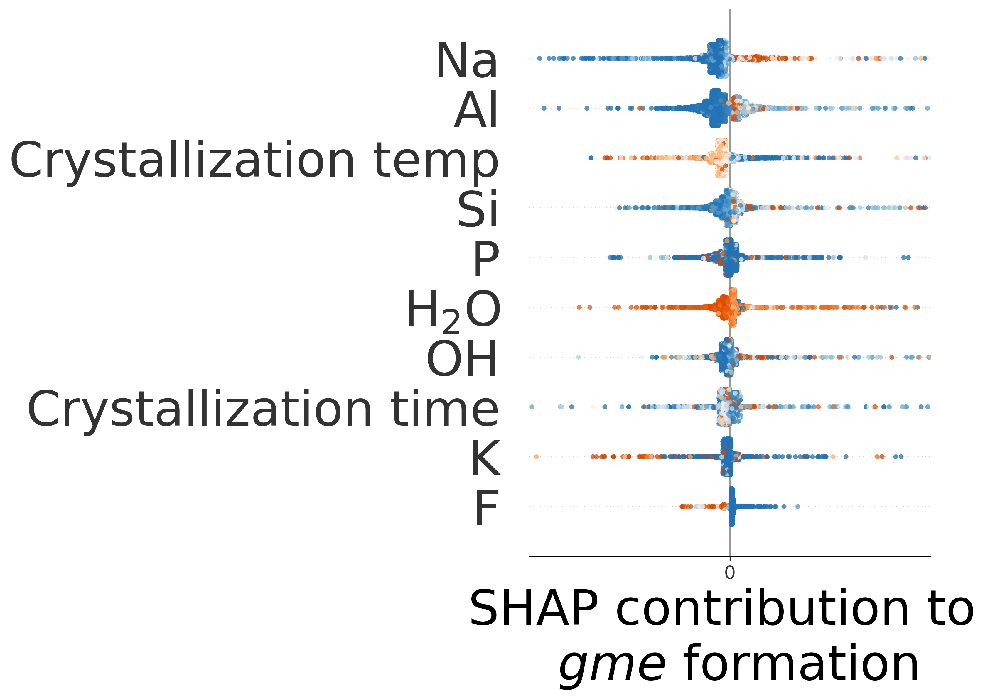

In [42]:
# Plot select small CBUs
cols = [x for x in X_cols.values() if 'OSDA' not in x]

plot_cbu_shap('d4r', cols = cols, cmap = cmap, alpha = 0.75, max_display = 10, plot_size = (7,7), xlabel_size = 40, color_bar = False,
             )

plot_cbu_shap('d8r', cols = cols, cmap = cmap, alpha = 0.75, max_display = 10, plot_size = (7,7), xlabel_size = 40, color_bar = False,
             )

plot_cbu_shap('can', cols = cols, cmap = cmap, alpha = 0.75, max_display = 10, plot_size = (7,7), xlabel_size = 40, color_bar = False,
             )

plot_cbu_shap('gme', cols = cols, cmap = cmap, alpha = 0.75, max_display = 10, plot_size = (7,7), xlabel_size = 40, color_bar = False,
             )

# Generate SHAP for all CBUs

In [43]:
# # Save SHAP plots for small CBUs into cbu/small_cbu_shap/ folder
# for cbu in small_cbus:
#     try:
#         plot_cbu_shap(cbu, cols = X_cols.values(), cmap = cmap, alpha = 0.75, max_display = 10, plot_size = (4,3), xlabel_size = 10, color_bar = False, savepath = f"cbu/small_cbu_shap/{cbu}.png")
#     except:
#         print('cbu not present')
        
# # Save SHAP plots for large CBUs into cbu/large_cbu_shap/ folder
# for cbu in large_cbus:
#     try:
#         plot_cbu_shap(cbu, cols = X_cols.values(), cmap = cmap, alpha = 0.75, max_display = 10, plot_size = (4,3), xlabel_size = 10, color_bar = False, savepath = f"cbu/large_cbu_shap/{cbu}.png")
#     except:
#         print('cbu not present')

In [44]:
# Small CBUs
fig = plt.figure(figsize = (20,30), dpi = 400)
idx = 1
for cbu in small_cbus:
    shap_path = f"cbu/small_cbu_shap/{cbu}.png"
    cbu_path  = f"cbu/{cbu}.jpg"
    if os.path.isfile(shap_path):
        shap_img = iio.imread(shap_path)
        shap_img = shap_img[:, int(0.060*shap_img.shape[0]):, :]
        cbu_img  = iio.imread(cbu_path)
        
        aspect_ratio  = cbu_img.shape[0]/cbu_img.shape[1] # Width/Height
        fig.add_subplot(8,5,idx)
        
        size = 0.35 # size of cbu image
        loc  = [0.75, 0.85] # x,y coordinates of centre of image
        
        plt.imshow(shap_img, extent = [-0.1, 1, 0.02, 0.75], interpolation='none')
        plt.imshow(cbu_img,  extent = [loc[0]-size/2, loc[0]+size/2, loc[1]-size/2*aspect_ratio, loc[1]+size/2*aspect_ratio], interpolation='none')
        
        ax = fig.gca()
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['bottom'].set_visible(False)
        ax.spines['left'].set_visible(False)
        ax.get_xaxis().set_ticks([])
        ax.get_yaxis().set_ticks([])
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        
        idx+=1
        
plt.subplots_adjust(left=0.0,
                    bottom=0.0, 
                    right=1.0, 
                    top=1.0, 
                    wspace=-0.1, 
                    hspace=0.0)
plt.savefig('figures/small_cbu_shap.pdf', dpi = 500)
plt.show()

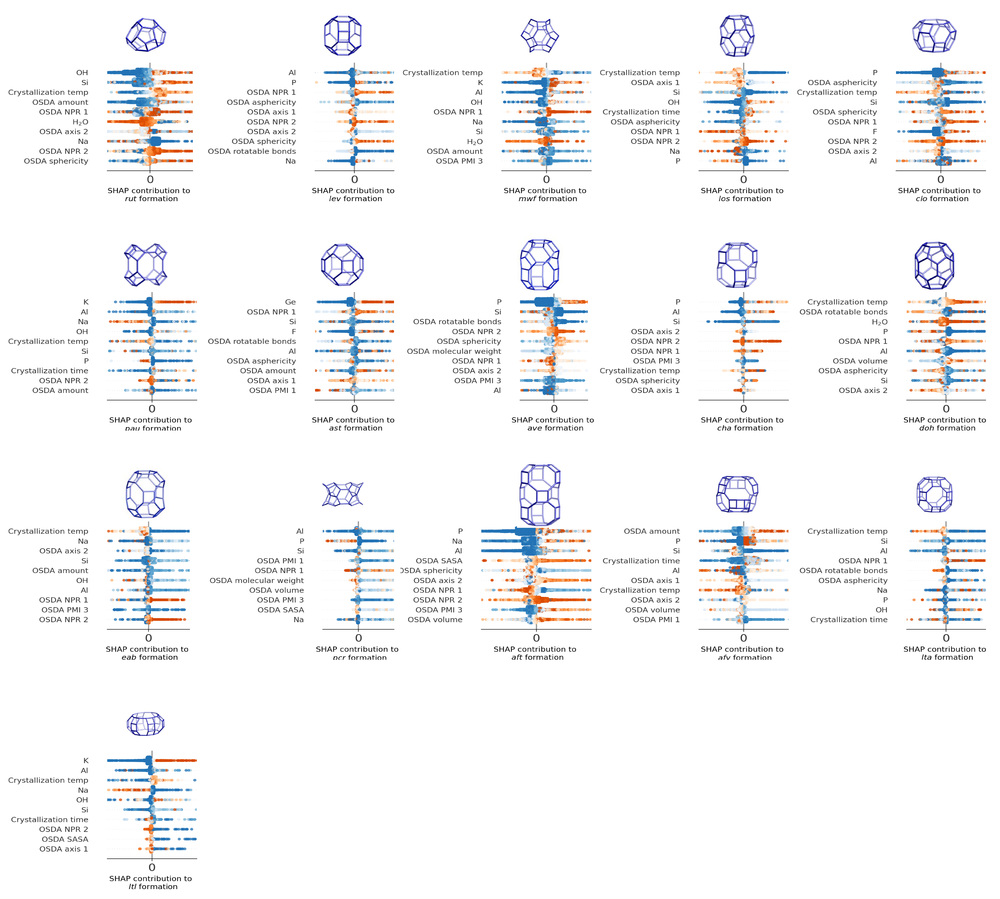

In [45]:
# Large CBUs
fig = plt.figure(figsize = (20,15), dpi = 400)
idx = 1
for cbu in large_cbus:
    shap_path = f"cbu/large_cbu_shap/{cbu}.png"
    cbu_path  = f"cbu/{cbu}.jpg"
    if os.path.isfile(shap_path):
        shap_img = iio.imread(shap_path)
        shap_img = shap_img[:, int(0.06*shap_img.shape[0]):, :]
        cbu_img  = iio.imread(cbu_path)
        
        aspect_ratio  = cbu_img.shape[0]/cbu_img.shape[1] # Width/Height
        fig.add_subplot(4,5,idx)
        
        size = 0.23 # size of cbu image
        loc  = [0.70, 0.85] # x,y coordinates of centre of image
        
        plt.imshow(shap_img, extent = [-0.1, 1, 0.02, 0.75], interpolation='none')
        plt.imshow(cbu_img,  extent = [loc[0]-size/2, loc[0]+size/2, loc[1]-size/2*aspect_ratio, loc[1]+size/2*aspect_ratio], interpolation='none')
        
        ax = fig.gca()
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['bottom'].set_visible(False)
        ax.spines['left'].set_visible(False)
        ax.get_xaxis().set_ticks([])
        ax.get_yaxis().set_ticks([])
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        
        idx+=1
        
plt.subplots_adjust(left=0.0,
                    bottom=0.0, 
                    right=1.0, 
                    top=1.0, 
                    wspace=-0.5, 
                    hspace=0.15)
plt.savefig('figures/large_cbu_shap.pdf', dpi = 500)
plt.show()